Measure the gap between the average head and the head in the wells for different pumping rates and different settings.

In [1]:
from typing import List
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
from tqdm import trange
import copy

import cvxpy as cp
import gurobipy as gp

from Components.RecedingHorizon import RecedingHorizon
from Components.System import SimpleSquareExample
from Components.Model import IrrigationSchedulingModel, IrrigationSchedulingCost
from Components.Controllers import TimeVaryingCost_LQRc_RHG, LQRc_welfare
from Components.Solver import fbrs

In [2]:
# Reload scripts when executed
%load_ext autoreload
%autoreload 2

np.set_printoptions(linewidth=np.inf)

In [383]:
parameter_file = "run_data/run_20250625-171059/model_parameters.json"

In [384]:
# Example crop repartition
crops = np.array([[0.5, 0.8, 0.3], [0., 0.2, 0.3], [0.4, 0., 0.3], [0., 0., 0.4]])

In [385]:
# Initialize System and Model
system = SimpleSquareExample(parameter_file, boundary_condition="Constant Head")
model = IrrigationSchedulingModel(parameter_file, boundary_condition="Constant Head")
cost_model = IrrigationSchedulingCost(parameter_file, model, crops)

In [386]:
# Initialize Controller
controller = TimeVaryingCost_LQRc_RHG(
    parameter_file,
    model.A.toarray(), [B.toarray() for B in model.B_v], model.C,
    model.H_x, model.h_x, model.H_u_v, model.h_u_v,
    model.H_xu_x, model.H_xu_u, model.h_xu,
    solver='fbrs'
)

In [387]:
# Transform into welfare controller
welfare = LQRc_welfare(controller)

In [388]:
water_req = cost_model._get_water_requirement(0, 365)
under_irrigation_weight = cost_model._get_under_irrigation_weight(0, 365)

In [389]:
n_well = int(sum(np.hstack(model.n_well_per_command)))
well_to_agent = np.zeros((model.n_agent, n_well))
indices = np.array(list(zip(model.well_to_agent.tolist(), range(n_well)))).T
well_to_agent[indices[0, :], indices[1, :]] = 1

# Compare Welfare and Self-interested agents

In [390]:
data_si = np.load("run_data/run_20250625-171059/result_data.npz")
data_wf = np.load("run_data/run_20250626-122941/result_data.npz")

In [391]:
player_pumping_si = well_to_agent @ data_si['q_rates']
player_pumping_wf = well_to_agent @ data_wf['q_rates']
rain = cost_model._get_available_water(0, 365)

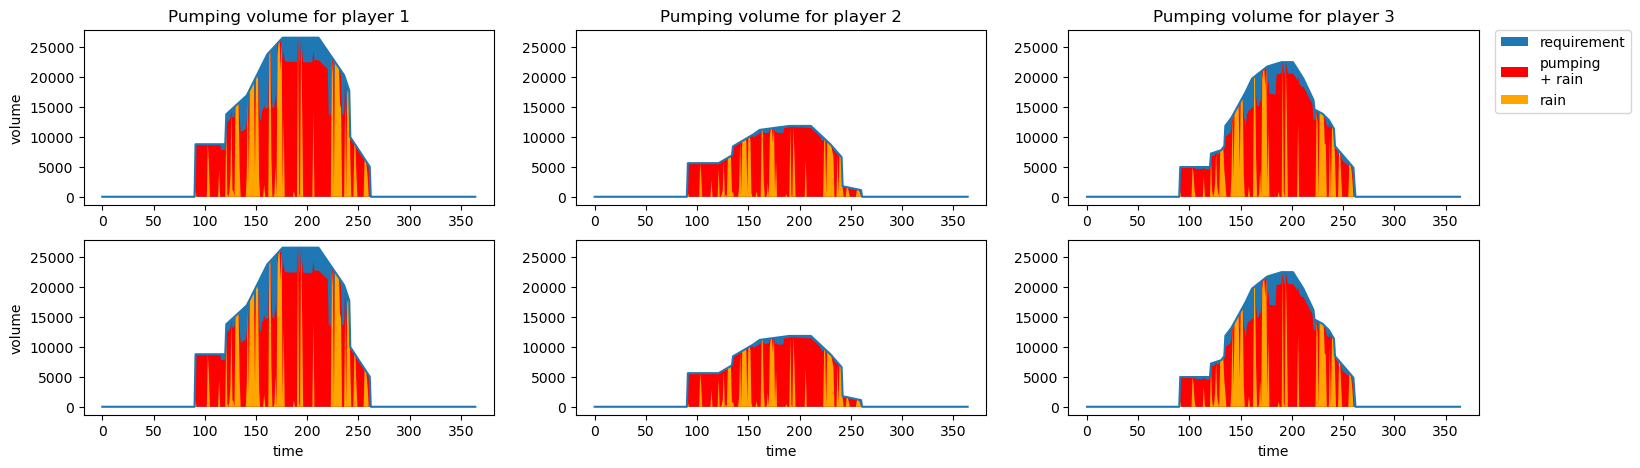

In [392]:
fig = plt.figure(figsize=(15+3,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(2, 3, ii+1, sharey=ax)
    ttl = f"Pumping volume for player {ii+1}"
    ax.set_title(ttl)
    if ii == 0:
        ax.set_ylabel("volume")
    ax.plot((water_req+rain)[ii, :, :].sum(axis=0))
    ax.fill((water_req+rain)[ii, :, :].sum(axis=0), label='requirement')
    ax.fill(-player_pumping_si[ii, :] + rain[ii,:,:].sum(axis=0), "r-", label='pumping\n+ rain')
    ax.fill(rain[ii,:,:].sum(axis=0), "orange", label='rain')
    if ii == 2:
        ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
    # Welfare
    ax = fig.add_subplot(2, 3, 3+ii+1, sharey=ax)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("volume")
    ax.plot((water_req+rain)[ii, :, :].sum(axis=0))
    ax.fill((water_req+rain)[ii, :, :].sum(axis=0))
    ax.fill(-player_pumping_wf[ii, :] + rain[ii,:,:].sum(axis=0), "r-")
    ax.fill(rain[ii,:,:].sum(axis=0), "orange")

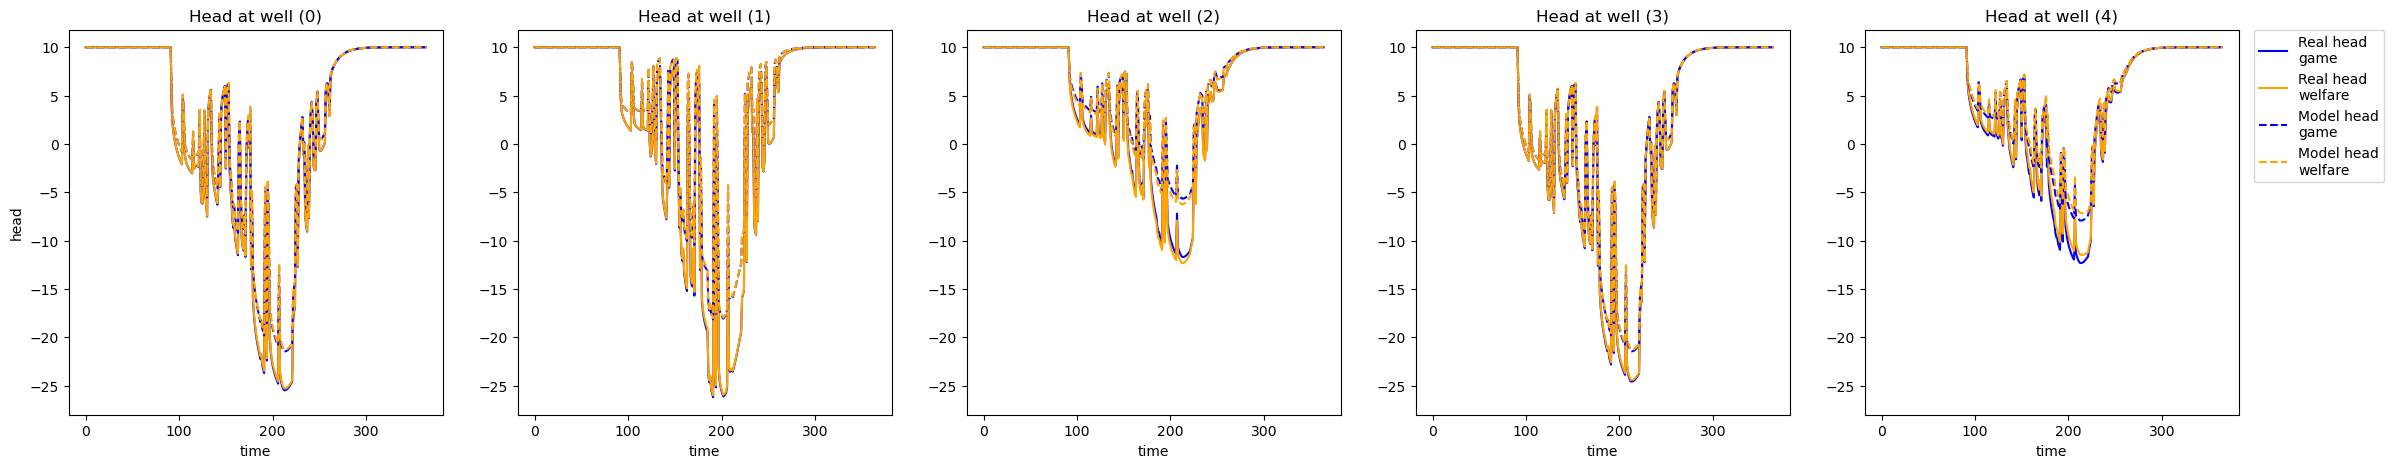

In [393]:
# Display heads evolution
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(5):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Head at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    ax_h.plot(data_si['h_wells'][ii, :], "b-", label="Real head\ngame")
    ax_h.plot(data_wf['h_wells'][ii, :], color="orange", label="Real head\nwelfare")
    ax_h.plot(data_si['corrected_h_wells'][ii, :], "b--", label="Model head\ngame")
    ax_h.plot(data_wf['corrected_h_wells'][ii, :], color="orange", linestyle="--", label="Model head\nwelfare")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

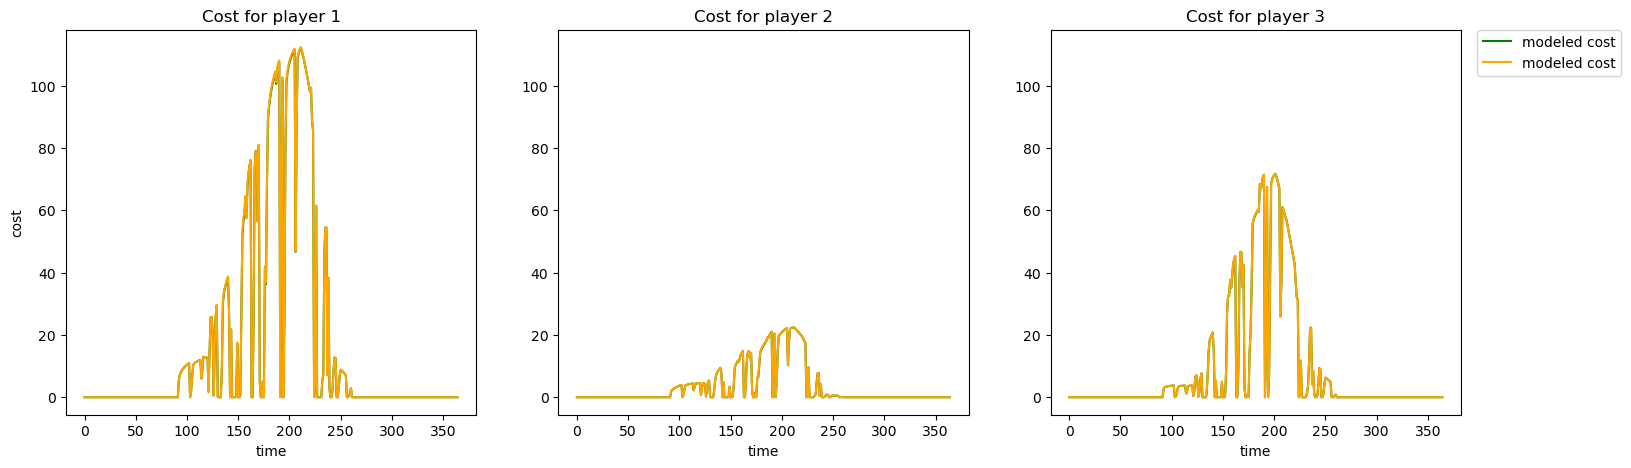

In [394]:
fig = plt.figure(figsize=(15+3,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Cost for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(-data_si['model_profit'][ii, :], 'g', label='modeled cost')
    ax.plot(-data_wf['model_profit'][ii, :], color="orange", label='modeled cost')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

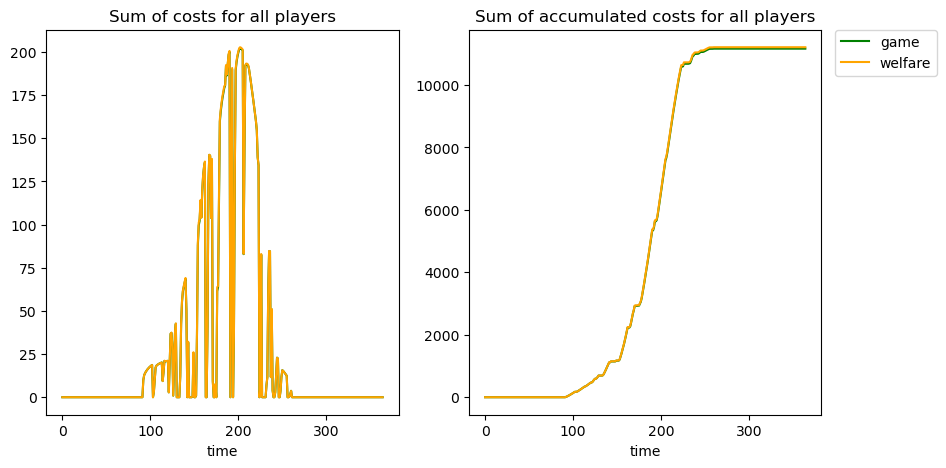

In [395]:
fig = plt.figure(figsize=(10,5))
ax = fig.add_subplot(1, 2, 1)
ttl = f"Sum of costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("cost")
ax.plot(-data_si['model_profit'].sum(axis=0), 'g')
ax.plot(-data_wf['model_profit'].sum(axis=0), color="orange")

ax = fig.add_subplot(1, 2, 2)
ttl = f"Sum of accumulated costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("cost")
ax.plot(-np.cumsum(data_si['model_profit'].sum(axis=0)), 'g', label='game')
ax.plot(-np.cumsum(data_wf['model_profit'].sum(axis=0)), color="orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

In [396]:
u_si = np.array([model.reorganize_input_per_well(data_si['inputs'][:,[k]]) for k in range(365)]).T
u_si = u_si.reshape((np.hstack(cost_model.n_well_per_command).sum(dtype=int), cost_model.n_crops, 365))
u_wf = np.array([model.reorganize_input_per_well(data_wf['inputs'][:,[k]]) for k in range(365)]).T
u_wf = u_wf.reshape((np.hstack(cost_model.n_well_per_command).sum(dtype=int), cost_model.n_crops, 365))

In [397]:
pumping_cost_si = np.zeros((cost_model.n_agent, 365))
under_irrigation_cost_si = np.zeros((cost_model.n_agent, 365))
pumping_cost_wf = np.zeros((cost_model.n_agent, 365))
under_irrigation_cost_wf = np.zeros((cost_model.n_agent, 365))
for v_1 in range(cost_model.n_agent):
    input_indices = np.nonzero(cost_model.well_to_cell[:,cost_model.well_to_agent==v_1].T)[1]
    well_index = np.arange(np.hstack(model.n_well_per_command).sum(), dtype=int)[model.well_to_agent==v_1]
    for t in range(364):
        pumping_cost_si[v_1,t] = (-cost_model.extraction_cost[v_1] * (cost_model.top_head[input_indices] -\
            data_si['h_wells'][[well_index], t+1].T) * u_si[cost_model.well_to_agent==v_1,:,t].sum(axis=1).reshape(-1,1)).sum()
        under_irrigation = water_req[v_1, :, t] + u_si[cost_model.well_to_agent==v_1,:,t].sum(axis=0)    # TODO: check dimensions
        under_irrigation_cost_si[v_1,t] = \
            under_irrigation.T @ sp.diags(under_irrigation_weight[v_1,:,t].flatten()) @ under_irrigation.T
        # Welfare costs
        pumping_cost_wf[v_1,t] = (-cost_model.extraction_cost[v_1] * (cost_model.top_head[input_indices] -\
            data_wf['h_wells'][[well_index], t+1].T) * u_wf[cost_model.well_to_agent==v_1,:,t].sum(axis=1).reshape(-1,1)).sum()
        under_irrigation = water_req[v_1, :, t] + u_wf[cost_model.well_to_agent==v_1,:,t].sum(axis=0)    # TODO: check dimensions
        under_irrigation_cost_wf[v_1,t] = \
            under_irrigation.T @ sp.diags(under_irrigation_weight[v_1,:,t].flatten()) @ under_irrigation.T
cost_si = pumping_cost_si + under_irrigation_cost_si
cost_wf = pumping_cost_wf + under_irrigation_cost_wf

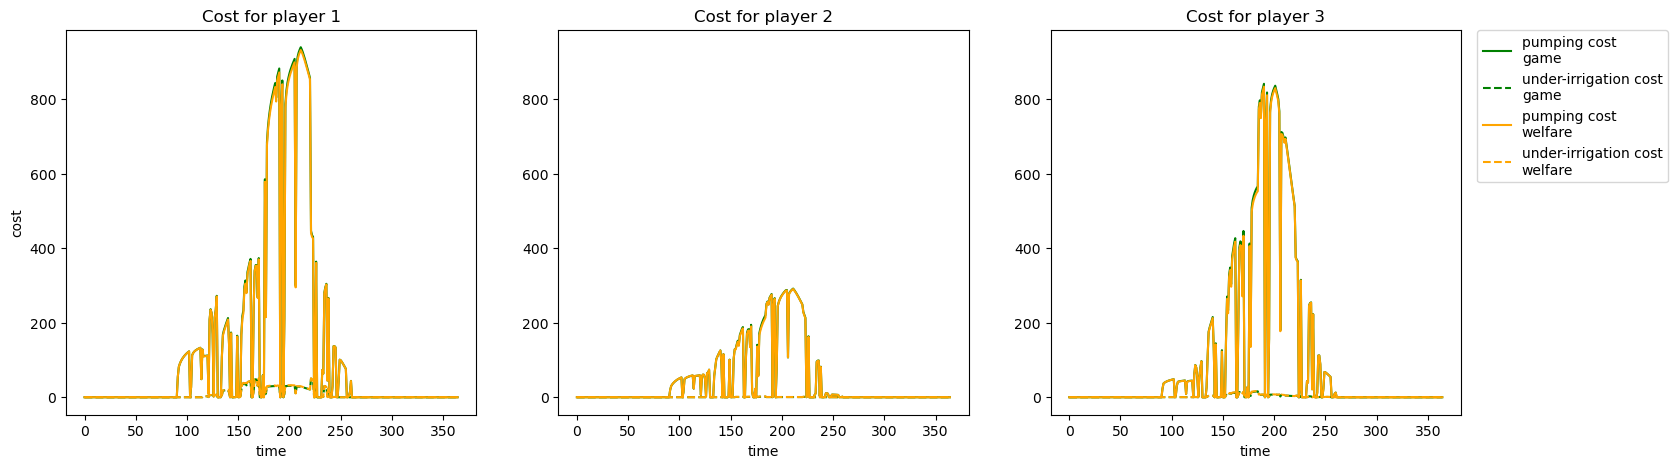

In [398]:
fig = plt.figure(figsize=(15+3,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Cost for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(pumping_cost_si[ii, :], 'g', label='pumping cost\ngame')
    ax.plot(under_irrigation_cost_si[ii, :], 'g--', label='under-irrigation cost\ngame')
    ax.plot(pumping_cost_wf[ii, :], color="orange", label='pumping cost\nwelfare')
    ax.plot(under_irrigation_cost_wf[ii, :], color="orange", linestyle="--", label='under-irrigation cost\nwelfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

In [399]:
epsilon = 1
pumping_cost_epsilon = np.zeros((5, cost_model.n_agent, 365))
under_irrigation_cost_epsilon = np.zeros((5, cost_model.n_agent, 365))
for w in range(n_well):
    u_incr = u_si.copy()
    u_incr = np.minimum((u_incr.T + 10*np.roll(np.array([1]+[0]*(n_well-1)), w)).T, 0)
    for v_1 in range(cost_model.n_agent):
        input_indices = np.nonzero(cost_model.well_to_cell[:,cost_model.well_to_agent==v_1].T)[1]
        well_index = np.arange(np.hstack(model.n_well_per_command).sum(), dtype=int)[model.well_to_agent==v_1]
        for t in range(364):
            pumping_cost_epsilon[w,v_1,t] = (-cost_model.extraction_cost[v_1] * (cost_model.top_head[input_indices] -\
                data_si['h_wells'][[well_index], t+1].T) * u_incr[cost_model.well_to_agent==v_1,:,t].sum(axis=1).reshape(-1,1)).sum()
            under_irrigation = water_req[v_1, :, t] + u_incr[cost_model.well_to_agent==v_1,:,t].sum(axis=0)    # TODO: check dimensions
            under_irrigation_cost_epsilon[w, v_1,t] = \
                under_irrigation.T @ sp.diags(under_irrigation_weight[v_1,:,t].flatten()) @ under_irrigation.T
cost_epsilon = pumping_cost_epsilon + under_irrigation_cost_epsilon

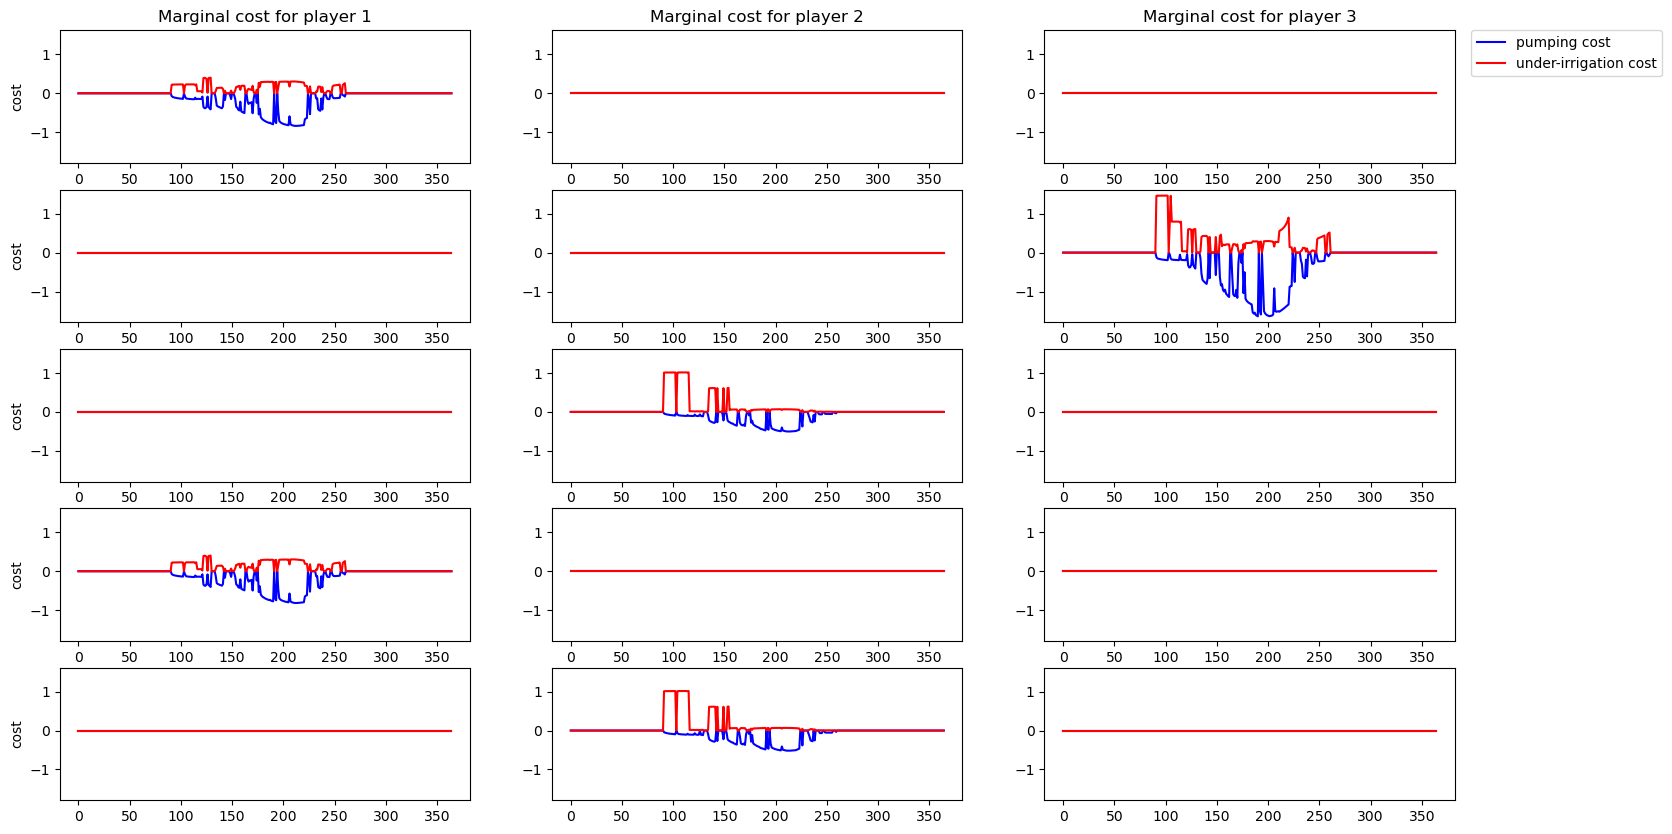

In [400]:
fig = plt.figure(figsize=(15+3,10))
ax = None
for w in range(n_well):
    for ii in range(3):
        ax = fig.add_subplot(n_well, 3, 3*w+ii+1, sharey=ax)
        ttl = f"Marginal cost for player {ii+1}"
        if w == 0:
            ax.set_title(ttl)
        if ii == 0:
            ax.set_ylabel("cost")
        ax.plot(pumping_cost_epsilon[w, ii, :] - pumping_cost_si[ii, :], 'b', label='pumping cost')
        ax.plot(under_irrigation_cost_epsilon[w, ii, :] - under_irrigation_cost_si[ii, :], 'r', label='under-irrigation cost')
        if ii == 2 and w==0:
            ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

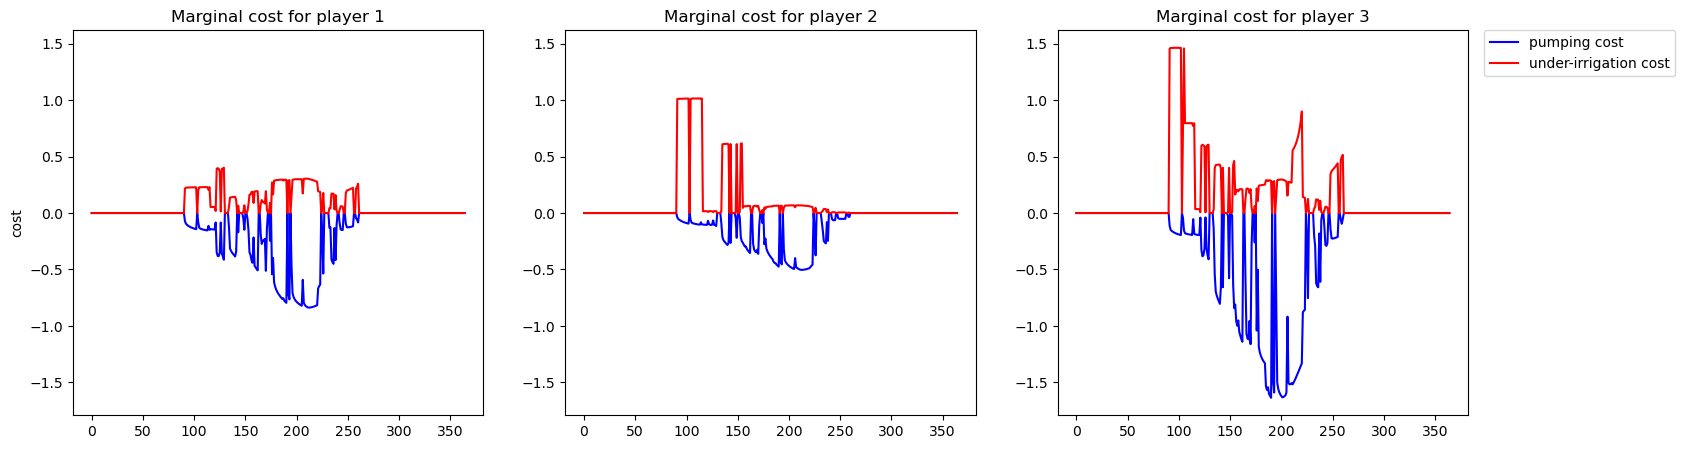

In [401]:
fig = plt.figure(figsize=(15+3,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Marginal cost for player {ii+1}"
    ax.set_title(ttl)
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(pumping_cost_epsilon[np.bool(well_to_agent[ii,:]), ii, :][0,...] - pumping_cost_si[ii, :], 'b', label='pumping cost')
    ax.plot(under_irrigation_cost_epsilon[np.bool(well_to_agent[ii,:]), ii, :][0,...] - under_irrigation_cost_si[ii, :], 'r', label='under-irrigation cost')
    if ii == 2:
        ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

In [402]:
ii=1
argmin = (pumping_cost_epsilon[np.bool(well_to_agent[ii,:]), ii, :][0,...] - pumping_cost_si[ii, :]).argmin()
(pumping_cost_epsilon[np.bool(well_to_agent[ii,:]), ii, :][0,...] - pumping_cost_si[ii, :]).min(), (under_irrigation_cost_epsilon[np.bool(well_to_agent[ii,:]), ii, :][0,...] - under_irrigation_cost_si[ii, :])[argmin]

(np.float64(-0.5032077468872558), np.float64(0.06733935824833248))

In [403]:
argmax = (under_irrigation_cost_epsilon[np.bool(well_to_agent[ii,:]), ii, :][0,...] - under_irrigation_cost_si[ii, :]).argmax()
(under_irrigation_cost_epsilon[np.bool(well_to_agent[ii,:]), ii, :][0,...] - under_irrigation_cost_si[ii, :]).max(), (pumping_cost_epsilon[np.bool(well_to_agent[ii,:]), ii, :][0,...] - pumping_cost_si[ii, :])[argmax]

(np.float64(1.014724707976893), np.float64(-0.10021980848313206))

# Get rid of high sensibilities and pad

In [404]:
parameter_file = "run_data/run_20250626-171759/model_parameters.json"

In [405]:
# Initialize System and Model
system = SimpleSquareExample(parameter_file, boundary_condition="Constant Head")
model = IrrigationSchedulingModel(parameter_file, boundary_condition="Constant Head")
cost_model = IrrigationSchedulingCost(parameter_file, model, crops)

In [406]:
# Initialize Controller
controller = TimeVaryingCost_LQRc_RHG(
    parameter_file,
    model.A.toarray(), [B.toarray() for B in model.B_v], model.C,
    model.H_x, model.h_x, model.H_u_v, model.h_u_v,
    model.H_xu_x, model.H_xu_u, model.h_xu,
    solver='fbrs'
)

In [407]:
# Transform into welfare controller
welfare = LQRc_welfare(controller)

In [408]:
water_req = cost_model._get_water_requirement(0, 365)
under_irrigation_weight = cost_model._get_under_irrigation_weight(0, 365)

In [409]:
n_well = int(sum(np.hstack(model.n_well_per_command)))
well_to_agent = np.zeros((model.n_agent, n_well))
indices = np.array(list(zip(model.well_to_agent.tolist(), range(n_well)))).T
well_to_agent[indices[0, :], indices[1, :]] = 1

In [410]:
data_si = np.load("run_data/run_20250626-171759/result_data.npz")
data_wf = np.load("run_data/run_20250626-164716/result_data.npz")

In [411]:
player_pumping_si = well_to_agent @ data_si['q_rates']
player_pumping_wf = well_to_agent @ data_wf['q_rates']
rain = cost_model._get_available_water(0, 365)

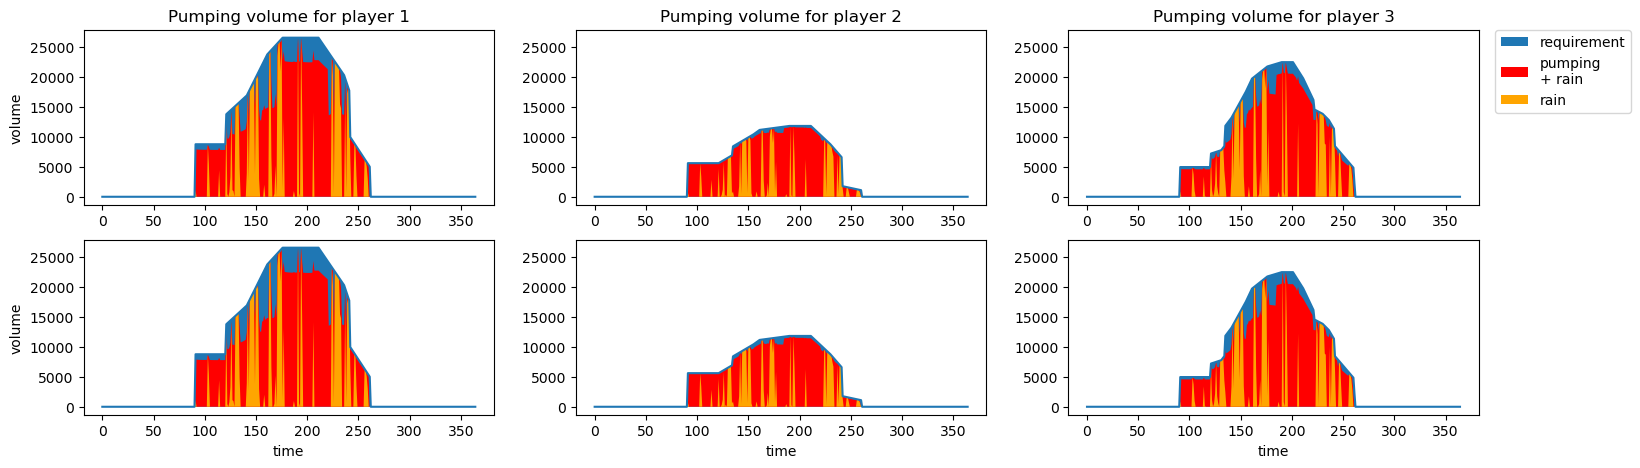

In [412]:
fig = plt.figure(figsize=(15+3,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(2, 3, ii+1, sharey=ax)
    ttl = f"Pumping volume for player {ii+1}"
    ax.set_title(ttl)
    if ii == 0:
        ax.set_ylabel("volume")
    ax.plot((water_req+rain)[ii, :, :].sum(axis=0))
    ax.fill((water_req+rain)[ii, :, :].sum(axis=0), label='requirement')
    ax.fill(-player_pumping_si[ii, :] + rain[ii,:,:].sum(axis=0), "r-", label='pumping\n+ rain')
    ax.fill(rain[ii,:,:].sum(axis=0), "orange", label='rain')
    if ii == 2:
        ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
    # Welfare
    ax = fig.add_subplot(2, 3, 3+ii+1, sharey=ax)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("volume")
    ax.plot((water_req+rain)[ii, :, :].sum(axis=0))
    ax.fill((water_req+rain)[ii, :, :].sum(axis=0))
    ax.fill(-player_pumping_wf[ii, :] + rain[ii,:,:].sum(axis=0), "r-")
    ax.fill(rain[ii,:,:].sum(axis=0), "orange")

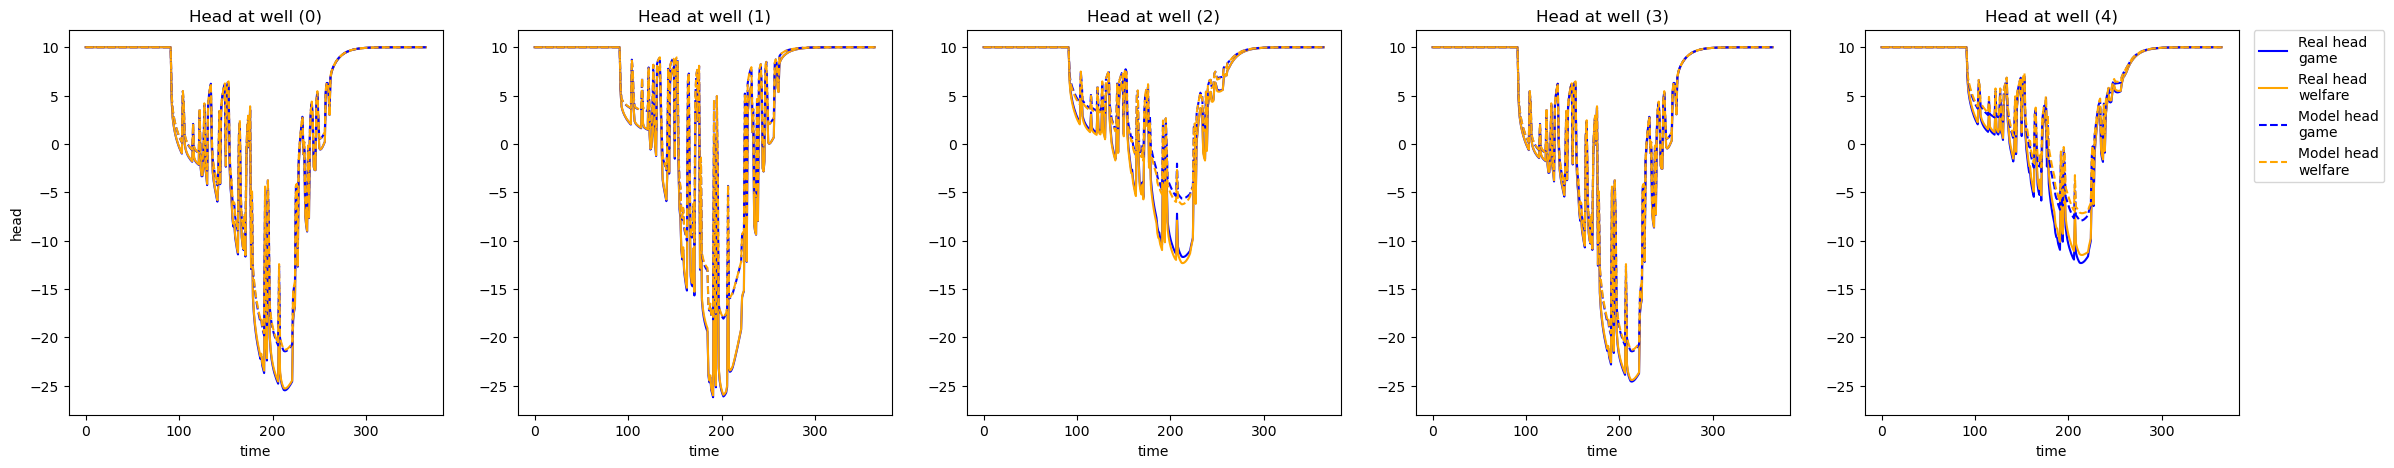

In [413]:
# Display heads evolution
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(5):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Head at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    ax_h.plot(data_si['h_wells'][ii, :], "b-", label="Real head\ngame")
    ax_h.plot(data_wf['h_wells'][ii, :], color="orange", label="Real head\nwelfare")
    ax_h.plot(data_si['corrected_h_wells'][ii, :], "b--", label="Model head\ngame")
    ax_h.plot(data_wf['corrected_h_wells'][ii, :], color="orange", linestyle="--", label="Model head\nwelfare")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

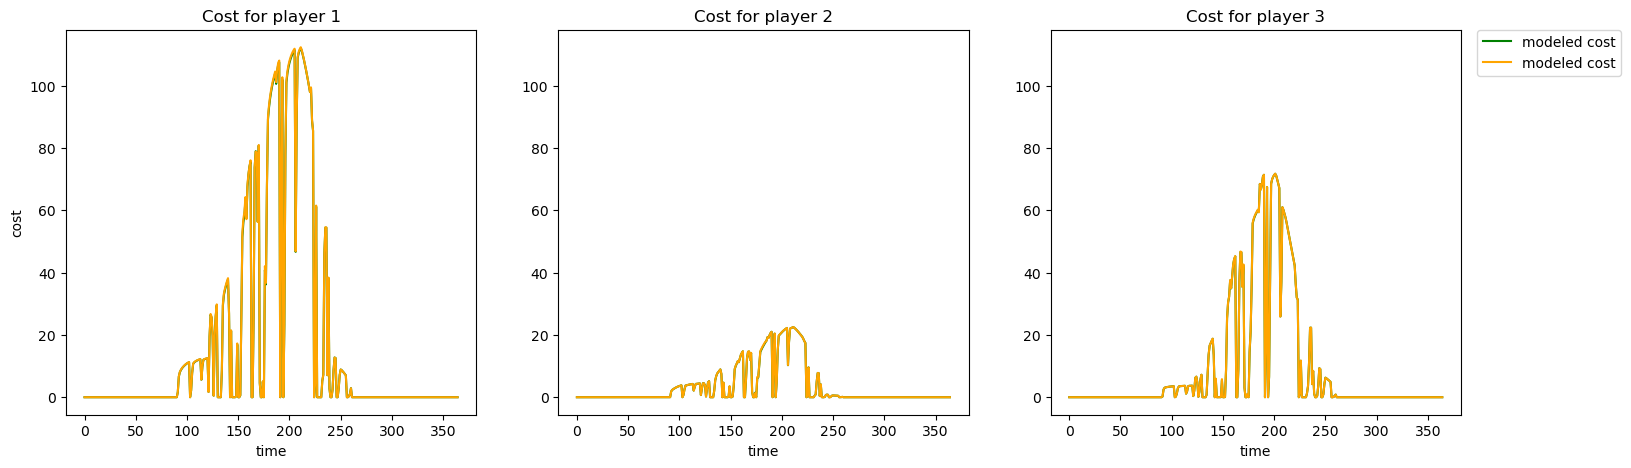

In [414]:
fig = plt.figure(figsize=(15+3,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Cost for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(-data_si['model_profit'][ii, :], 'g', label='modeled cost')
    ax.plot(-data_wf['model_profit'][ii, :], color="orange", label='modeled cost')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

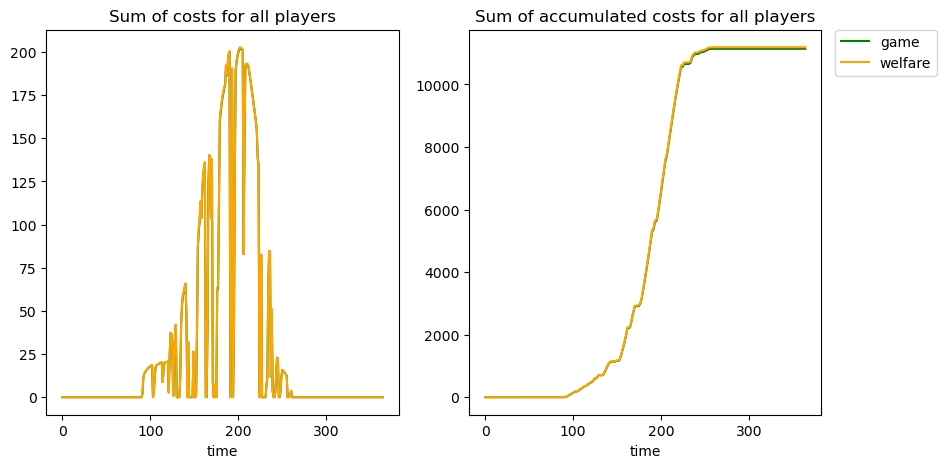

In [415]:
fig = plt.figure(figsize=(10,5))
ax = fig.add_subplot(1, 2, 1)
ttl = f"Sum of costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("cost")
ax.plot(-data_si['model_profit'].sum(axis=0), 'g')
ax.plot(-data_wf['model_profit'].sum(axis=0), color="orange")

ax = fig.add_subplot(1, 2, 2)
ttl = f"Sum of accumulated costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("cost")
ax.plot(-np.cumsum(data_si['model_profit'].sum(axis=0)), 'g', label='game')
ax.plot(-np.cumsum(data_wf['model_profit'].sum(axis=0)), color="orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

In [416]:
u_si = np.array([model.reorganize_input_per_well(data_si['inputs'][:,[k]]) for k in range(365)]).T
u_si = u_si.reshape((np.hstack(cost_model.n_well_per_command).sum(dtype=int), cost_model.n_crops, 365))
u_wf = np.array([model.reorganize_input_per_well(data_wf['inputs'][:,[k]]) for k in range(365)]).T
u_wf = u_wf.reshape((np.hstack(cost_model.n_well_per_command).sum(dtype=int), cost_model.n_crops, 365))

In [417]:
pumping_cost_si = np.zeros((cost_model.n_agent, 365))
under_irrigation_cost_si = np.zeros((cost_model.n_agent, 365))
pumping_cost_wf = np.zeros((cost_model.n_agent, 365))
under_irrigation_cost_wf = np.zeros((cost_model.n_agent, 365))
for v_1 in range(cost_model.n_agent):
    input_indices = np.nonzero(cost_model.well_to_cell[:,cost_model.well_to_agent==v_1].T)[1]
    well_index = np.arange(np.hstack(model.n_well_per_command).sum(), dtype=int)[model.well_to_agent==v_1]
    for t in range(364):
        pumping_cost_si[v_1,t] = (-cost_model.extraction_cost[v_1] * (cost_model.top_head[input_indices] -\
            data_si['h_wells'][[well_index], t+1].T) * u_si[cost_model.well_to_agent==v_1,:,t].sum(axis=1).reshape(-1,1)).sum()
        under_irrigation = water_req[v_1, :, t] + u_si[cost_model.well_to_agent==v_1,:,t].sum(axis=0)    # TODO: check dimensions
        under_irrigation_cost_si[v_1,t] = \
            under_irrigation.T @ sp.diags(under_irrigation_weight[v_1,:,t].flatten()) @ under_irrigation.T
        # Welfare costs
        pumping_cost_wf[v_1,t] = (-cost_model.extraction_cost[v_1] * (cost_model.top_head[input_indices] -\
            data_wf['h_wells'][[well_index], t+1].T) * u_wf[cost_model.well_to_agent==v_1,:,t].sum(axis=1).reshape(-1,1)).sum()
        under_irrigation = water_req[v_1, :, t] + u_wf[cost_model.well_to_agent==v_1,:,t].sum(axis=0)    # TODO: check dimensions
        under_irrigation_cost_wf[v_1,t] = \
            under_irrigation.T @ sp.diags(under_irrigation_weight[v_1,:,t].flatten()) @ under_irrigation.T
cost_si = pumping_cost_si + under_irrigation_cost_si
cost_wf = pumping_cost_wf + under_irrigation_cost_wf

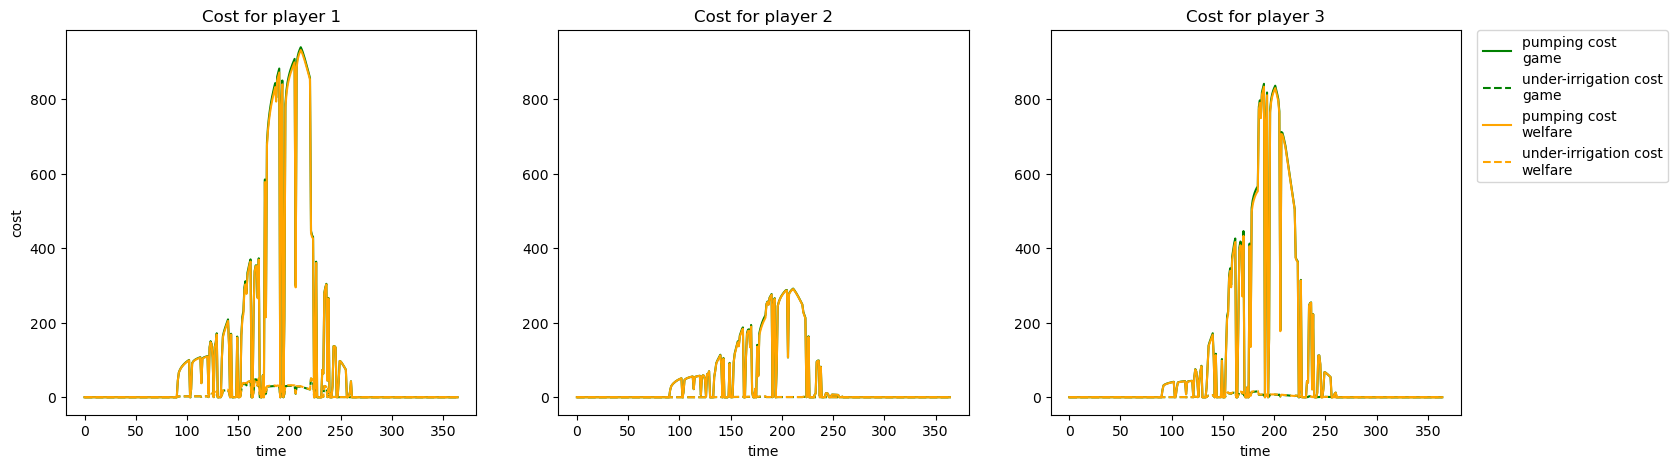

In [418]:
fig = plt.figure(figsize=(15+3,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Cost for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(pumping_cost_si[ii, :], 'g', label='pumping cost\ngame')
    ax.plot(under_irrigation_cost_si[ii, :], 'g--', label='under-irrigation cost\ngame')
    ax.plot(pumping_cost_wf[ii, :], color="orange", label='pumping cost\nwelfare')
    ax.plot(under_irrigation_cost_wf[ii, :], color="orange", linestyle="--", label='under-irrigation cost\nwelfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

In [419]:
epsilon = 1
pumping_cost_epsilon = np.zeros((5, cost_model.n_agent, 365))
under_irrigation_cost_epsilon = np.zeros((5, cost_model.n_agent, 365))
for w in range(n_well):
    u_incr = u_si.copy()
    u_incr = np.minimum((u_incr.T + 1000*np.roll(np.array([1]+[0]*(n_well-1)), w)).T, 0)
    for v_1 in range(cost_model.n_agent):
        input_indices = np.nonzero(cost_model.well_to_cell[:,cost_model.well_to_agent==v_1].T)[1]
        well_index = np.arange(np.hstack(model.n_well_per_command).sum(), dtype=int)[model.well_to_agent==v_1]
        for t in range(364):
            pumping_cost_epsilon[w,v_1,t] = (-cost_model.extraction_cost[v_1] * (cost_model.top_head[input_indices] -\
                data_si['h_wells'][[well_index], t+1].T) * u_incr[cost_model.well_to_agent==v_1,:,t].sum(axis=1).reshape(-1,1)).sum()
            under_irrigation = water_req[v_1, :, t] + u_incr[cost_model.well_to_agent==v_1,:,t].sum(axis=0)    # TODO: check dimensions
            under_irrigation_cost_epsilon[w, v_1,t] = \
                under_irrigation.T @ sp.diags(under_irrigation_weight[v_1,:,t].flatten()) @ under_irrigation.T
cost_epsilon = pumping_cost_epsilon + under_irrigation_cost_epsilon

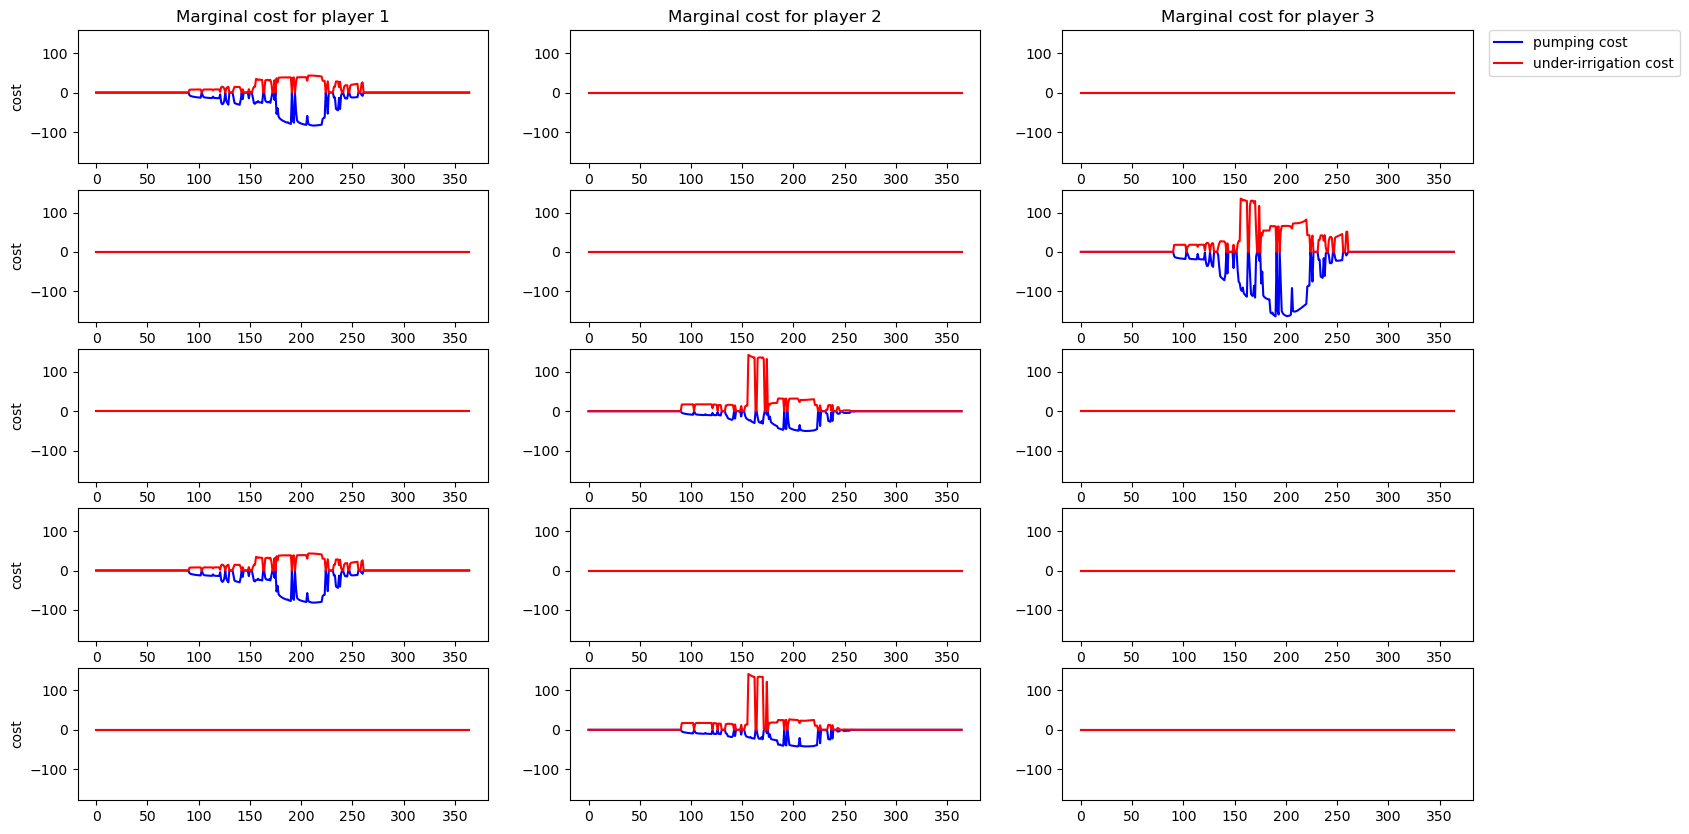

In [420]:
fig = plt.figure(figsize=(15+3,10))
ax = None
for w in range(n_well):
    for ii in range(3):
        ax = fig.add_subplot(n_well, 3, 3*w+ii+1, sharey=ax)
        ttl = f"Marginal cost for player {ii+1}"
        if w == 0:
            ax.set_title(ttl)
        if ii == 0:
            ax.set_ylabel("cost")
        ax.plot(pumping_cost_epsilon[w, ii, :] - pumping_cost_si[ii, :], 'b', label='pumping cost')
        ax.plot(under_irrigation_cost_epsilon[w, ii, :] - under_irrigation_cost_si[ii, :], 'r', label='under-irrigation cost')
        if ii == 2 and w==0:
            ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

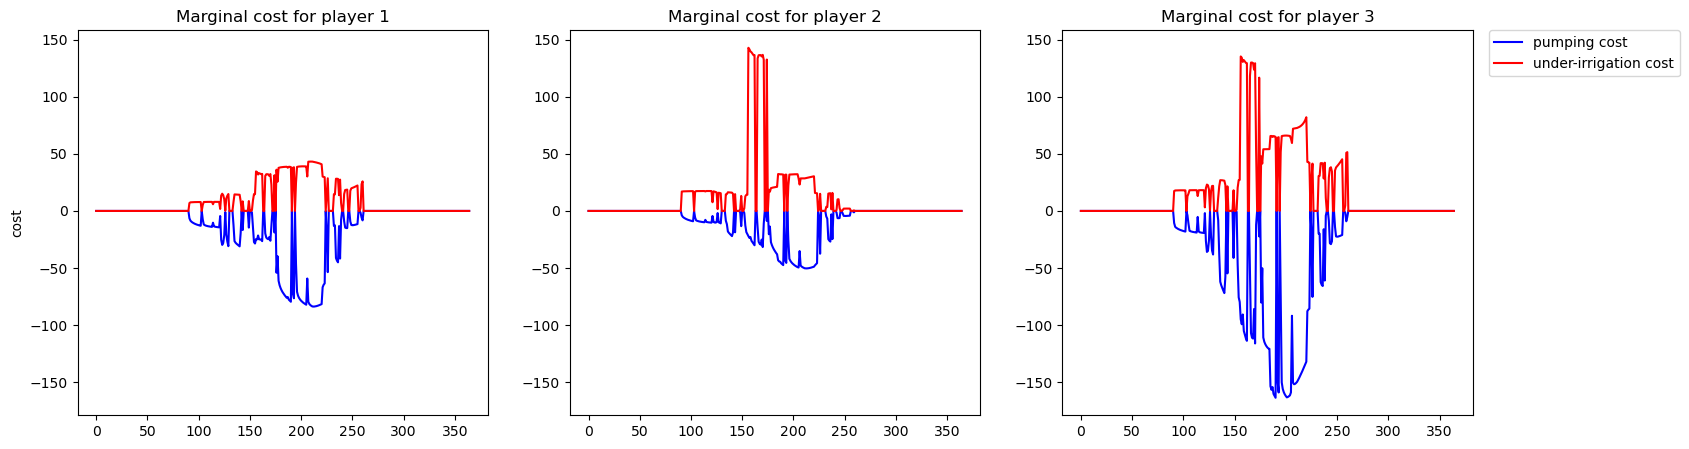

In [421]:
fig = plt.figure(figsize=(15+3,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Marginal cost for player {ii+1}"
    ax.set_title(ttl)
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(pumping_cost_epsilon[np.bool(well_to_agent[ii,:]), ii, :][0,...] - pumping_cost_si[ii, :], 'b', label='pumping cost')
    ax.plot(under_irrigation_cost_epsilon[np.bool(well_to_agent[ii,:]), ii, :][0,...] - under_irrigation_cost_si[ii, :], 'r', label='under-irrigation cost')
    if ii == 2:
        ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

In [422]:
ii=1
argmin = (pumping_cost_epsilon[np.bool(well_to_agent[ii,:]), ii, :][0,...] - pumping_cost_si[ii, :]).argmin()
(pumping_cost_epsilon[np.bool(well_to_agent[ii,:]), ii, :][0,...] - pumping_cost_si[ii, :]).min(), (under_irrigation_cost_epsilon[np.bool(well_to_agent[ii,:]), ii, :][0,...] - under_irrigation_cost_si[ii, :])[argmin]

(np.float64(-50.31661735534669), np.float64(28.705546102754404))

In [423]:
argmax = (under_irrigation_cost_epsilon[np.bool(well_to_agent[ii,:]), ii, :][0,...] - under_irrigation_cost_si[ii, :]).argmax()
(under_irrigation_cost_epsilon[np.bool(well_to_agent[ii,:]), ii, :][0,...] - under_irrigation_cost_si[ii, :]).max(), (pumping_cost_epsilon[np.bool(well_to_agent[ii,:]), ii, :][0,...] - pumping_cost_si[ii, :])[argmax]

(np.float64(142.85333825043358), np.float64(-22.01959159228747))

# Increase pumping cost

In [424]:
parameter_file = "run_data/run_20250626-172843/model_parameters.json"

In [425]:
# Initialize System and Model
system = SimpleSquareExample(parameter_file, boundary_condition="Constant Head")
model = IrrigationSchedulingModel(parameter_file, boundary_condition="Constant Head")
cost_model = IrrigationSchedulingCost(parameter_file, model, crops)

In [426]:
# Initialize Controller
controller = TimeVaryingCost_LQRc_RHG(
    parameter_file,
    model.A.toarray(), [B.toarray() for B in model.B_v], model.C,
    model.H_x, model.h_x, model.H_u_v, model.h_u_v,
    model.H_xu_x, model.H_xu_u, model.h_xu,
    solver='fbrs'
)

In [427]:
# Transform into welfare controller
welfare = LQRc_welfare(controller)

In [428]:
water_req = cost_model._get_water_requirement(0, 365)
under_irrigation_weight = cost_model._get_under_irrigation_weight(0, 365)

In [429]:
n_well = int(sum(np.hstack(model.n_well_per_command)))
well_to_agent = np.zeros((model.n_agent, n_well))
indices = np.array(list(zip(model.well_to_agent.tolist(), range(n_well)))).T
well_to_agent[indices[0, :], indices[1, :]] = 1

In [430]:
data_si = np.load("run_data/run_20250626-172843/result_data.npz")
data_wf = np.load("run_data/run_20250626-173741/result_data.npz")

In [431]:
player_pumping_si = well_to_agent @ data_si['q_rates']
player_pumping_wf = well_to_agent @ data_wf['q_rates']
rain = cost_model._get_available_water(0, 365)

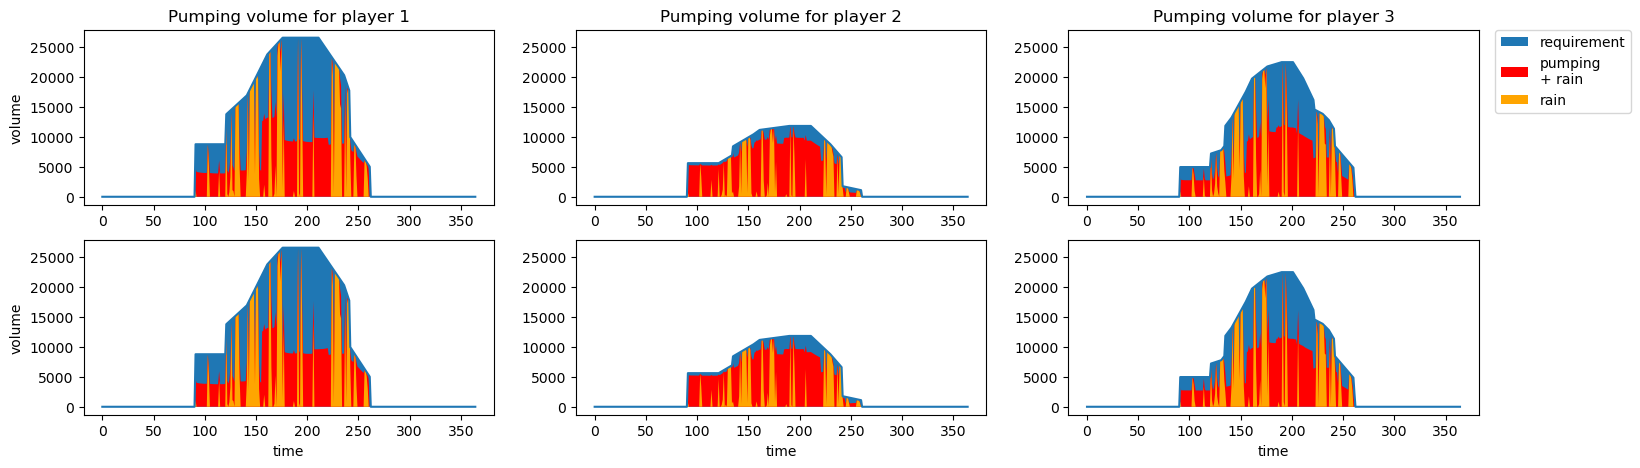

In [432]:
fig = plt.figure(figsize=(15+3,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(2, 3, ii+1, sharey=ax)
    ttl = f"Pumping volume for player {ii+1}"
    ax.set_title(ttl)
    if ii == 0:
        ax.set_ylabel("volume")
    ax.plot((water_req+rain)[ii, :, :].sum(axis=0))
    ax.fill((water_req+rain)[ii, :, :].sum(axis=0), label='requirement')
    ax.fill(-player_pumping_si[ii, :] + rain[ii,:,:].sum(axis=0), "r-", label='pumping\n+ rain')
    ax.fill(rain[ii,:,:].sum(axis=0), "orange", label='rain')
    if ii == 2:
        ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
    # Welfare
    ax = fig.add_subplot(2, 3, 3+ii+1, sharey=ax)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("volume")
    ax.plot((water_req+rain)[ii, :, :].sum(axis=0))
    ax.fill((water_req+rain)[ii, :, :].sum(axis=0))
    ax.fill(-player_pumping_wf[ii, :] + rain[ii,:,:].sum(axis=0), "r-")
    ax.fill(rain[ii,:,:].sum(axis=0), "orange")

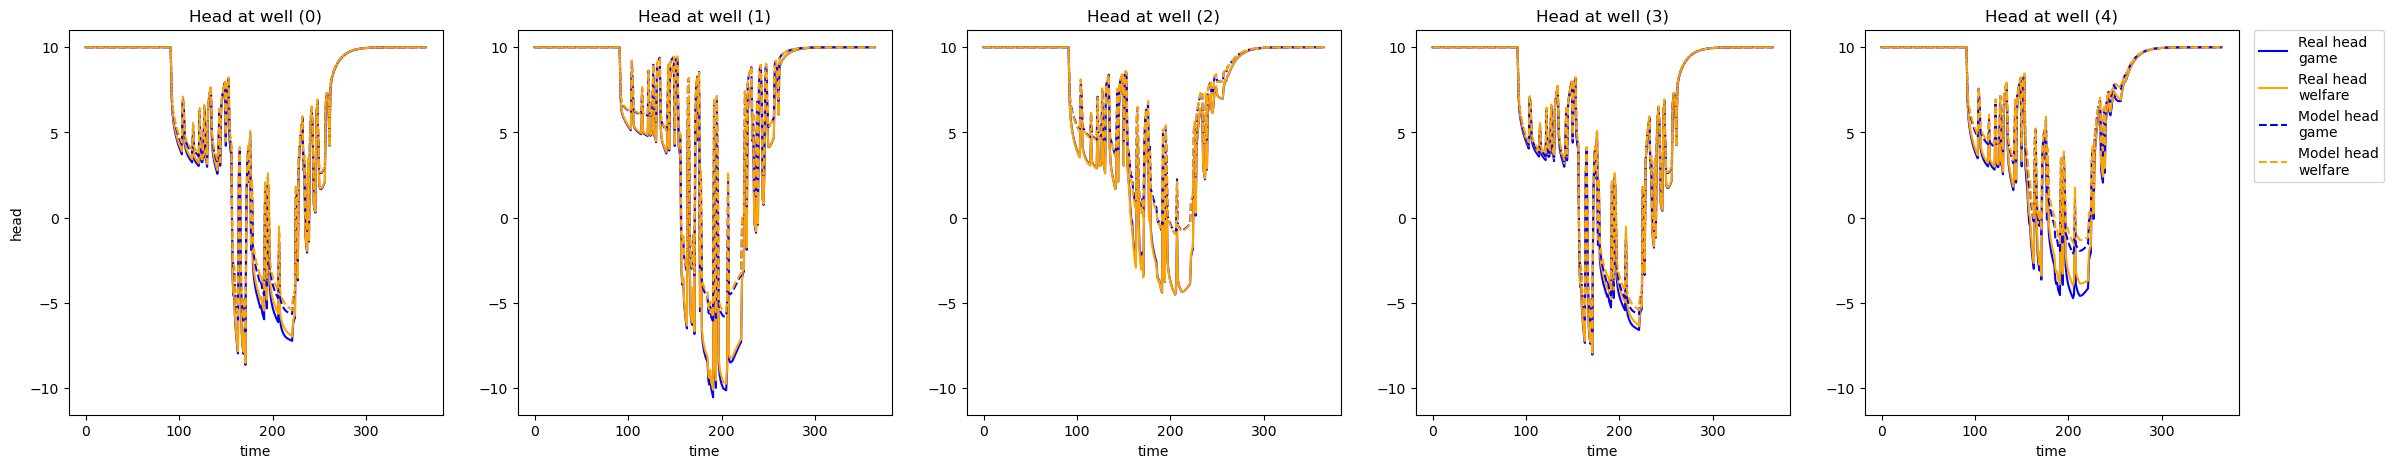

In [433]:
# Display heads evolution
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(5):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Head at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    ax_h.plot(data_si['h_wells'][ii, :], "b-", label="Real head\ngame")
    ax_h.plot(data_wf['h_wells'][ii, :], color="orange", label="Real head\nwelfare")
    ax_h.plot(data_si['corrected_h_wells'][ii, :], "b--", label="Model head\ngame")
    ax_h.plot(data_wf['corrected_h_wells'][ii, :], color="orange", linestyle="--", label="Model head\nwelfare")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

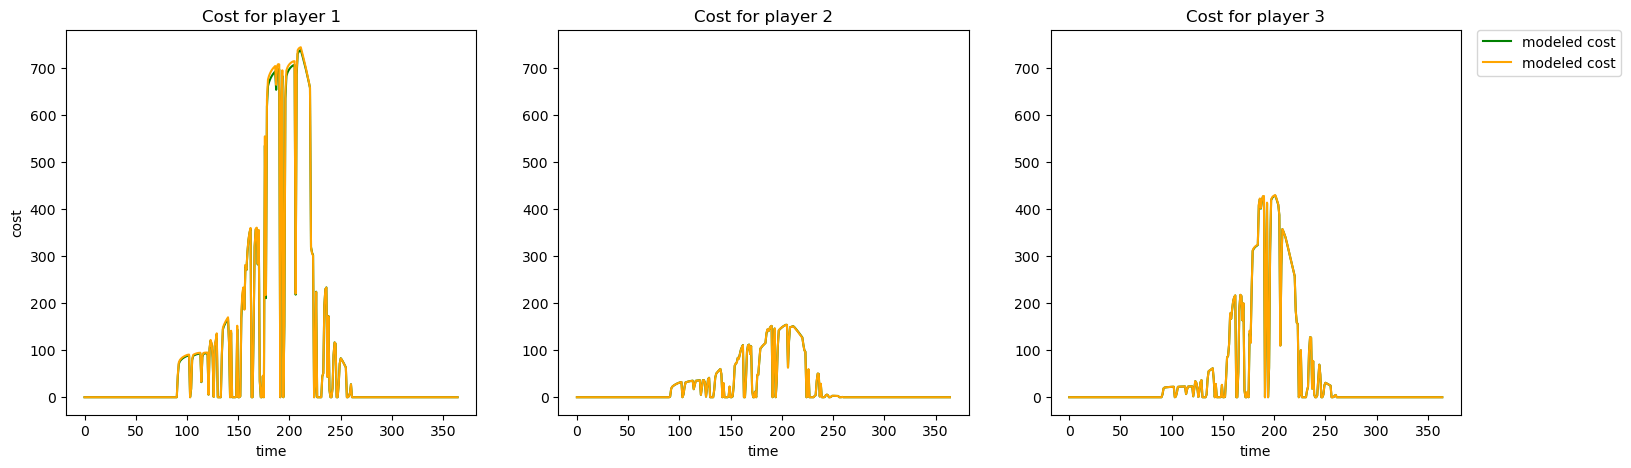

In [434]:
fig = plt.figure(figsize=(15+3,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Cost for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(-data_si['model_profit'][ii, :], 'g', label='modeled cost')
    ax.plot(-data_wf['model_profit'][ii, :], color="orange", label='modeled cost')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

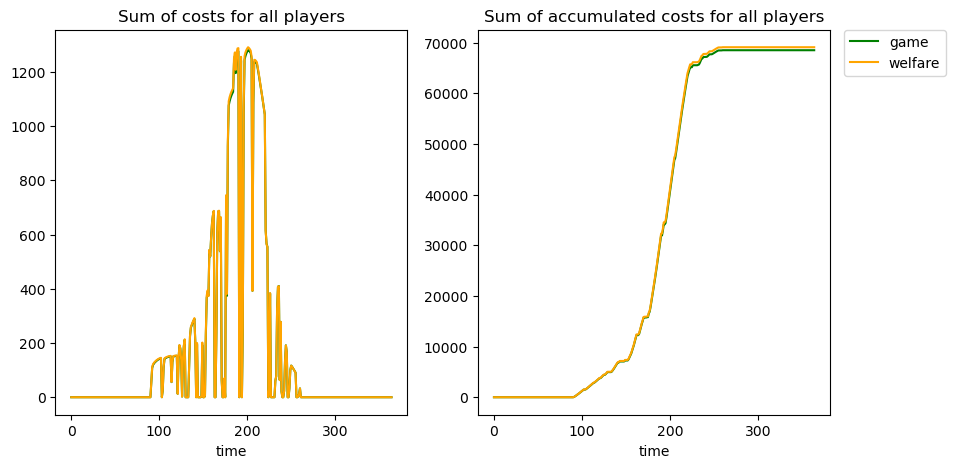

In [435]:
fig = plt.figure(figsize=(10,5))
ax = fig.add_subplot(1, 2, 1)
ttl = f"Sum of costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("cost")
ax.plot(-data_si['model_profit'].sum(axis=0), 'g')
ax.plot(-data_wf['model_profit'].sum(axis=0), color="orange")

ax = fig.add_subplot(1, 2, 2)
ttl = f"Sum of accumulated costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("cost")
ax.plot(-np.cumsum(data_si['model_profit'].sum(axis=0)), 'g', label='game')
ax.plot(-np.cumsum(data_wf['model_profit'].sum(axis=0)), color="orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

In [436]:
u_si = np.array([model.reorganize_input_per_well(data_si['inputs'][:,[k]]) for k in range(365)]).T
u_si = u_si.reshape((np.hstack(cost_model.n_well_per_command).sum(dtype=int), cost_model.n_crops, 365))
u_wf = np.array([model.reorganize_input_per_well(data_wf['inputs'][:,[k]]) for k in range(365)]).T
u_wf = u_wf.reshape((np.hstack(cost_model.n_well_per_command).sum(dtype=int), cost_model.n_crops, 365))

In [437]:
pumping_cost_si = np.zeros((cost_model.n_agent, 365))
under_irrigation_cost_si = np.zeros((cost_model.n_agent, 365))
pumping_cost_wf = np.zeros((cost_model.n_agent, 365))
under_irrigation_cost_wf = np.zeros((cost_model.n_agent, 365))
for v_1 in range(cost_model.n_agent):
    input_indices = np.nonzero(cost_model.well_to_cell[:,cost_model.well_to_agent==v_1].T)[1]
    well_index = np.arange(np.hstack(model.n_well_per_command).sum(), dtype=int)[model.well_to_agent==v_1]
    for t in range(364):
        pumping_cost_si[v_1,t] = (-cost_model.extraction_cost[v_1] * (cost_model.top_head[input_indices] -\
            data_si['h_wells'][[well_index], t+1].T) * u_si[cost_model.well_to_agent==v_1,:,t].sum(axis=1).reshape(-1,1)).sum()
        under_irrigation = water_req[v_1, :, t] + u_si[cost_model.well_to_agent==v_1,:,t].sum(axis=0)    # TODO: check dimensions
        under_irrigation_cost_si[v_1,t] = \
            under_irrigation.T @ sp.diags(under_irrigation_weight[v_1,:,t].flatten()) @ under_irrigation.T
        # Welfare costs
        pumping_cost_wf[v_1,t] = (-cost_model.extraction_cost[v_1] * (cost_model.top_head[input_indices] -\
            data_wf['h_wells'][[well_index], t+1].T) * u_wf[cost_model.well_to_agent==v_1,:,t].sum(axis=1).reshape(-1,1)).sum()
        under_irrigation = water_req[v_1, :, t] + u_wf[cost_model.well_to_agent==v_1,:,t].sum(axis=0)    # TODO: check dimensions
        under_irrigation_cost_wf[v_1,t] = \
            under_irrigation.T @ sp.diags(under_irrigation_weight[v_1,:,t].flatten()) @ under_irrigation.T
cost_si = pumping_cost_si + under_irrigation_cost_si
cost_wf = pumping_cost_wf + under_irrigation_cost_wf

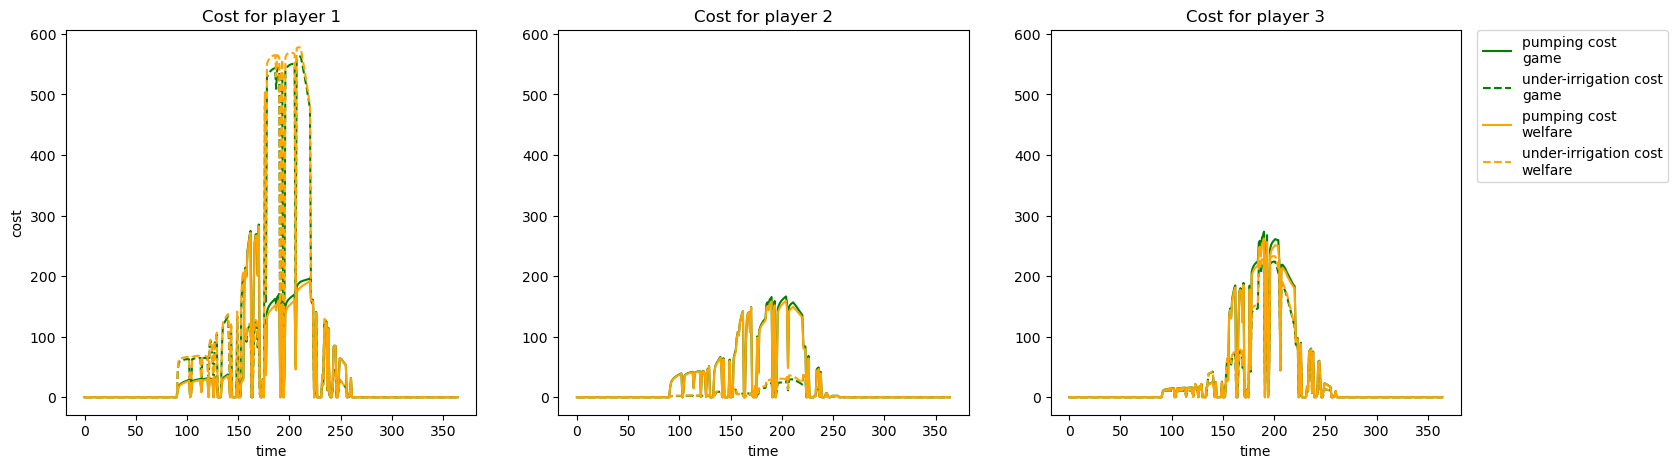

In [438]:
fig = plt.figure(figsize=(15+3,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Cost for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(pumping_cost_si[ii, :], 'g', label='pumping cost\ngame')
    ax.plot(under_irrigation_cost_si[ii, :], 'g--', label='under-irrigation cost\ngame')
    ax.plot(pumping_cost_wf[ii, :], color="orange", label='pumping cost\nwelfare')
    ax.plot(under_irrigation_cost_wf[ii, :], color="orange", linestyle="--", label='under-irrigation cost\nwelfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

In [439]:
epsilon = 1
pumping_cost_epsilon = np.zeros((5, cost_model.n_agent, 365))
under_irrigation_cost_epsilon = np.zeros((5, cost_model.n_agent, 365))
for w in range(n_well):
    u_incr = u_si.copy()
    u_incr = np.minimum((u_incr.T + 1000*np.roll(np.array([1]+[0]*(n_well-1)), w)).T, 0)
    for v_1 in range(cost_model.n_agent):
        input_indices = np.nonzero(cost_model.well_to_cell[:,cost_model.well_to_agent==v_1].T)[1]
        well_index = np.arange(np.hstack(model.n_well_per_command).sum(), dtype=int)[model.well_to_agent==v_1]
        for t in range(364):
            pumping_cost_epsilon[w,v_1,t] = (-cost_model.extraction_cost[v_1] * (cost_model.top_head[input_indices] -\
                data_si['h_wells'][[well_index], t+1].T) * u_incr[cost_model.well_to_agent==v_1,:,t].sum(axis=1).reshape(-1,1)).sum()
            under_irrigation = water_req[v_1, :, t] + u_incr[cost_model.well_to_agent==v_1,:,t].sum(axis=0)    # TODO: check dimensions
            under_irrigation_cost_epsilon[w, v_1,t] = \
                under_irrigation.T @ sp.diags(under_irrigation_weight[v_1,:,t].flatten()) @ under_irrigation.T
cost_epsilon = pumping_cost_epsilon + under_irrigation_cost_epsilon

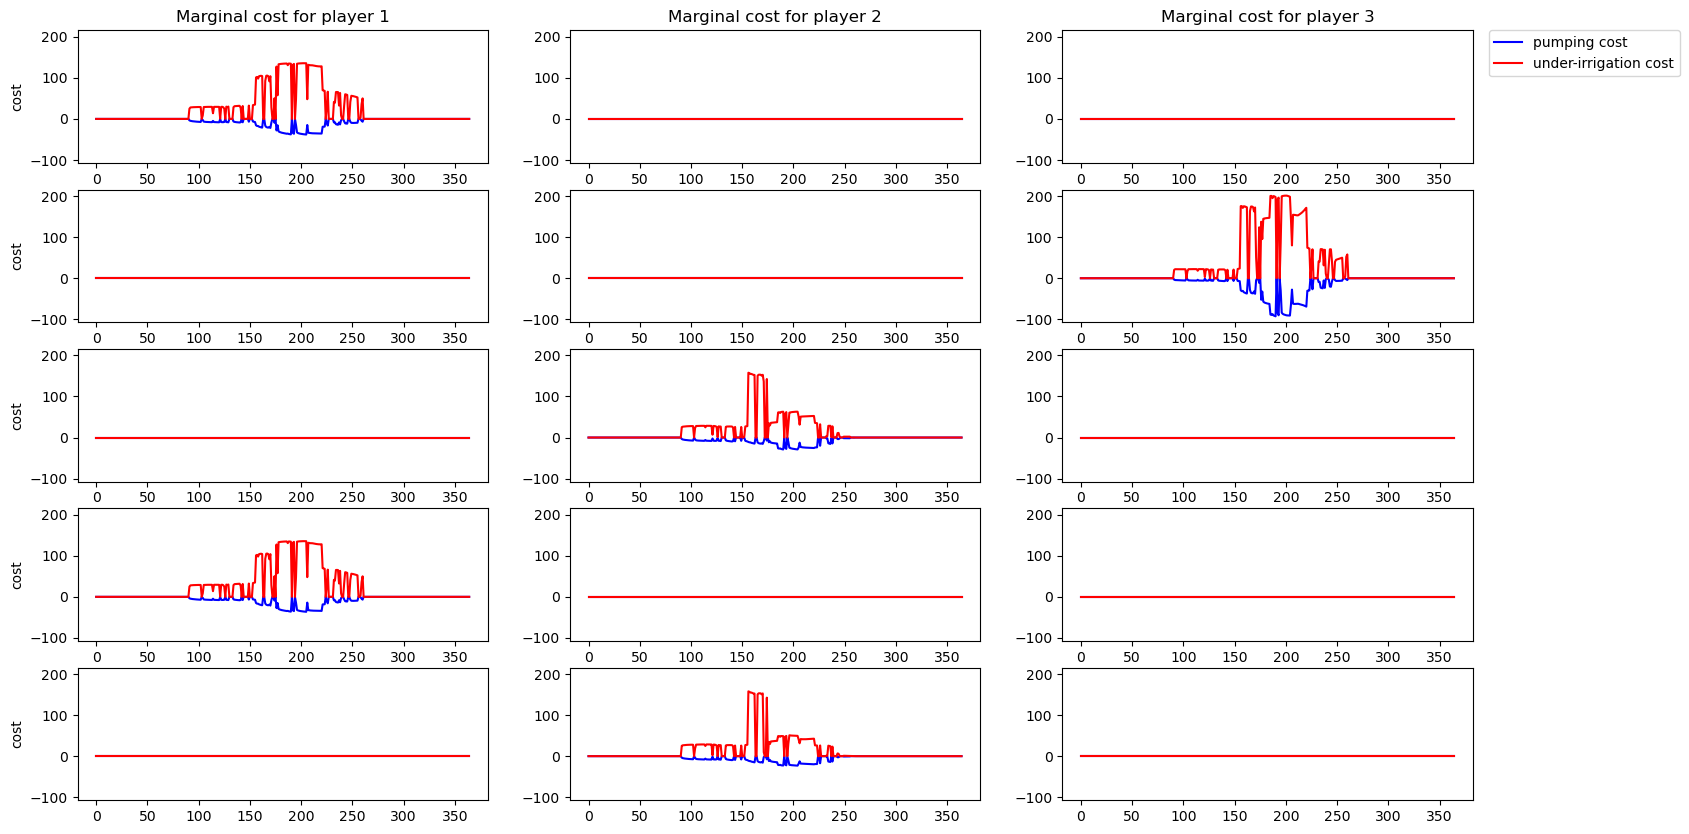

In [440]:
fig = plt.figure(figsize=(15+3,10))
ax = None
for w in range(n_well):
    for ii in range(3):
        ax = fig.add_subplot(n_well, 3, 3*w+ii+1, sharey=ax)
        ttl = f"Marginal cost for player {ii+1}"
        if w == 0:
            ax.set_title(ttl)
        if ii == 0:
            ax.set_ylabel("cost")
        ax.plot(pumping_cost_epsilon[w, ii, :] - pumping_cost_si[ii, :], 'b', label='pumping cost')
        ax.plot(under_irrigation_cost_epsilon[w, ii, :] - under_irrigation_cost_si[ii, :], 'r', label='under-irrigation cost')
        if ii == 2 and w==0:
            ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

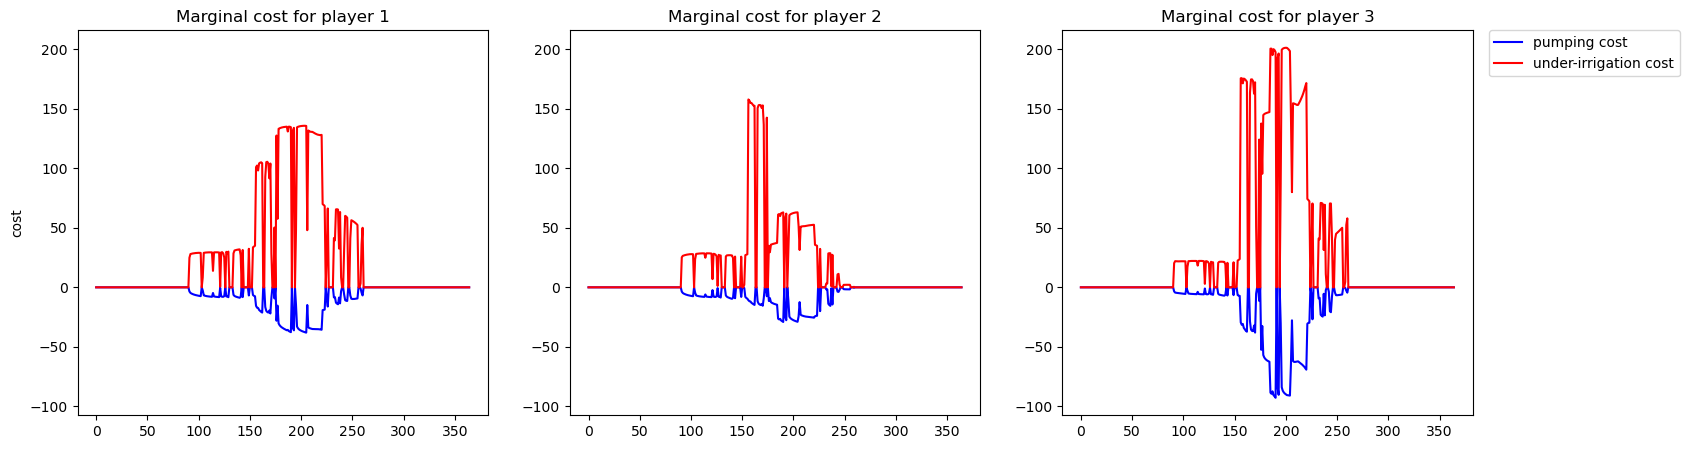

In [441]:
fig = plt.figure(figsize=(15+3,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Marginal cost for player {ii+1}"
    ax.set_title(ttl)
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(pumping_cost_epsilon[np.bool(well_to_agent[ii,:]), ii, :][0,...] - pumping_cost_si[ii, :], 'b', label='pumping cost')
    ax.plot(under_irrigation_cost_epsilon[np.bool(well_to_agent[ii,:]), ii, :][0,...] - under_irrigation_cost_si[ii, :], 'r', label='under-irrigation cost')
    if ii == 2:
        ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

In [442]:
ii=1
argmin = (pumping_cost_epsilon[np.bool(well_to_agent[ii,:]), ii, :][0,...] - pumping_cost_si[ii, :]).argmin()
(pumping_cost_epsilon[np.bool(well_to_agent[ii,:]), ii, :][0,...] - pumping_cost_si[ii, :]).min(), (under_irrigation_cost_epsilon[np.bool(well_to_agent[ii,:]), ii, :][0,...] - under_irrigation_cost_si[ii, :])[argmin]

(np.float64(-29.10293468907014), np.float64(62.9509628056867))

In [443]:
argmax = (under_irrigation_cost_epsilon[np.bool(well_to_agent[ii,:]), ii, :][0,...] - under_irrigation_cost_si[ii, :]).argmax()
(under_irrigation_cost_epsilon[np.bool(well_to_agent[ii,:]), ii, :][0,...] - under_irrigation_cost_si[ii, :]).max(), (pumping_cost_epsilon[np.bool(well_to_agent[ii,:]), ii, :][0,...] - pumping_cost_si[ii, :])[argmax]

(np.float64(157.86171153315428), np.float64(-10.812026162147518))

# Special scenario

To see differences in optimum, I found that the following situation is sufficient:
- Player 1 should be close to it's unconstrained optimum (in the game), i.e:
    - it should not need to pump a lot (-> low pumping cost)
    - its under-irrigation sensibility should be high (-> close to requirement)
- Player 2 should need to pump a lot

In [444]:
# Example crop repartition
crops = np.array([[0.4, 0.4, 0.3], [0., 0.2, 0.3], [0.6, 0., 0.3], [0., 0., 0.4]])

In [445]:
parameter_file = "run_data/run_20250627-144508/model_parameters.json"

In [446]:
# Initialize System and Model
system = SimpleSquareExample(parameter_file, boundary_condition="Constant Head")
model = IrrigationSchedulingModel(parameter_file, boundary_condition="Constant Head")
cost_model = IrrigationSchedulingCost(parameter_file, model, crops)

In [447]:
# Initialize Controller
controller = TimeVaryingCost_LQRc_RHG(
    parameter_file,
    model.A.toarray(), [B.toarray() for B in model.B_v], model.C,
    model.H_x, model.h_x, model.H_u_v, model.h_u_v,
    model.H_xu_x, model.H_xu_u, model.h_xu,
    solver='fbrs'
)

In [448]:
# Transform into welfare controller
welfare = LQRc_welfare(controller)

In [449]:
water_req = cost_model._get_water_requirement(0, 365)
under_irrigation_weight = cost_model._get_under_irrigation_weight(0, 365)

In [450]:
n_well = int(sum(np.hstack(model.n_well_per_command)))
well_to_agent = np.zeros((model.n_agent, n_well))
indices = np.array(list(zip(model.well_to_agent.tolist(), range(n_well)))).T
well_to_agent[indices[0, :], indices[1, :]] = 1

In [451]:
data_si = np.load("run_data/run_20250627-144508/result_data.npz")
data_wf = np.load("run_data/run_20250627-143215/result_data.npz")

In [452]:
player_pumping_si = well_to_agent @ data_si['q_rates']
player_pumping_wf = well_to_agent @ data_wf['q_rates']
rain = cost_model._get_available_water(0, 365)

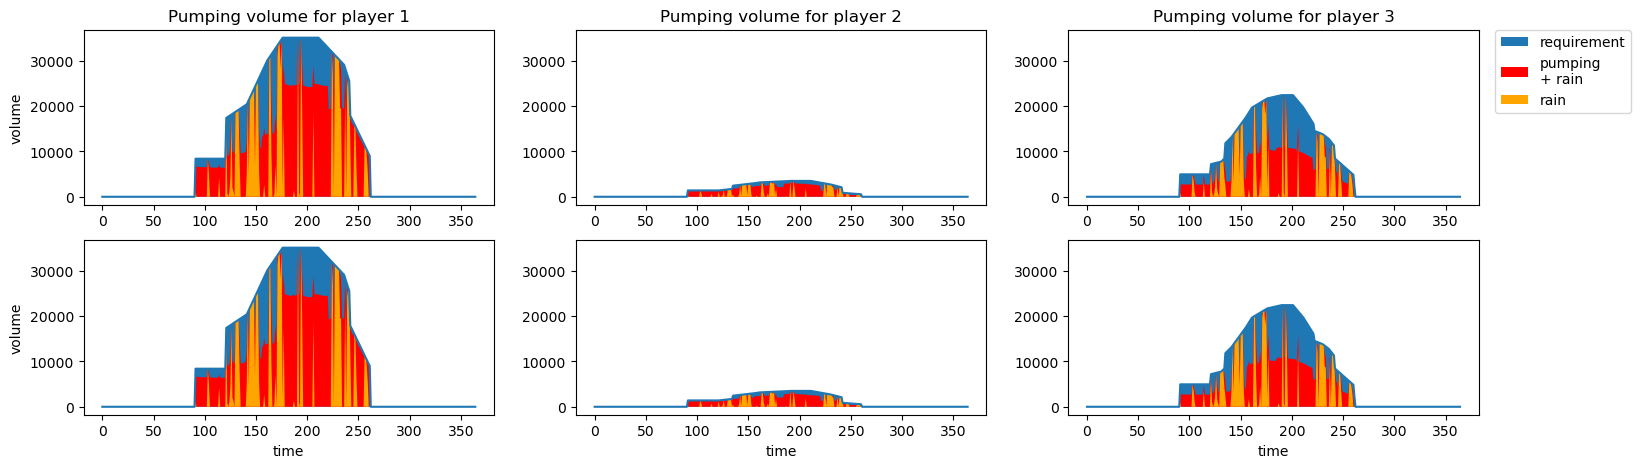

In [453]:
fig = plt.figure(figsize=(15+3,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(2, 3, ii+1, sharey=ax)
    ttl = f"Pumping volume for player {ii+1}"
    ax.set_title(ttl)
    if ii == 0:
        ax.set_ylabel("volume")
    ax.plot((water_req+rain)[ii, :, :].sum(axis=0))
    ax.fill((water_req+rain)[ii, :, :].sum(axis=0), label='requirement')
    ax.fill(-player_pumping_si[ii, :] + rain[ii,:,:].sum(axis=0), "r-", label='pumping\n+ rain')
    ax.fill(rain[ii,:,:].sum(axis=0), "orange", label='rain')
    if ii == 2:
        ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
    # Welfare
    ax = fig.add_subplot(2, 3, 3+ii+1, sharey=ax)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("volume")
    ax.plot((water_req+rain)[ii, :, :].sum(axis=0))
    ax.fill((water_req+rain)[ii, :, :].sum(axis=0))
    ax.fill(-player_pumping_wf[ii, :] + rain[ii,:,:].sum(axis=0), "r-")
    ax.fill(rain[ii,:,:].sum(axis=0), "orange")

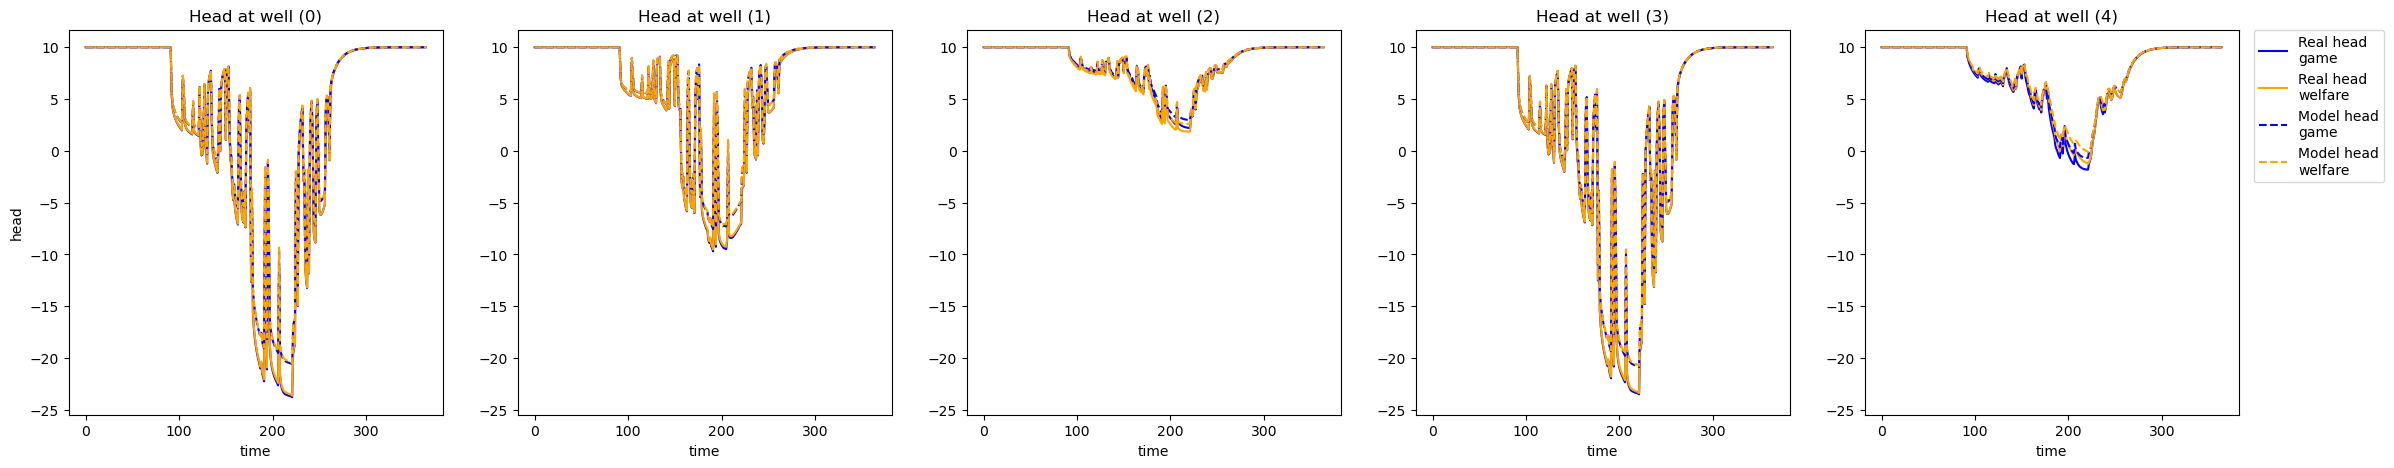

In [454]:
# Display heads evolution
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(5):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Head at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    ax_h.plot(data_si['h_wells'][ii, :], "b-", label="Real head\ngame")
    ax_h.plot(data_wf['h_wells'][ii, :], color="orange", label="Real head\nwelfare")
    ax_h.plot(data_si['corrected_h_wells'][ii, :], "b--", label="Model head\ngame")
    ax_h.plot(data_wf['corrected_h_wells'][ii, :], color="orange", linestyle="--", label="Model head\nwelfare")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

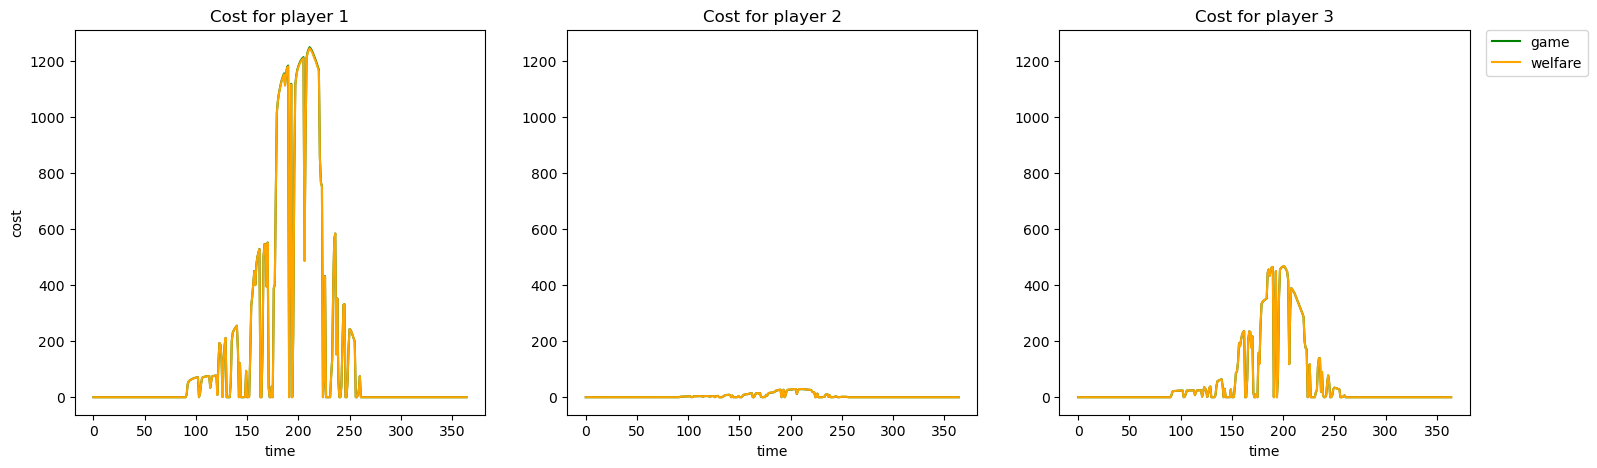

In [455]:
fig = plt.figure(figsize=(15+3,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Cost for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(-data_si['model_profit'][ii, :], 'g', label='game')
    ax.plot(-data_wf['model_profit'][ii, :], color="orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

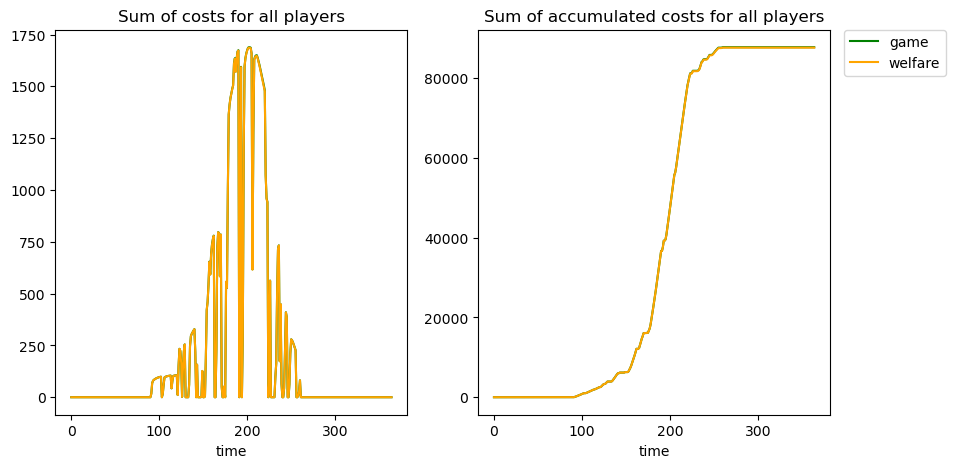

In [456]:
fig = plt.figure(figsize=(10,5))
ax = fig.add_subplot(1, 2, 1)
ttl = f"Sum of costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("cost")
ax.plot(-data_si['model_profit'].sum(axis=0), 'g')
ax.plot(-data_wf['model_profit'].sum(axis=0), color="orange")

ax = fig.add_subplot(1, 2, 2)
ttl = f"Sum of accumulated costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("cost")
ax.plot(-np.cumsum(data_si['model_profit'].sum(axis=0)), 'g', label='game')
ax.plot(-np.cumsum(data_wf['model_profit'].sum(axis=0)), color="orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

In [457]:
u_si = np.array([model.reorganize_input_per_well(data_si['inputs'][:,[k]]) for k in range(365)]).T
u_si = u_si.reshape((np.hstack(cost_model.n_well_per_command).sum(dtype=int), cost_model.n_crops, 365))
u_wf = np.array([model.reorganize_input_per_well(data_wf['inputs'][:,[k]]) for k in range(365)]).T
u_wf = u_wf.reshape((np.hstack(cost_model.n_well_per_command).sum(dtype=int), cost_model.n_crops, 365))

In [458]:
pumping_cost_si = np.zeros((cost_model.n_agent, 365))
under_irrigation_cost_si = np.zeros((cost_model.n_agent, 365))
pumping_cost_wf = np.zeros((cost_model.n_agent, 365))
under_irrigation_cost_wf = np.zeros((cost_model.n_agent, 365))
for v_1 in range(cost_model.n_agent):
    input_indices = np.nonzero(cost_model.well_to_cell[:,cost_model.well_to_agent==v_1].T)[1]
    well_index = np.arange(np.hstack(model.n_well_per_command).sum(), dtype=int)[model.well_to_agent==v_1]
    for t in range(364):
        pumping_cost_si[v_1,t] = (-cost_model.extraction_cost[v_1] * (cost_model.top_head[input_indices] -\
            data_si['h_wells'][[well_index], t+1].T) * u_si[cost_model.well_to_agent==v_1,:,t].sum(axis=1).reshape(-1,1)).sum()
        under_irrigation = water_req[v_1, :, t] + u_si[cost_model.well_to_agent==v_1,:,t].sum(axis=0)    # TODO: check dimensions
        under_irrigation_cost_si[v_1,t] = \
            under_irrigation.T @ sp.diags(under_irrigation_weight[v_1,:,t].flatten()) @ under_irrigation.T
        # Welfare costs
        pumping_cost_wf[v_1,t] = (-cost_model.extraction_cost[v_1] * (cost_model.top_head[input_indices] -\
            data_wf['h_wells'][[well_index], t+1].T) * u_wf[cost_model.well_to_agent==v_1,:,t].sum(axis=1).reshape(-1,1)).sum()
        under_irrigation = water_req[v_1, :, t] + u_wf[cost_model.well_to_agent==v_1,:,t].sum(axis=0)    # TODO: check dimensions
        under_irrigation_cost_wf[v_1,t] = \
            under_irrigation.T @ sp.diags(under_irrigation_weight[v_1,:,t].flatten()) @ under_irrigation.T
cost_si = pumping_cost_si + under_irrigation_cost_si
cost_wf = pumping_cost_wf + under_irrigation_cost_wf

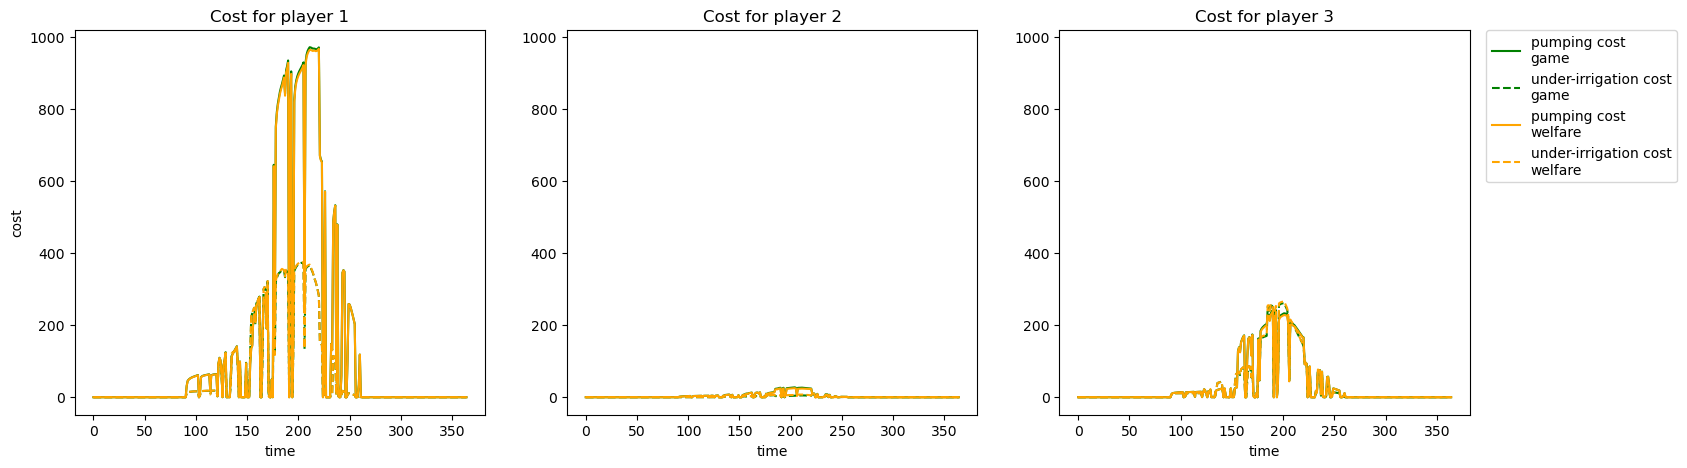

In [459]:
fig = plt.figure(figsize=(15+3,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Cost for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(pumping_cost_si[ii, :], 'g', label='pumping cost\ngame')
    ax.plot(under_irrigation_cost_si[ii, :], 'g--', label='under-irrigation cost\ngame')
    ax.plot(pumping_cost_wf[ii, :], color="orange", label='pumping cost\nwelfare')
    ax.plot(under_irrigation_cost_wf[ii, :], color="orange", linestyle="--", label='under-irrigation cost\nwelfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

In [460]:
epsilon = 1
pumping_cost_epsilon = np.zeros((5, cost_model.n_agent, 365))
under_irrigation_cost_epsilon = np.zeros((5, cost_model.n_agent, 365))
for w in range(n_well):
    u_incr = u_si.copy()
    u_incr = np.minimum((u_incr.T + 1000*np.roll(np.array([1]+[0]*(n_well-1)), w)).T, 0)
    for v_1 in range(cost_model.n_agent):
        input_indices = np.nonzero(cost_model.well_to_cell[:,cost_model.well_to_agent==v_1].T)[1]
        well_index = np.arange(np.hstack(model.n_well_per_command).sum(), dtype=int)[model.well_to_agent==v_1]
        for t in range(364):
            pumping_cost_epsilon[w,v_1,t] = (-cost_model.extraction_cost[v_1] * (cost_model.top_head[input_indices] -\
                data_si['h_wells'][[well_index], t+1].T) * u_incr[cost_model.well_to_agent==v_1,:,t].sum(axis=1).reshape(-1,1)).sum()
            under_irrigation = water_req[v_1, :, t] + u_incr[cost_model.well_to_agent==v_1,:,t].sum(axis=0)    # TODO: check dimensions
            under_irrigation_cost_epsilon[w, v_1,t] = \
                under_irrigation.T @ sp.diags(under_irrigation_weight[v_1,:,t].flatten()) @ under_irrigation.T
cost_epsilon = pumping_cost_epsilon + under_irrigation_cost_epsilon

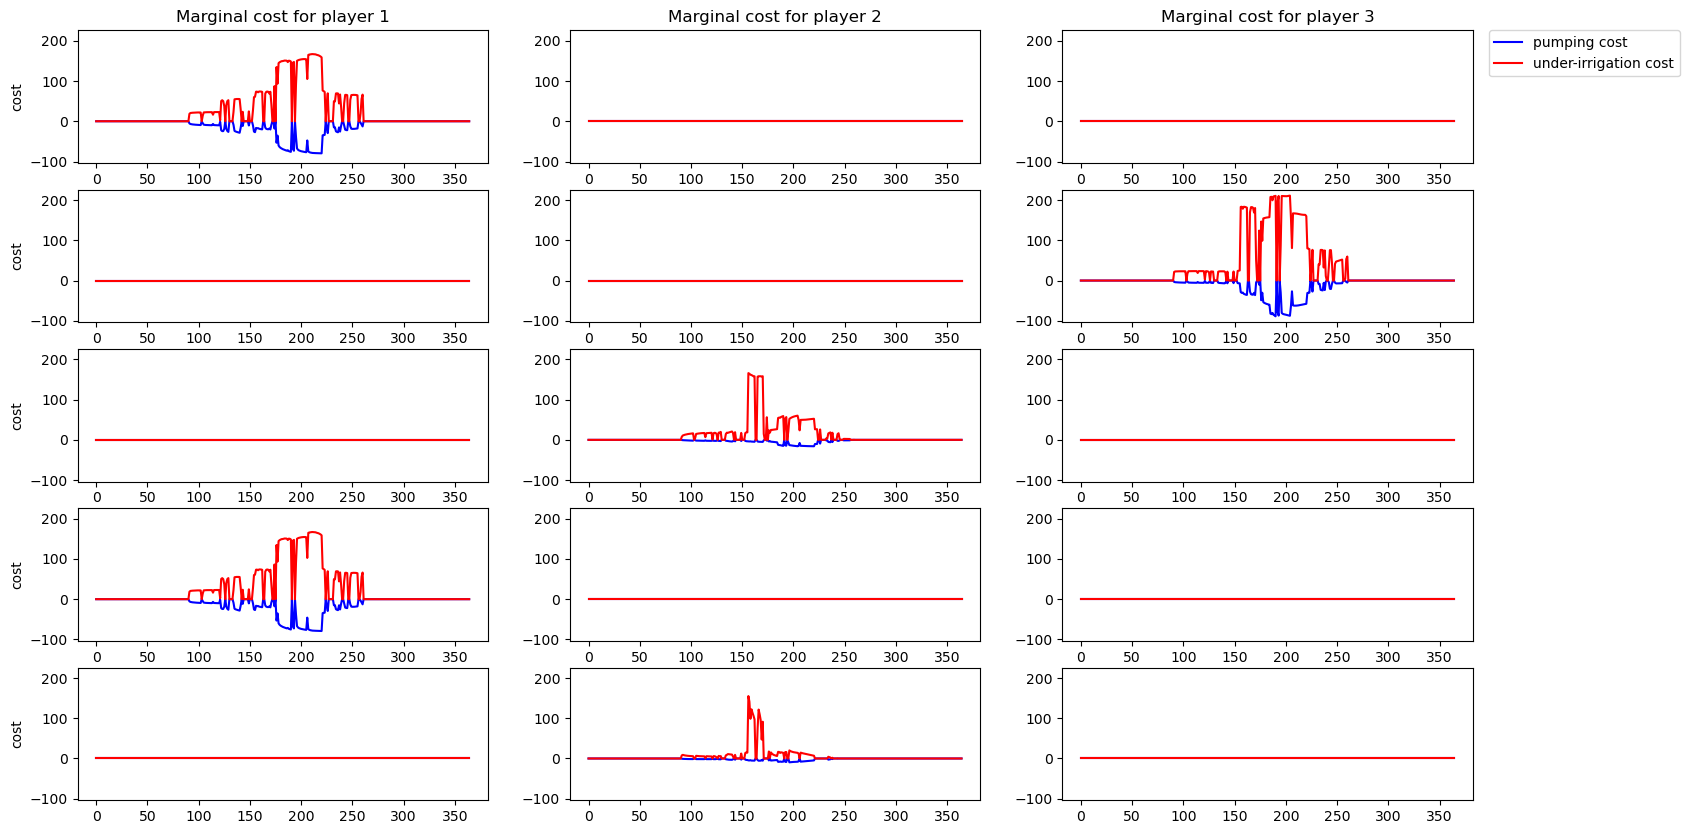

In [461]:
fig = plt.figure(figsize=(15+3,10))
ax = None
for w in range(n_well):
    for ii in range(3):
        ax = fig.add_subplot(n_well, 3, 3*w+ii+1, sharey=ax)
        ttl = f"Marginal cost for player {ii+1}"
        if w == 0:
            ax.set_title(ttl)
        if ii == 0:
            ax.set_ylabel("cost")
        ax.plot(pumping_cost_epsilon[w, ii, :] - pumping_cost_si[ii, :], 'b', label='pumping cost')
        ax.plot(under_irrigation_cost_epsilon[w, ii, :] - under_irrigation_cost_si[ii, :], 'r', label='under-irrigation cost')
        if ii == 2 and w==0:
            ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

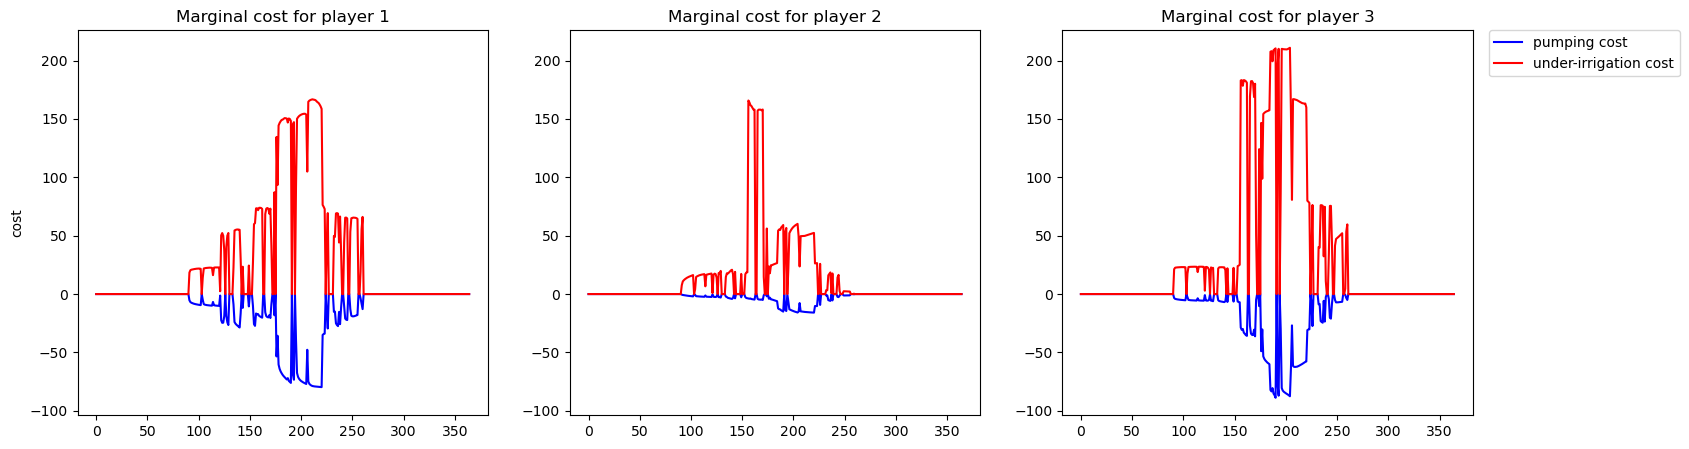

In [462]:
fig = plt.figure(figsize=(15+3,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Marginal cost for player {ii+1}"
    ax.set_title(ttl)
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(pumping_cost_epsilon[np.bool(well_to_agent[ii,:]), ii, :][0,...] - pumping_cost_si[ii, :], 'b', label='pumping cost')
    ax.plot(under_irrigation_cost_epsilon[np.bool(well_to_agent[ii,:]), ii, :][0,...] - under_irrigation_cost_si[ii, :], 'r', label='under-irrigation cost')
    if ii == 2:
        ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

In [463]:
ii=1
argmin = (pumping_cost_epsilon[np.bool(well_to_agent[ii,:]), ii, :][0,...] - pumping_cost_si[ii, :]).argmin()
(pumping_cost_epsilon[np.bool(well_to_agent[ii,:]), ii, :][0,...] - pumping_cost_si[ii, :]).min(), (under_irrigation_cost_epsilon[np.bool(well_to_agent[ii,:]), ii, :][0,...] - under_irrigation_cost_si[ii, :])[argmin]

(np.float64(-15.885941361587335), np.float64(52.39742326211608))

In [464]:
argmax = (under_irrigation_cost_epsilon[np.bool(well_to_agent[ii,:]), ii, :][0,...] - under_irrigation_cost_si[ii, :]).argmax()
(under_irrigation_cost_epsilon[np.bool(well_to_agent[ii,:]), ii, :][0,...] - under_irrigation_cost_si[ii, :]).max(), (pumping_cost_epsilon[np.bool(well_to_agent[ii,:]), ii, :][0,...] - pumping_cost_si[ii, :])[argmax]

(np.float64(165.78384583750713), np.float64(-3.80667639879883))

In [465]:
def compute_costs(q, b, v, t, k):
    input_indices = np.nonzero(cost_model.well_to_cell[:,cost_model.well_to_agent==v].T)[1]
    well_index = np.arange(np.hstack(model.n_well_per_command).sum(), dtype=int)[model.well_to_agent==v]
    pumping_cost = (-cost_model.extraction_cost[v] * (cost_model.top_head[input_indices][k] -\
        data_si['h_wells'][[well_index], t+1].T[k] + b * (q[cost_model.well_to_agent==v,t][k] - data_si['q_rates'][cost_model.well_to_agent==v,t][k]))\
            * q[cost_model.well_to_agent==v,t][k]).sum()
    under_irrigation = water_req[v, :, t].sum(axis=0) + q[cost_model.well_to_agent==v,t].sum()
    under_irrigation_cost = max(under_irrigation_weight[v,:,t].flatten()) * under_irrigation**2
    return pumping_cost, under_irrigation_cost

In [466]:
t = 200
# Optimal displacement for player 2
v_1 = 1
rho_1 = cost_model.extraction_cost[v_1]
b_11 = model.B_v[1][:,:4].max(axis=0).sum()
q_1 = -data_si['q_rates'][model.well_to_agent==v_1,t][-1]
cst = data_wf['corrected_h_wells'][model.well_to_agent==v_1, t-1][-1] # TODO: that only is an approximation
Ry_1 = max(under_irrigation_weight[v_1,:,t])
req_1 = sum(water_req[v_1,:,t])
delta_q_1 = (2*rho_1*b_11*q_1 - rho_1*(10-cst) + 2*Ry_1*(q_1-req_1))/(2*rho_1*b_11+Ry_1)
print(delta_q_1, q_1 - delta_q_1)
# Optimal displacement for player 1 and 2
v_2 = 0
rho_2 = cost_model.extraction_cost[v_2]
b_12 = model.B_v[1][46,0]*model.A[46,45]
q_2 = -data_si['q_rates'][model.well_to_agent==v_2,t][0]
delta_q_12 = delta_q_1 + (rho_2*b_12*q_2)/(2*rho_1*b_11+Ry_1)
print(delta_q_12, (rho_2*b_12*q_2)/(2*rho_1*b_11+Ry_1))

-5007.653136836771 5705.009505952585
-5009.895218168113 -2.2420813313420123


In [467]:
new_q_1 = data_si['q_rates'].copy()
new_q_1[model.well_to_agent==v_1,t] += delta_q_1
compute_costs(data_si['q_rates'], b_11, v_1, t, 1), compute_costs(new_q_1, b_11, v_1, t, 1)

((np.float64(8.546513983296782), np.float64(10.236750208565919)),
 (np.float64(4.964443200754887), np.float64(2432.582446856249)))

In [468]:
new_q_1 = data_si['q_rates'].copy()
new_q_1[4,t] -= (req_1 + data_si['q_rates'][cost_model.well_to_agent==v_1,t].sum())
compute_costs(new_q_1, b_11, v_1, t, 1)

(np.float64(14.21019813403276), np.float64(0.0))

In [469]:
data_si['q_rates'][cost_model.well_to_agent==v_1,t]

array([-2192.52441128,  -697.35636912])

In [470]:
data_si['inputs'][:,t]

array([-3.08433331e+03,  3.28596120e-15, -9.01516048e+03, -6.31084272e-15, -3.12621195e+03,  6.93257781e-15, -9.05703912e+03,  6.96579975e-15, -6.36264562e+02, -6.10918068e+01, -3.48477551e-16, -7.68882318e-17, -1.38384858e+03, -8.08675828e+02, -5.44963048e-16, -6.42006751e-16, -3.40108064e+03, -9.11824330e+02, -3.67841137e+03, -2.67823731e+03])

In controller class result yield to negative cost.

Maybe due to the fact that we did not count the constant part in demand satisfaction cost.

TODO: Study how the cost evolve when player 1 pump less
- store U_opt(200) from simulation
- work from here to compare parts of the cost using matrices given by cost_model.

In [471]:
tmp_data = np.load("tmp.npz")
U_opt = tmp_data['U_opt']
x_0 = tmp_data['x_0']

In [472]:
U_opt.shape

(200, 1)

In [473]:
t= 200
horizon = 10

Q, R, R_minus, M, L = cost_model.get_cost_matrices(t, horizon)
controller.update_cost_matrices(Q, R, R_minus, M, L)

In [474]:
test_1 = [(i+1)*np.ones((4,4)) for i in range(3)] + [4*np.ones((8,8))]
test_2 = [np.zeros((4,16)) for _ in range(3)] + [np.zeros((8,12))]
nu_test = [4,4,4,8]
np.vstack([np.insert(test_2[v], np.cumsum([0]+nu_test)[v], test_1[v], axis=1) for v in range(4)])

array([[1., 1., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [1., 1., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [1., 1., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [1., 1., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 2., 2., 2., 2., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 2., 2., 2., 2., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 2., 2., 2., 2., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 2., 2., 2., 2., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 3., 3., 3., 3., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 3., 3., 3., 3., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 3., 3., 3., 3., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0

In [475]:
R_agg = np.vstack([np.insert(controller.R_v_minus_v[v], 10*(np.cumsum([0]+controller.nu_v)[v]), controller.R_vv[v].toarray().T, axis=1) for v in range(model.n_agent)])
U_opt.T @ R_agg @ U_opt + x_0.T @ sp.hstack(controller.M_x_v) @ U_opt + sp.hstack(controller.L_v_tilde) @ U_opt

array([[-64387.01930691]])

In [476]:
# Only pumping cost (and regularization)
reg = [1e-10 * np.eye(cost_model.Rp_v[v].shape[0])
        for v in range(cost_model.n_agent)]
# Form matrices
Q = None
R = [[cost_model.Rp_v[v] + reg[v] for t in range(horizon)]
            for v in range(cost_model.n_agent)]
R_minus = [[cost_model.Rp_v_minus[v] for t in range(horizon)]
                    for v in range(cost_model.n_agent)]
M = [[cost_model.Mp_v[v] for t in range(horizon)]
            for v in range(cost_model.n_agent)]
L = [[cost_model.Lp_v[v] for t in range(horizon)]
            for v in range(cost_model.n_agent)]

controller.update_cost_matrices(Q, R, R_minus, M, L)

In [477]:
R_p = np.vstack([np.insert(controller.R_v_minus_v[v], 10*(np.cumsum([0]+controller.nu_v)[v]), controller.R_vv[v].toarray().T, axis=1) for v in range(model.n_agent)])
M_p = sp.hstack(controller.M_x_v)
L_p = sp.hstack(controller.L_v_tilde)
U_opt.T @ R_p @ U_opt + x_0.T @ M_p @ U_opt + L_p @ U_opt

array([[10978.24201099]])

In [478]:
# Only under-irrigation (and regularization)
cost_model._compute_under_irrigation_cost_matrices(t, horizon)
# Add regularization to R_v to ensure non-singularity
reg = [1e-10 * np.eye(cost_model.Rp_v[v].shape[0])
        for v in range(cost_model.n_agent)]
# Form matrices
Q = None
R = [[cost_model.Ri_v[v][t] + reg[v] for t in range(horizon)]
            for v in range(cost_model.n_agent)]
R_minus = None
M = None
L = [[cost_model.Li_v[v][t] for t in range(horizon)]
            for v in range(cost_model.n_agent)]

controller.update_cost_matrices(Q, R, R_minus, M, L)

In [479]:
R_i = np.vstack([np.insert(controller.R_v_minus_v[v], 10*(np.cumsum([0]+controller.nu_v)[v]), controller.R_vv[v].toarray().T, axis=1) for v in range(model.n_agent)])
M_i = sp.hstack(controller.M_x_v)
L_i = sp.hstack(controller.L_v_tilde)
U_opt.T @ R_i @ U_opt + x_0.T @ M_i @ U_opt + L_i @ U_opt

array([[-75365.05261402]])

In [480]:
controller._solution_to_command(U_opt).round(1)

array([[-3084.3,     0. , -9015.2,    -0. , -3126.2,     0. , -9057. ,     0. ,  -636.3,   -61.1,    -0. ,    -0. , -1383.8,  -808.7,    -0. ,    -0. , -3401.1,  -911.8, -3678.4, -2678.2],
       [-3085.3,    -0. , -9016.2,     0. , -3125. ,     0. , -9055.9,     0. ,  -655.8,   -80.8,     0. ,     0. , -1363.5,  -788.5,    -0. ,    -0. , -3387.5,  -884.4, -3668.2, -2649.6],
       [-3102.8,    -0. , -9024.5,    -0. , -3134.7,     0. , -9056.4,     0. ,  -661.4,   -86.6,    -0. ,    -0. , -1356.9,  -782.1,    -0. ,    -0. , -3391.8,  -893.1, -3671.5, -2554.6],
       [-3127.3,    -0. , -9034.3,    -0. , -3153.4,     0. , -9060.4,     0. ,  -661.3,   -86.7,    -0. ,    -0. , -1355.9,  -781.3,    -0. ,    -0. , -3401.4,  -912.4, -3678.6, -2469.2],
       [-3161.1,    -0. , -9046.4,     0. , -3183.4,    -0. , -9068.7,     0. ,  -658.3,   -83.8,     0. ,     0. , -1358.3,  -783.8,    -0. ,    -0. , -3416.4,  -942.8, -3689.9, -2392.4],
       [-3216.5,     0. , -9065. ,     0. , -3236.4,   

##### Pump to requirement

In [481]:
ET = cost_model._get_water_requirement(t, horizon)
U_ET = -np.hstack([np.tile([(ET[0,:,ti]/2) for ti in range(horizon)],2).flatten(), np.tile([(ET[1,:,ti]/2) for ti in range(horizon)],2).flatten(), np.hstack([ET[2,:,ti] for ti in range(horizon)]).flatten()]).reshape(200,1)
U_ET.T @ R_i @ U_ET + x_0.T @ M_i @ U_ET + L_i @ U_ET

array([[-80786.1946947]])

In [482]:
print(f"c_p(opt) - c_p(ET) = {U_opt.T @ R_p @ U_opt + x_0.T @ M_p @ U_opt + L_p @ U_opt} - {U_ET.T @ R_p @ U_ET + x_0.T @ M_p @ U_ET + L_p @ U_ET} = {U_opt.T @ R_p @ U_opt + x_0.T @ M_p @ U_opt + L_p @ U_opt - (U_ET.T @ R_p @ U_ET + x_0.T @ M_p @ U_ET + L_p @ U_ET)}")
print(f"c_i(opt) - c_i(ET) = {U_opt.T @ R_i @ U_opt + x_0.T @ M_i @ U_opt + L_i @ U_opt} - {U_ET.T @ R_i @ U_ET + x_0.T @ M_i @ U_ET + L_i @ U_ET} = {U_opt.T @ R_i @ U_opt + x_0.T @ M_i @ U_opt + L_i @ U_opt - (U_ET.T @ R_i @ U_ET + x_0.T @ M_i @ U_ET + L_i @ U_ET)}")

c_p(opt) - c_p(ET) = [[10978.24201099]] - [[25524.93299785]] = [[-14546.69098686]]
c_i(opt) - c_i(ET) = [[-75365.05261402]] - [[-80786.1946947]] = [[5421.14208069]]


##### Decrease pump at first time-step

In [483]:
delta_pump = 1
pump_indices = [[0,4], [4,8], [80, 84], [84, 88], [160, 164]]
for pump in range(n_well):
    U_decr = U_opt.copy()
    U_decr[pump_indices[pump][0]:pump_indices[pump][1]] = np.minimum(U_decr[pump_indices[pump][0]:pump_indices[pump][1]] + delta_pump/np.count_nonzero(U_decr[pump_indices[pump][0]:pump_indices[pump][1]]<-1), 0)
    print(f"c_p(opt) - c_p(decr) = {U_opt.T @ R_p @ U_opt + x_0.T @ M_p @ U_opt + L_p @ U_opt} - {U_decr.T @ R_p @ U_decr + x_0.T @ M_p @ U_decr + L_p @ U_decr} = {U_opt.T @ R_p @ U_opt + x_0.T @ M_p @ U_opt + L_p @ U_opt - (U_decr.T @ R_p @ U_decr + x_0.T @ M_p @ U_decr + L_p @ U_decr)}")
    print(f"c_i(opt) - c_i(decr) = {U_opt.T @ R_i @ U_opt + x_0.T @ M_i @ U_opt + L_i @ U_opt} - {U_decr.T @ R_i @ U_decr + x_0.T @ M_i @ U_decr + L_i @ U_decr} = {U_opt.T @ R_i @ U_opt + x_0.T @ M_i @ U_opt + L_i @ U_opt - (U_decr.T @ R_i @ U_decr + x_0.T @ M_i @ U_decr + L_i @ U_decr)}\n")

c_p(opt) - c_p(decr) = [[10978.24201099]] - [[10978.17320581]] = [[0.06880517]]
c_i(opt) - c_i(decr) = [[-75365.05261402]] - [[-75364.98436489]] = [[-0.06824913]]

c_p(opt) - c_p(decr) = [[10978.24201099]] - [[10978.17322575]] = [[0.06878524]]
c_i(opt) - c_i(decr) = [[-75365.05261402]] - [[-75364.9843649]] = [[-0.06824912]]

c_p(opt) - c_p(decr) = [[10978.24201099]] - [[10978.22386011]] = [[0.01815088]]
c_i(opt) - c_i(decr) = [[-75365.05261402]] - [[-75365.03994021]] = [[-0.01267381]]

c_p(opt) - c_p(decr) = [[10978.24201099]] - [[10978.22787176]] = [[0.01413922]]
c_i(opt) - c_i(decr) = [[-75365.05261402]] - [[-75365.03994036]] = [[-0.01267366]]

c_p(opt) - c_p(decr) = [[10978.24201099]] - [[10978.19676072]] = [[0.04525027]]
c_i(opt) - c_i(decr) = [[-75365.05261402]] - [[-75365.00819197]] = [[-0.04442204]]



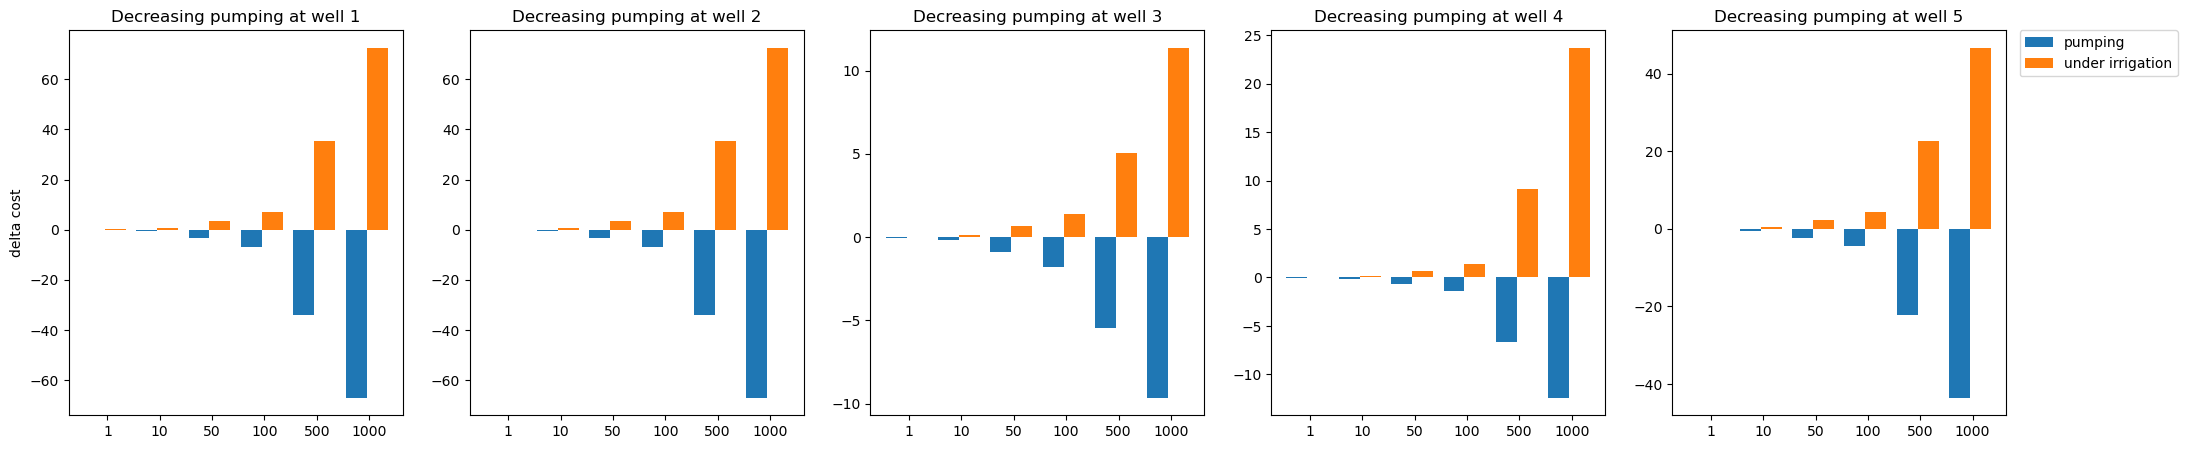

In [484]:
delta_pumps = np.array([1, 10, 50, 100, 500, 1000])
delta_p = np.zeros((len(delta_pumps), n_well))
delta_i = np.zeros((len(delta_pumps), n_well))
for i, delta_pump in enumerate(delta_pumps):
    for pump in range(n_well):
        U_decr = U_opt.copy()
        U_decr[pump_indices[pump][0]:pump_indices[pump][1]] = np.minimum(U_decr[pump_indices[pump][0]:pump_indices[pump][1]] + delta_pump/np.count_nonzero(U_decr[pump_indices[pump][0]:pump_indices[pump][1]]<-1), 0)
        delta_p[i, pump]  = -(U_opt.T @ R_p @ U_opt + x_0.T @ M_p @ U_opt + L_p @ U_opt - (U_decr.T @ R_p @ U_decr + x_0.T @ M_p @ U_decr + L_p @ U_decr))[0,0]
        delta_i[i, pump]  = -(U_opt.T @ R_i @ U_opt + x_0.T @ M_i @ U_opt + L_i @ U_opt - (U_decr.T @ R_i @ U_decr + x_0.T @ M_i @ U_decr + L_i @ U_decr))[0,0]

fig = plt.figure(figsize=(25,5))
for pump in range(n_well):
    ax = fig.add_subplot(1, n_well, pump+1)
    ttl = f"Decreasing pumping at well {pump+1}"
    ax.set_title(ttl)
    if pump == 0:
        ax.set_ylabel("delta cost")
    rects = ax.bar(np.arange(len(delta_pumps)), delta_p[:,pump], width=0.40, label="pumping")
    rects = ax.bar(np.arange(len(delta_pumps))+0.40, delta_i[:,pump], width=0.40, label="under irrigation")
    ax.set_xticks(np.arange(len(delta_pumps))+0.25, delta_pumps.astype(str))
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

In [485]:
delta_pump = 1000
pump = 3

U_decr = U_opt.copy()
U_decr[pump_indices[pump][0]:pump_indices[pump][1]] = np.minimum(U_decr[pump_indices[pump][0]:pump_indices[pump][1]] + delta_pump/np.count_nonzero(U_decr[pump_indices[pump][0]:pump_indices[pump][1]]<-1), 0)
print(f"c_p(opt) - c_p(decr) = {U_opt.T @ R_p @ U_opt + x_0.T @ M_p @ U_opt + L_p @ U_opt} - {U_decr.T @ R_p @ U_decr + x_0.T @ M_p @ U_decr + L_p @ U_decr} = {U_opt.T @ R_p @ U_opt + x_0.T @ M_p @ U_opt + L_p @ U_opt - (U_decr.T @ R_p @ U_decr + x_0.T @ M_p @ U_decr + L_p @ U_decr)}")
print(f"c_i(opt) - c_i(decr) = {U_opt.T @ R_i @ U_opt + x_0.T @ M_i @ U_opt + L_i @ U_opt} - {U_decr.T @ R_i @ U_decr + x_0.T @ M_i @ U_decr + L_i @ U_decr} = {U_opt.T @ R_i @ U_opt + x_0.T @ M_i @ U_opt + L_i @ U_opt - (U_decr.T @ R_i @ U_decr + x_0.T @ M_i @ U_decr + L_i @ U_decr)}")
print(f"c(opt)   - c(decr)   = {U_opt.T @ R_i @ U_opt + x_0.T @ M_i @ U_opt + L_i @ U_opt + U_opt.T @ R_p @ U_opt + x_0.T @ M_p @ U_opt + L_p @ U_opt} - {U_decr.T @ R_i @ U_decr + x_0.T @ M_i @ U_decr + L_i @ U_decr + U_decr.T @ R_p @ U_decr + x_0.T @ M_p @ U_decr + L_p @ U_decr} =\
    {U_opt.T @ R_i @ U_opt + x_0.T @ M_i @ U_opt + L_i @ U_opt + U_opt.T @ R_p @ U_opt + x_0.T @ M_p @ U_opt + L_p @ U_opt - (U_decr.T @ R_i @ U_decr + x_0.T @ M_i @ U_decr + L_i @ U_decr + U_decr.T @ R_p @ U_decr + x_0.T @ M_p @ U_decr + L_p @ U_decr)}")

c_p(opt) - c_p(decr) = [[10978.24201099]] - [[10965.82950782]] = [[12.41250316]]
c_i(opt) - c_i(decr) = [[-75365.05261402]] - [[-75341.34827898]] = [[-23.70433503]]
c(opt)   - c(decr)   = [[-64386.81060303]] - [[-64375.51877116]] =    [[-11.29183187]]


In [486]:
Q, R, R_minus, M, L = cost_model.get_cost_matrices(t, horizon)
welfare.update_cost_matrices(Q, R, R_minus, M, L)
U_welfare = welfare._solve_problem(x_0)[0]

In [487]:
U_welfare.T @ R_i @ U_welfare + x_0.T @ M_i @ U_welfare + L_i @ U_welfare + U_welfare.T @ R_p @ U_welfare + x_0.T @ M_p @ U_welfare + L_p @ U_welfare,\
U_welfare.T @ R_agg @ U_welfare + x_0.T @ sp.hstack(controller.M_x_v) @ U_welfare + sp.hstack(controller.L_v_tilde) @ U_welfare

(array([[-64392.45555124]]), array([[-64392.66440483]]))

In [488]:
welfare.m.ObjVal

-64392664.402909204

In [489]:
print(f"c_p(game) - c_p(welfare) = {U_opt.T @ R_p @ U_opt + x_0.T @ M_p @ U_opt + L_p @ U_opt} - {U_welfare.T @ R_p @ U_welfare + x_0.T @ M_p @ U_welfare + L_p @ U_welfare} = {U_opt.T @ R_p @ U_opt + x_0.T @ M_p @ U_opt + L_p @ U_opt - (U_welfare.T @ R_p @ U_welfare + x_0.T @ M_p @ U_welfare + L_p @ U_welfare)}")
print(f"c_i(game) - c_i(welfare) = {U_opt.T @ R_i @ U_opt + x_0.T @ M_i @ U_opt + L_i @ U_opt} - {U_welfare.T @ R_i @ U_welfare + x_0.T @ M_i @ U_welfare + L_i @ U_welfare} = {U_opt.T @ R_i @ U_opt + x_0.T @ M_i @ U_opt + L_i @ U_opt - (U_welfare.T @ R_i @ U_welfare + x_0.T @ M_i @ U_welfare + L_i @ U_welfare)}")
print(f"c(game)   - c(welfare)   = {U_opt.T @ R_i @ U_opt + x_0.T @ M_i @ U_opt + L_i @ U_opt + U_opt.T @ R_p @ U_opt + x_0.T @ M_p @ U_opt + L_p @ U_opt} - {U_welfare.T @ R_i @ U_welfare + x_0.T @ M_i @ U_welfare + L_i @ U_welfare + U_welfare.T @ R_p @ U_welfare + x_0.T @ M_p @ U_welfare + L_p @ U_welfare} =\
    {U_opt.T @ R_i @ U_opt + x_0.T @ M_i @ U_opt + L_i @ U_opt + U_opt.T @ R_p @ U_opt + x_0.T @ M_p @ U_opt + L_p @ U_opt - (U_welfare.T @ R_i @ U_welfare + x_0.T @ M_i @ U_welfare + L_i @ U_welfare + U_welfare.T @ R_p @ U_welfare + x_0.T @ M_p @ U_welfare + L_p @ U_welfare)}")

c_p(game) - c_p(welfare) = [[10978.24201099]] - [[10933.0807814]] = [[45.16122959]]
c_i(game) - c_i(welfare) = [[-75365.05261402]] - [[-75325.53633264]] = [[-39.51628138]]
c(game)   - c(welfare)   = [[-64386.81060303]] - [[-64392.45555124]] =    [[5.64494821]]


Maybe the difference between game and welfare is not so great because actors with strong interactions both have another close well to the interacting ones.

So they have self interest to reduce the interactions with their own well.

What if:
- one actor have low demand but strong interaction with its neighbor(s)

Or maybe the problems comes from the fact that we define common welfare as:
$$\sum_{actors} ||requirement - irrigation||_{R_y}$$
instead of :
$$||\sum_{actors} requirement - irrigation||_{R_y}$$
But the latter doesn't make a lot of sense because of the different sensitivity to irrigation for the ≠ actors.

##### Impact of one pumping decrease over other players cost

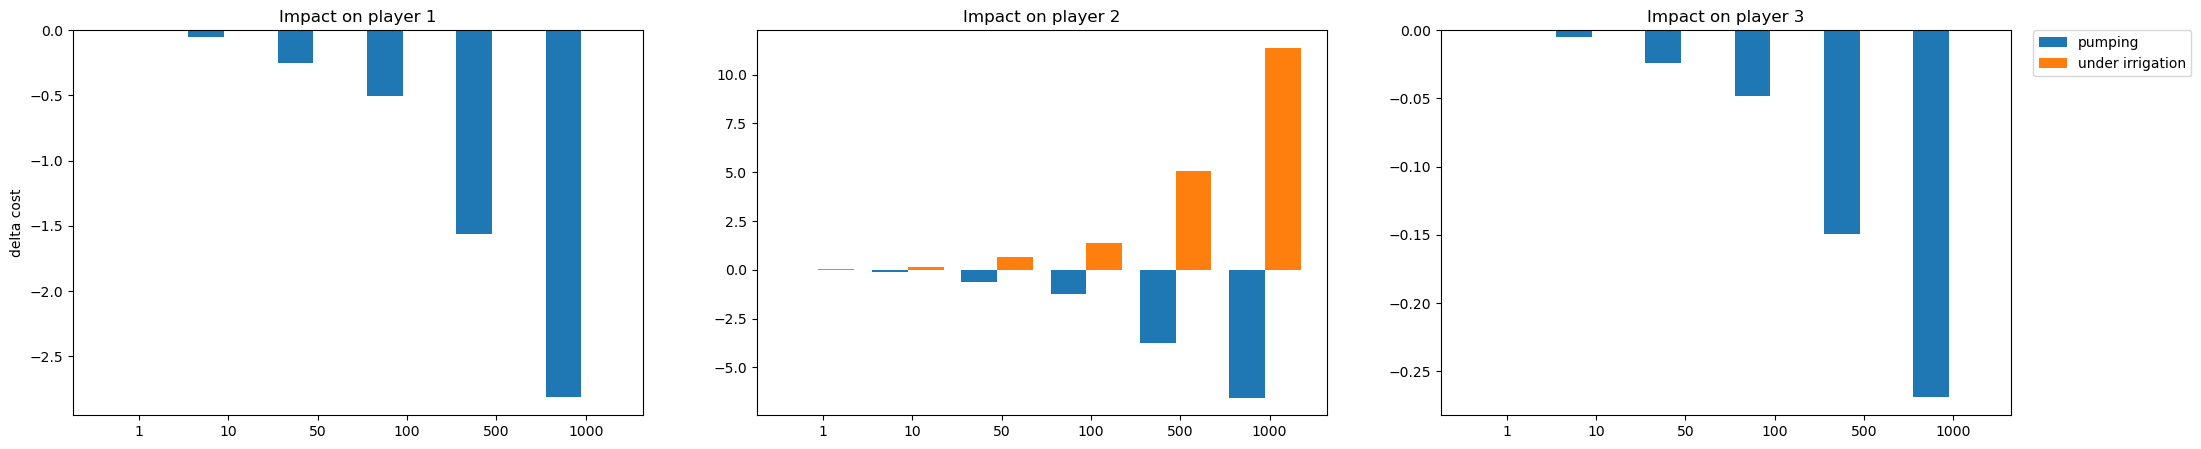

In [ ]:
pump = 0

indices = 10* np.cumsum([0]+model.nu_v)
delta_pumps = np.array([1, 10, 50, 100, 500, 1000])
delta_p = np.zeros((len(delta_pumps), model.n_agent))
delta_i = np.zeros((len(delta_pumps), model.n_agent))
for i, delta_pump in enumerate(delta_pumps):
    U_decr = U_opt.copy()
    U_decr[pump_indices[pump][0]:pump_indices[pump][1]] = np.minimum(U_decr[pump_indices[pump][0]:pump_indices[pump][1]] + delta_pump/np.count_nonzero(U_decr[pump_indices[pump][0]:pump_indices[pump][1]]<-1), 0)
    for well in range(model.n_agent):
        delta_p[i, well]  = -(U_opt[indices[well]:indices[well+1],:].T @ R_p[indices[well]:indices[well+1],:] @ U_opt + x_0.T @ M_p[:,indices[well]:indices[well+1]] @ U_opt[indices[well]:indices[well+1],:] + L_p[:,indices[well]:indices[well+1]] @ U_opt[indices[well]:indices[well+1],:] -\
            (U_decr[indices[well]:indices[well+1],:].T @ R_p[indices[well]:indices[well+1],:] @ U_decr + x_0.T @ M_p[:,indices[well]:indices[well+1]] @ U_decr[indices[well]:indices[well+1],:] + L_p[:,indices[well]:indices[well+1]] @ U_decr[indices[well]:indices[well+1],:]))[0,0]
        delta_i[i, well]  = -(U_opt[indices[well]:indices[well+1],:].T @ R_i[indices[well]:indices[well+1],:] @ U_opt + x_0.T @ M_i[:,indices[well]:indices[well+1]] @ U_opt[indices[well]:indices[well+1],:] + L_i[:,indices[well]:indices[well+1]] @ U_opt[indices[well]:indices[well+1],:] -\
            (U_decr[indices[well]:indices[well+1],:].T @ R_i[indices[well]:indices[well+1],:] @ U_decr + x_0.T @ M_i[:,indices[well]:indices[well+1]] @ U_decr[indices[well]:indices[well+1],:] + L_i[:,indices[well]:indices[well+1]] @ U_decr[indices[well]:indices[well+1],:]))[0,0]

fig = plt.figure(figsize=(25,5))
for player in range(model.n_agent):
    ax = fig.add_subplot(1, model.n_agent, player+1)
    ttl = f"Impact on player {player+1}"
    ax.set_title(ttl)
    if player == 0:
        ax.set_ylabel("delta cost")
    rects = ax.bar(np.arange(len(delta_pumps)), delta_p[:,player], width=0.40, label="pumping")
    rects = ax.bar(np.arange(len(delta_pumps))+0.40, delta_i[:,player], width=0.40, label="under irrigation")
    ax.set_xticks(np.arange(len(delta_pumps))+0.25, delta_pumps.astype(str))
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

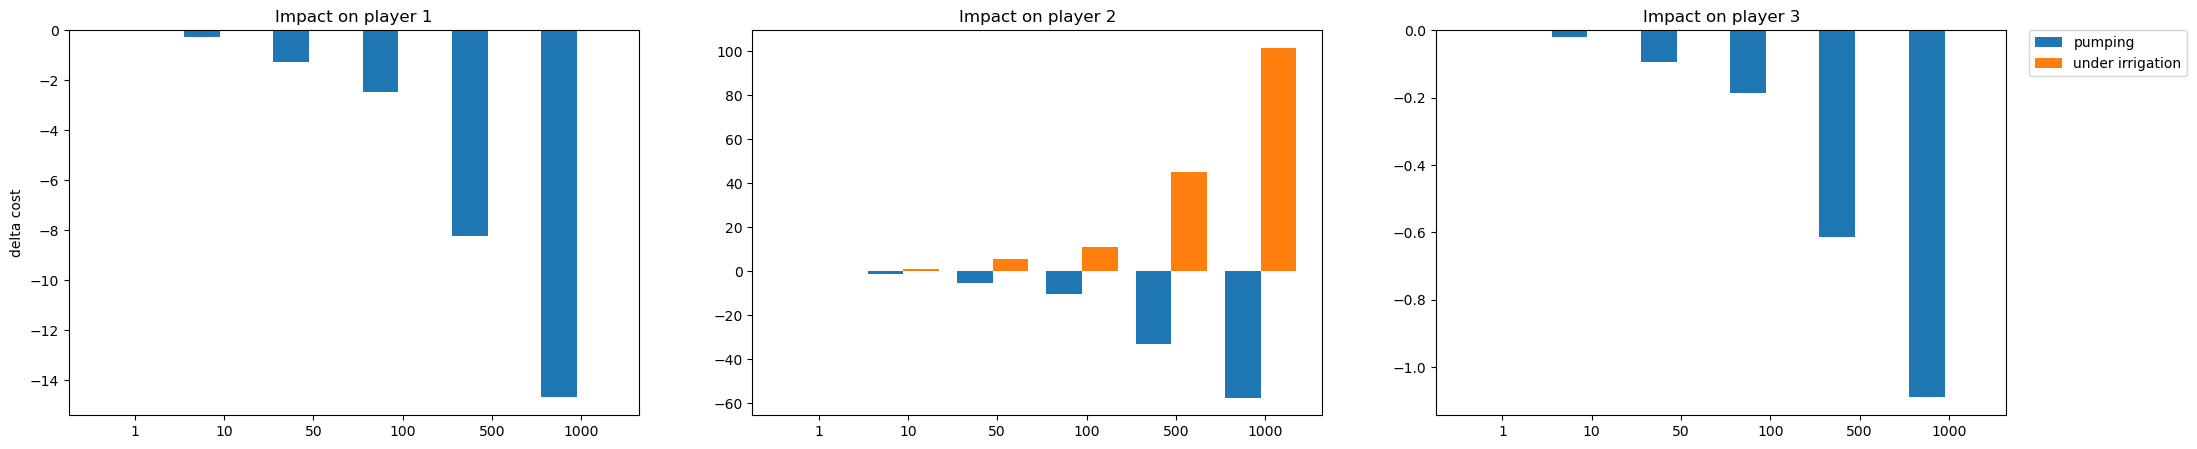

In [751]:
indices = 10* np.cumsum([0]+model.nu_v)
delta_pumps = np.array([1, 10, 50, 100, 500, 1000])
delta_p = np.zeros((len(delta_pumps), model.n_agent))
delta_i = np.zeros((len(delta_pumps), model.n_agent))
for i, delta_pump in enumerate(delta_pumps):
    n_u_v = model.nu_v[sorted(model.well_to_agent)[pump]]
    U_decr = U_opt.copy()
    for ts in range(horizon):
        U_decr[(pump_indices[pump][0]+ts*n_u_v):(pump_indices[pump][1]+ts*n_u_v)] = np.minimum(U_decr[(pump_indices[pump][0]+ts*n_u_v):(pump_indices[pump][1]+ts*n_u_v)] + delta_pump/np.count_nonzero(U_decr[(pump_indices[pump][0]+ts*n_u_v):(pump_indices[pump][1]+ts*n_u_v)]<-1), 0)
    for well in range(model.n_agent):
        delta_p[i, well]  = -(U_opt[indices[well]:indices[well+1],:].T @ R_p[indices[well]:indices[well+1],:] @ U_opt + x_0.T @ M_p[:,indices[well]:indices[well+1]] @ U_opt[indices[well]:indices[well+1],:] + L_p[:,indices[well]:indices[well+1]] @ U_opt[indices[well]:indices[well+1],:] -\
            (U_decr[indices[well]:indices[well+1],:].T @ R_p[indices[well]:indices[well+1],:] @ U_decr + x_0.T @ M_p[:,indices[well]:indices[well+1]] @ U_decr[indices[well]:indices[well+1],:] + L_p[:,indices[well]:indices[well+1]] @ U_decr[indices[well]:indices[well+1],:]))[0,0]
        delta_i[i, well]  = -(U_opt[indices[well]:indices[well+1],:].T @ R_i[indices[well]:indices[well+1],:] @ U_opt + x_0.T @ M_i[:,indices[well]:indices[well+1]] @ U_opt[indices[well]:indices[well+1],:] + L_i[:,indices[well]:indices[well+1]] @ U_opt[indices[well]:indices[well+1],:] -\
            (U_decr[indices[well]:indices[well+1],:].T @ R_i[indices[well]:indices[well+1],:] @ U_decr + x_0.T @ M_i[:,indices[well]:indices[well+1]] @ U_decr[indices[well]:indices[well+1],:] + L_i[:,indices[well]:indices[well+1]] @ U_decr[indices[well]:indices[well+1],:]))[0,0]

fig = plt.figure(figsize=(25,5))
for player in range(model.n_agent):
    ax = fig.add_subplot(1, model.n_agent, player+1)
    ttl = f"Impact on player {player+1}"
    ax.set_title(ttl)
    if player == 0:
        ax.set_ylabel("delta cost")
    rects = ax.bar(np.arange(len(delta_pumps)), delta_p[:,player], width=0.40, label="pumping")
    rects = ax.bar(np.arange(len(delta_pumps))+0.40, delta_i[:,player], width=0.40, label="under irrigation")
    ax.set_xticks(np.arange(len(delta_pumps))+0.25, delta_pumps.astype(str))
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

The impact of pumping reduction is very limited on other player relatively to oneself --> Players are almost independents.

=> Game ~= Welfare

##### Impact on head of pumping reduction

In [500]:
pump=1
delta_pump= 1000

U_decr = U_opt.copy()
U_decr[pump_indices[pump][0]:pump_indices[pump][1]] = np.minimum(U_decr[pump_indices[pump][0]:pump_indices[pump][1]] + delta_pump/np.count_nonzero(U_decr[pump_indices[pump][0]:pump_indices[pump][1]]<-1), 0)

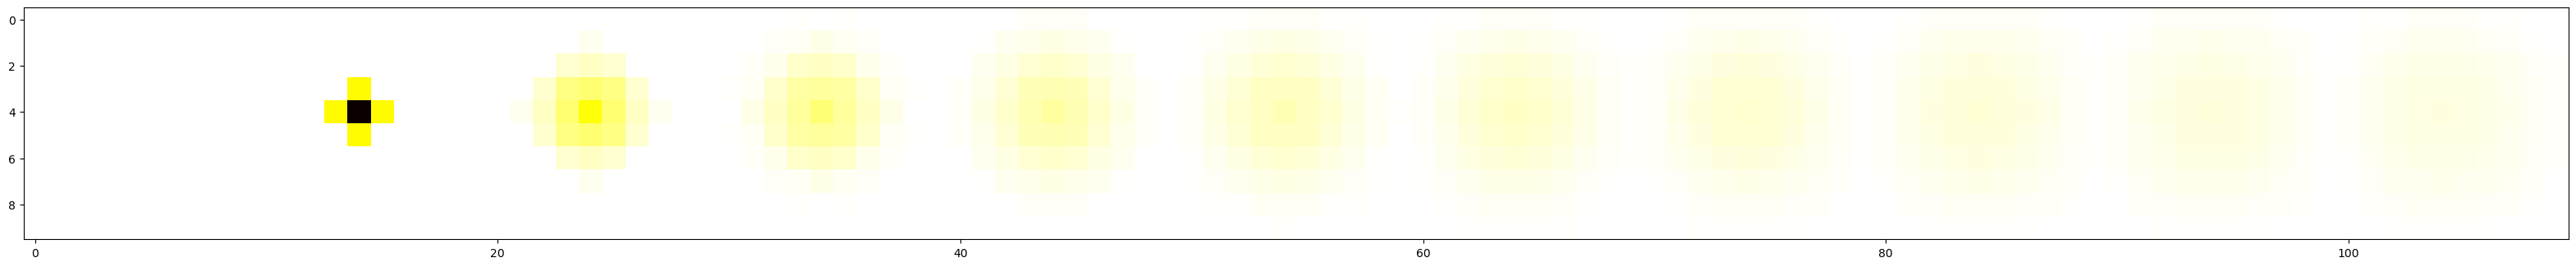

In [501]:
fig = plt.figure(figsize=(40, 440))
ax = fig.add_subplot(1,1,1)
ax.imshow(np.hstack((sp.hstack(controller.B_v_tilde) @ U_opt).reshape(11,10,10) - (sp.hstack(controller.B_v_tilde) @ U_decr).reshape(11,10,10)), cmap='hot', interpolation='nearest')

In [502]:
n_u_v = model.nu_v[sorted(model.well_to_agent)[pump]]
U_decr = U_opt.copy()
for ts in range(horizon):
    U_decr[(pump_indices[pump][0]+ts*n_u_v):(pump_indices[pump][1]+ts*n_u_v)] = np.minimum(U_decr[(pump_indices[pump][0]+ts*n_u_v):(pump_indices[pump][1]+ts*n_u_v)] + delta_pump/np.count_nonzero(U_decr[(pump_indices[pump][0]+ts*n_u_v):(pump_indices[pump][1]+ts*n_u_v)]<-1), 0)

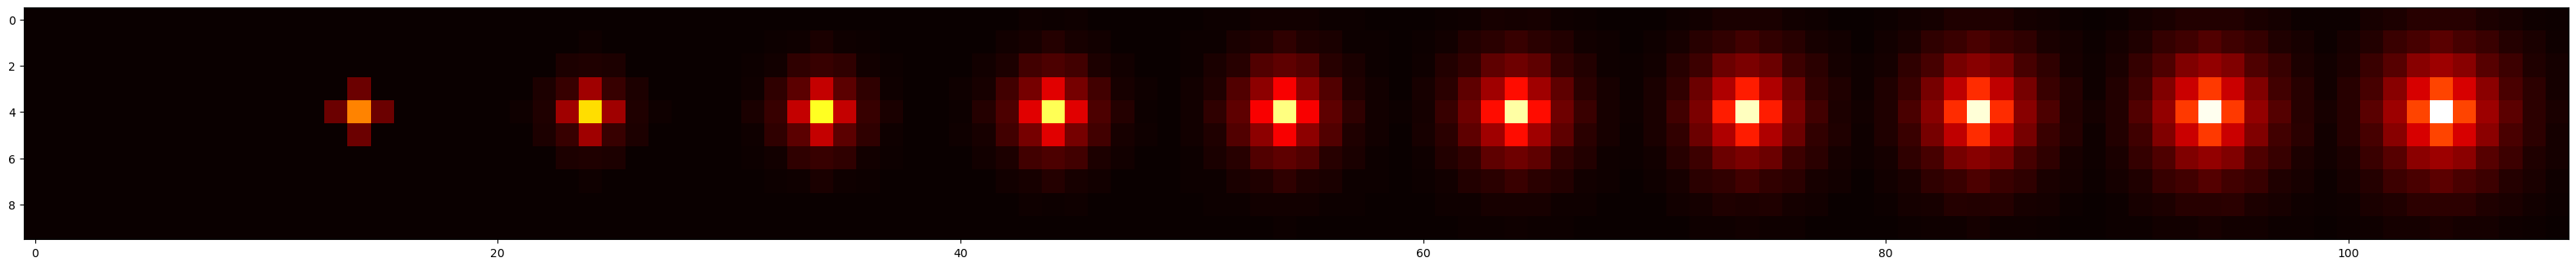

In [623]:
delta_h = -((sp.hstack(controller.B_v_tilde) @ U_opt).reshape(11,10,10) - (sp.hstack(controller.B_v_tilde) @ U_decr).reshape(11,10,10))

fig = plt.figure(figsize=(40, 440))
ax = fig.add_subplot(1,1,1)
ax.imshow(np.hstack(delta_h), cmap='hot', interpolation='nearest')

In [624]:
_, i = np.unique(np.nonzero((model.well_to_cell @ model.input_to_pumping_in_well).T)[1], return_index=True)
well_ind = np.nonzero((model.well_to_cell @ model.input_to_pumping_in_well).T)[1][sorted(i)]
well_ind = np.unravel_index(well_ind, (10,10))
well_ind

(array([5, 4, 4, 2, 8]), array([4, 4, 6, 7, 7]))

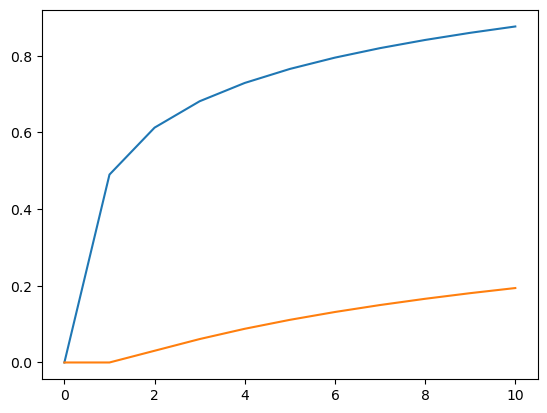

In [688]:
plt.plot(delta_h[:,well_ind[0][pump],well_ind[1][pump]])
plt.plot(delta_h[:,4,6])

In [689]:
delta_h[-1,well_ind[0][pump],well_ind[1][pump]], delta_h[-1,4,6], delta_h[-1,well_ind[0][pump],well_ind[1][pump]] / delta_h[-1,4,6]

(np.float64(0.8762144937491048),
 np.float64(0.19412108811840678),
 np.float64(4.513752226726886))

In [690]:
[delta_h[-1,well_ind[0][pump],well_ind[1][pump]] / delta_h[-1,x,y] for x,y in zip(well_ind[0], well_ind[1])]

[np.float64(2.135036879023398),
 np.float64(1.0),
 np.float64(4.513752226726886),
 np.float64(13.111913620824131),
 np.float64(37.244162426005474)]

To increase interactions:
- Bring well closer
- Decrease cell size (i.e. total square size)
- Increase conductivity

Still, it's not completely negligeable

Maybe, drop in heads effects are small compared to drop in pumping effects.

In [691]:
np.median(model.input_to_pumping_in_well @ controller._solution_to_command(U_opt).T)

np.float64(-10028.462658546516)

In [692]:
q_med = np.median(model.input_to_pumping_in_well @ controller._solution_to_command(U_opt).T)
delta_h[-1,well_ind[0][pump],well_ind[1][pump]]*q_med, delta_h[-1,4,6]*q_med, (sp.hstack(controller.B_v_tilde) @ U_decr).reshape(11,10,10)[-1,well_ind[0][pump],well_ind[1][pump]]*delta_pump

(np.float64(-8787.084331440137),
 np.float64(-1946.7360834318602),
 np.float64(-15383.57168225052))

In [693]:
delta_h[-1,well_ind[0][pump],well_ind[1][pump]]*q_med/(delta_h[-1,4,6]*q_med), (sp.hstack(controller.B_v_tilde) @ U_decr).reshape(11,10,10)[-1,well_ind[0][pump],well_ind[1][pump]]*delta_pump/(delta_h[-1,well_ind[0][pump],well_ind[1][pump]]*q_med)

(np.float64(4.513752226726886), np.float64(1.750702633774458))

Nope, drop in heads dominates pumping cost reduction.

So if the drop in head is divided by only a factor 2 between actors, the drop of cost should also be??

In [694]:
def compute_pumping_cost(U_sol: np.ndarray):
    u = model.reorganize_input_per_well(controller._solution_to_command(U_sol).T).reshape((np.hstack(model.n_well_per_command).sum(dtype=int), model.n_crops, horizon))
    x = (sp.hstack(controller.B_v_tilde) @ U_sol).reshape(11,10,10)
    pumping_cost = np.zeros((model.n_agent, horizon))
    for ts in range(horizon):
        for v in range(model.n_agent):
            input_indices = np.nonzero(model.well_to_cell[:,model.well_to_agent==v].T)[1]
            pumping_cost[v,ts] = (-cost_model.extraction_cost[v] * (cost_model.top_head[input_indices] -\
                x[ts+1,...].flatten()[input_indices].reshape(-1,1)) * u[model.well_to_agent==v,:,ts].sum(axis=1).reshape(-1,1)).sum()
    return pumping_cost

In [695]:
compute_pumping_cost(U_opt)

array([[501.36274468, 568.74447343, 611.43388746, 644.44569859, 672.80106917, 699.84368332, 253.46432879, 730.93395467, 769.00913638, 802.86758216],
       [ 36.53142495,  37.85691973,  39.0947141 ,  40.3171942 ,  41.51410248,  41.00326173,  15.33249107,  42.5551761 ,  43.55754072,  44.49599772],
       [183.59881832, 197.38939608, 203.84684854, 208.45426663, 212.57075352, 199.96149239,  63.54939214, 203.04083385, 208.24520706, 212.64998944]])

In [696]:
compute_pumping_cost(U_decr)

array([[472.41149546, 534.40480198, 573.75433336, 604.28192294, 630.61037504, 655.87202196, 222.99938716, 684.91972901, 721.03972612, 753.24289887],
       [ 36.53142495,  37.83080514,  39.02834601,  40.20777859,  41.36256094,  40.82187114,  15.28011515,  42.29492678,  43.26744982,  44.18125732],
       [183.59881832, 197.38939608, 203.84684854, 208.43976227, 212.52788545, 199.88485491,  63.50456024, 202.87103352, 208.02763746, 212.38300675]])

In [697]:
compute_pumping_cost(U_decr) - compute_pumping_cost(U_opt)

array([[-2.89512492e+01, -3.43396714e+01, -3.76795541e+01, -4.01637757e+01, -4.21906941e+01, -4.39716614e+01, -3.04649416e+01, -4.60142257e+01, -4.79694103e+01, -4.96246833e+01],
       [ 0.00000000e+00, -2.61145922e-02, -6.63680926e-02, -1.09415613e-01, -1.51541539e-01, -1.81390594e-01, -5.23759203e-02, -2.60249320e-01, -2.90090894e-01, -3.14740399e-01],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, -1.45043578e-02, -4.28680719e-02, -7.66374872e-02, -4.48318953e-02, -1.69800323e-01, -2.17569601e-01, -2.66982695e-01]])

Difference comes from the fact that the real q is not q_med: it is lot bigger for player 1.

In [699]:
q_1 = model.reorganize_input_per_well(controller._solution_to_command(U_opt).T).reshape((np.hstack(model.n_well_per_command).sum(dtype=int), model.n_crops, horizon))[0,:,-1].sum()
q_2 = model.reorganize_input_per_well(controller._solution_to_command(U_opt).T).reshape((np.hstack(model.n_well_per_command).sum(dtype=int), model.n_crops, horizon))[4,:,-1].sum()
q_1, q_2

(np.float64(-12968.114155644153), np.float64(-662.0747069422216))

In [700]:
delta_h[-1,well_ind[0][pump], well_ind[1][pump]]*q_1, (10 - (sp.hstack(controller.B_v_tilde) @ U_decr).reshape(11,10,10)[-1,well_ind[0][pump],well_ind[1][pump]])*delta_pump

(np.float64(-11362.84957976834), np.float64(25383.57168225052))

In [701]:
-cost_model.extraction_cost[0]*(-delta_h[-1,well_ind[0][pump], well_ind[1][pump]]*q_1 + (10. - (sp.hstack(controller.B_v_tilde) @ U_decr).reshape(11,10,10)[-1,well_ind[0][pump],well_ind[1][pump]])*delta_pump)

np.float64(-43.36077708918226)

In [711]:
cost_model.extraction_cost[0]*delta_h[-1,well_ind[0][pump-1], well_ind[1][pump-1]]*model.reorganize_input_per_well(controller._solution_to_command(U_opt).T).reshape((np.hstack(model.n_well_per_command).sum(dtype=int), model.n_crops, horizon))[3,:,-1].sum()

np.float64(-6.263906200207583)

Ok: sum to 49 as computed in cell 697

In [742]:
pump_1 = 2
cost_model.extraction_cost[0]*delta_h[-1,well_ind[0][pump_1], well_ind[1][pump_1]]*model.reorganize_input_per_well(controller._solution_to_command(U_opt).T).reshape((np.hstack(model.n_well_per_command).sum(dtype=int), model.n_crops, horizon))[4,:,-1].sum()

np.float64(-0.15165674178221325)

In [743]:
cost_model.extraction_cost[0]*delta_h[-1,well_ind[0][pump_1+1], well_ind[1][pump_1+1]]*model.reorganize_input_per_well(controller._solution_to_command(U_opt).T).reshape((np.hstack(model.n_well_per_command).sum(dtype=int), model.n_crops, horizon))[2,:,-1].sum()

np.float64(-0.16851021625212168)

In [745]:
(1/delta_h[-1,well_ind[0][pump_1], well_ind[1][pump_1]]) *delta_h[-1,well_ind[0][pump], well_ind[1][pump]]

np.float64(4.513752226726886)

In [746]:
q_1 / model.reorganize_input_per_well(controller._solution_to_command(U_opt).T).reshape((np.hstack(model.n_well_per_command).sum(dtype=int), model.n_crops, horizon))[4,:,-1].sum()

np.float64(19.587085897809207)

In [748]:
cost_model.extraction_cost[0] * delta_h[-1,well_ind[0][pump], well_ind[1][pump]]*q_1

np.float64(-13.408162504126643)

In [749]:
13.4 / (19*4)

0.1763157894736842

To conclude, the difference in impact on the cost comes from a difference on impact on the heads **and** a difference of initial pumping rates.

What if player 2 was to reduce its pumping rates? -> impact on player 1 would be greater as it pumps more.

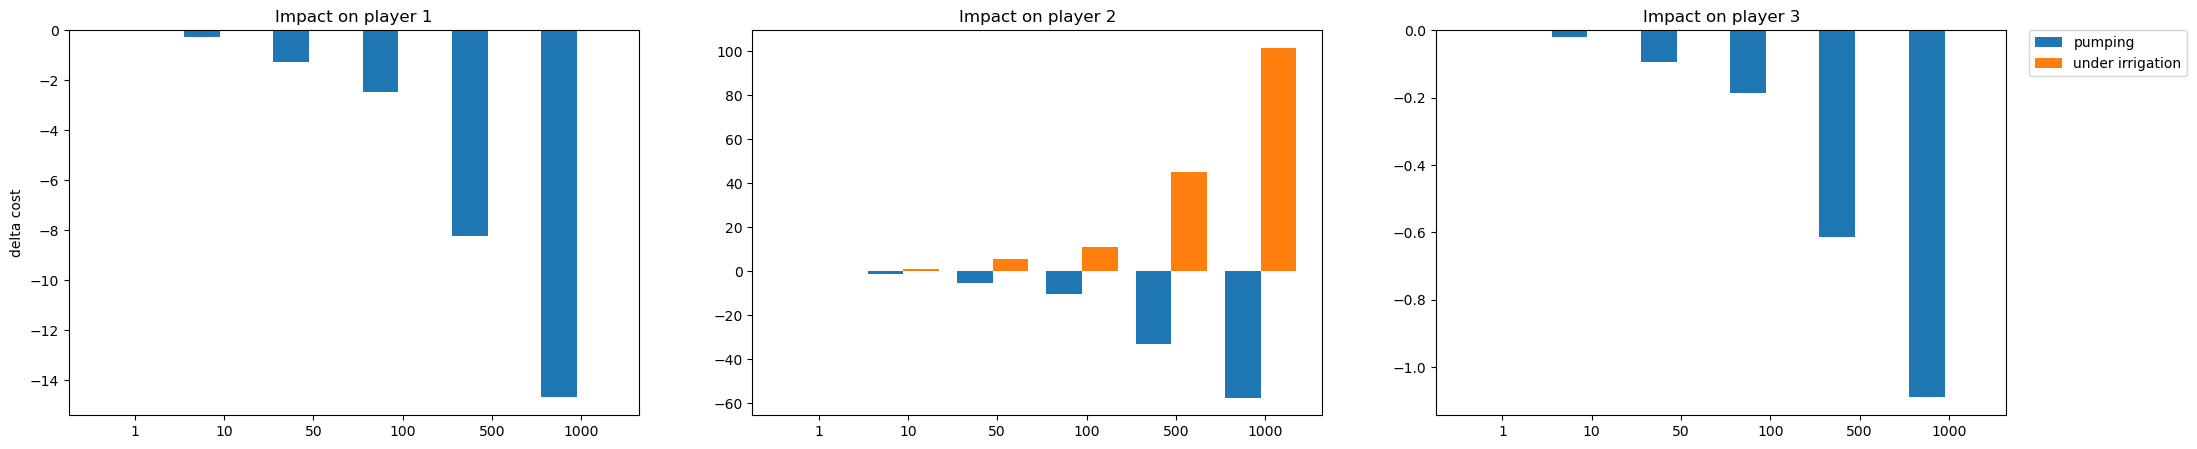

In [766]:
pump = 2

indices = 10* np.cumsum([0]+model.nu_v)
delta_pumps = np.array([1, 10, 50, 100, 500, 1000])
delta_p = np.zeros((len(delta_pumps), model.n_agent))
delta_i = np.zeros((len(delta_pumps), model.n_agent))
for i, delta_pump in enumerate(delta_pumps):
    n_u_v = model.nu_v[sorted(model.well_to_agent)[pump]]
    U_decr = U_opt.copy()
    for ts in range(horizon):
        U_decr[(pump_indices[pump][0]+ts*n_u_v):(pump_indices[pump][1]+ts*n_u_v)] = np.minimum(U_decr[(pump_indices[pump][0]+ts*n_u_v):(pump_indices[pump][1]+ts*n_u_v)] + delta_pump/np.count_nonzero(U_decr[(pump_indices[pump][0]+ts*n_u_v):(pump_indices[pump][1]+ts*n_u_v)]<-1), 0)
    for well in range(model.n_agent):
        delta_p[i, well]  = -(U_opt[indices[well]:indices[well+1],:].T @ R_p[indices[well]:indices[well+1],:] @ U_opt + x_0.T @ M_p[:,indices[well]:indices[well+1]] @ U_opt[indices[well]:indices[well+1],:] + L_p[:,indices[well]:indices[well+1]] @ U_opt[indices[well]:indices[well+1],:] -\
            (U_decr[indices[well]:indices[well+1],:].T @ R_p[indices[well]:indices[well+1],:] @ U_decr + x_0.T @ M_p[:,indices[well]:indices[well+1]] @ U_decr[indices[well]:indices[well+1],:] + L_p[:,indices[well]:indices[well+1]] @ U_decr[indices[well]:indices[well+1],:]))[0,0]
        delta_i[i, well]  = -(U_opt[indices[well]:indices[well+1],:].T @ R_i[indices[well]:indices[well+1],:] @ U_opt + x_0.T @ M_i[:,indices[well]:indices[well+1]] @ U_opt[indices[well]:indices[well+1],:] + L_i[:,indices[well]:indices[well+1]] @ U_opt[indices[well]:indices[well+1],:] -\
            (U_decr[indices[well]:indices[well+1],:].T @ R_i[indices[well]:indices[well+1],:] @ U_decr + x_0.T @ M_i[:,indices[well]:indices[well+1]] @ U_decr[indices[well]:indices[well+1],:] + L_i[:,indices[well]:indices[well+1]] @ U_decr[indices[well]:indices[well+1],:]))[0,0]

fig = plt.figure(figsize=(25,5))
for player in range(model.n_agent):
    ax = fig.add_subplot(1, model.n_agent, player+1)
    ttl = f"Impact on player {player+1}"
    ax.set_title(ttl)
    if player == 0:
        ax.set_ylabel("delta cost")
    rects = ax.bar(np.arange(len(delta_pumps)), delta_p[:,player], width=0.40, label="pumping")
    rects = ax.bar(np.arange(len(delta_pumps))+0.40, delta_i[:,player], width=0.40, label="under irrigation")
    ax.set_xticks(np.arange(len(delta_pumps))+0.25, delta_pumps.astype(str))
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

In [771]:
delta_i[:,1] + delta_p[:,1] + delta_p[:,0]

array([-2.56636205e-02, -2.46901880e-01, -1.02496458e+00, -1.54218055e+00,  3.81227450e+00,  2.93651235e+01])

In [774]:
delta_i[3,1], delta_p[3,1], delta_p[3,0], delta_i[3,1]+ delta_p[3,1]+ delta_p[3,0]

(np.float64(11.135215625616183),
 np.float64(-10.186943819715339),
 np.float64(-2.490452355792513),
 np.float64(-1.5421805498916683))

In [794]:
delta_pump = 130

U_decr = U_opt.copy()
for ts in range(horizon):
    if np.count_nonzero(U_decr[(pump_indices[pump][0]+ts*n_u_v):(pump_indices[pump][1]+ts*n_u_v)]<-1) == 0:
        continue
    U_decr[(pump_indices[pump][0]+ts*n_u_v):(pump_indices[pump][1]+ts*n_u_v)] = np.minimum(U_decr[(pump_indices[pump][0]+ts*n_u_v):(pump_indices[pump][1]+ts*n_u_v)] + delta_pump/np.count_nonzero(U_decr[(pump_indices[pump][0]+ts*n_u_v):(pump_indices[pump][1]+ts*n_u_v)]<-1), 0)
    
agent = 0
delta_p_1 = -(U_opt[indices[agent]:indices[agent+1],:].T @ R_p[indices[agent]:indices[agent+1],:] @ U_opt + x_0.T @ M_p[:,indices[agent]:indices[agent+1]] @ U_opt[indices[agent]:indices[agent+1],:] + L_p[:,indices[agent]:indices[agent+1]] @ U_opt[indices[agent]:indices[agent+1],:] -\
    (U_decr[indices[agent]:indices[agent+1],:].T @ R_p[indices[agent]:indices[agent+1],:] @ U_decr + x_0.T @ M_p[:,indices[agent]:indices[agent+1]] @ U_decr[indices[agent]:indices[agent+1],:] + L_p[:,indices[agent]:indices[agent+1]] @ U_decr[indices[agent]:indices[agent+1],:]))[0,0]
delta_i_1 = -(U_opt[indices[agent]:indices[agent+1],:].T @ R_i[indices[agent]:indices[agent+1],:] @ U_opt + x_0.T @ M_i[:,indices[agent]:indices[agent+1]] @ U_opt[indices[agent]:indices[agent+1],:] + L_i[:,indices[agent]:indices[agent+1]] @ U_opt[indices[agent]:indices[agent+1],:] -\
    (U_decr[indices[agent]:indices[agent+1],:].T @ R_i[indices[agent]:indices[agent+1],:] @ U_decr + x_0.T @ M_i[:,indices[agent]:indices[agent+1]] @ U_decr[indices[agent]:indices[agent+1],:] + L_i[:,indices[agent]:indices[agent+1]] @ U_decr[indices[agent]:indices[agent+1],:]))[0,0]

agent = 1
delta_p_2 = -(U_opt[indices[agent]:indices[agent+1],:].T @ R_p[indices[agent]:indices[agent+1],:] @ U_opt + x_0.T @ M_p[:,indices[agent]:indices[agent+1]] @ U_opt[indices[agent]:indices[agent+1],:] + L_p[:,indices[agent]:indices[agent+1]] @ U_opt[indices[agent]:indices[agent+1],:] -\
    (U_decr[indices[agent]:indices[agent+1],:].T @ R_p[indices[agent]:indices[agent+1],:] @ U_decr + x_0.T @ M_p[:,indices[agent]:indices[agent+1]] @ U_decr[indices[agent]:indices[agent+1],:] + L_p[:,indices[agent]:indices[agent+1]] @ U_decr[indices[agent]:indices[agent+1],:]))[0,0]
delta_i_2 = -(U_opt[indices[agent]:indices[agent+1],:].T @ R_i[indices[agent]:indices[agent+1],:] @ U_opt + x_0.T @ M_i[:,indices[agent]:indices[agent+1]] @ U_opt[indices[agent]:indices[agent+1],:] + L_i[:,indices[agent]:indices[agent+1]] @ U_opt[indices[agent]:indices[agent+1],:] -\
    (U_decr[indices[agent]:indices[agent+1],:].T @ R_i[indices[agent]:indices[agent+1],:] @ U_decr + x_0.T @ M_i[:,indices[agent]:indices[agent+1]] @ U_decr[indices[agent]:indices[agent+1],:] + L_i[:,indices[agent]:indices[agent+1]] @ U_decr[indices[agent]:indices[agent+1],:]))[0,0]

delta_p_1, delta_i_1, delta_p_2, delta_i_2, delta_p_1+ delta_i_1+ delta_p_2+ delta_i_2

(np.float64(-3.167007601208752),
 np.float64(-0.0),
 np.float64(-12.70240315402691),
 np.float64(14.220552037039397),
 np.float64(-1.6488587181962657))

### Change of scenario

Let's try with:
- Only one well for player 2 (so that in game has no other choice than pumping in this one)
- Varying yield sensitivity for both player

In [896]:
parameter_file_one_well = "Components/Setup/model_parameters_one_well.json"

In [897]:
model_one_well = IrrigationSchedulingModel(parameter_file_one_well, boundary_condition="Constant Head")
cost_model_one_well = IrrigationSchedulingCost(parameter_file_one_well, model_one_well, crops)

In [898]:
controller_one_well = TimeVaryingCost_LQRc_RHG(
    parameter_file_one_well,
    model_one_well.A.toarray(), [B.toarray() for B in model_one_well.B_v], model_one_well.C,
    model_one_well.H_x, model_one_well.h_x, model_one_well.H_u_v, model_one_well.h_u_v,
    model_one_well.H_xu_x, model_one_well.H_xu_u, model_one_well.h_xu,
    solver='fbrs'
)
welfare_one_well = LQRc_welfare(controller_one_well)

In [899]:
horizon = 30
Q, R, R_minus, M, L = cost_model_one_well.get_cost_matrices(200, horizon)
controller_one_well.update_cost_matrices(Q, R, R_minus, M, L)
U_opt_one_well, _ = controller_one_well._solve_problem(x_0)

In [900]:
welfare_one_well.update_cost_matrices(Q, R, R_minus, M, L)
U_welfare_one_well, _ = welfare_one_well._solve_problem(x_0)

In [901]:
(U_opt_one_well - U_welfare_one_well).min()

np.float64(-220.10339992714216)

In [902]:
(U_opt - U_welfare).min()

np.float64(-565.2839231454458)

In [903]:
def get_individual_cost_mat(m: IrrigationSchedulingCost, c: TimeVaryingCost_LQRc_RHG):
        # Only pumping cost (and regularization)
        reg = [1e-10 * np.eye(m.Rp_v[v].shape[0])
                for v in range(m.n_agent)]
        # Form matrices
        Q = None
        R = [[m.Rp_v[v] + reg[v] for t in range(horizon)]
                for v in range(m.n_agent)]
        R_minus = [[m.Rp_v_minus[v] for t in range(horizon)]
                        for v in range(m.n_agent)]
        M = [[m.Mp_v[v] for t in range(horizon)]
                for v in range(m.n_agent)]
        L = [[m.Lp_v[v] for t in range(horizon)]
                for v in range(m.n_agent)]

        c.update_cost_matrices(Q, R, R_minus, M, L)

        R_p_one_well = np.vstack([np.insert(c.R_v_minus_v[v], 10*(np.cumsum([0]+c.nu_v)[v]), c.R_vv[v].toarray().T, axis=1) for v in range(model.n_agent)])
        M_p_one_well = sp.hstack(c.M_x_v)
        L_p_one_well = sp.hstack(c.L_v_tilde)


        # Only under-irrigation (and regularization)
        m._compute_under_irrigation_cost_matrices(t, horizon)
        # Add regularization to R_v to ensure non-singularity
        reg = [1e-10 * np.eye(m.Rp_v[v].shape[0])
                for v in range(m.n_agent)]
        # Form matrices
        Q = None
        R = [[m.Ri_v[v][t] + reg[v] for t in range(horizon)]
                for v in range(m.n_agent)]
        R_minus = None
        M = None
        L = [[m.Li_v[v][t] for t in range(horizon)]
                for v in range(m.n_agent)]

        c.update_cost_matrices(Q, R, R_minus, M, L)

        R_i_one_well = np.vstack([np.insert(c.R_v_minus_v[v], 10*(np.cumsum([0]+c.nu_v)[v]), c.R_vv[v].toarray().T, axis=1) for v in range(model.n_agent)])
        M_i_one_well = sp.hstack(c.M_x_v)
        L_i_one_well = sp.hstack(c.L_v_tilde)
        
        return R_p_one_well, M_p_one_well, L_p_one_well, R_i_one_well, M_i_one_well, L_i_one_well

In [904]:
R_p_one_well, M_p_one_well, L_p_one_well, R_i_one_well, M_i_one_well, L_i_one_well = get_individual_cost_mat(cost_model_one_well, controller_one_well)

In [905]:
print(f"c_p(game) - c_p(welfare) = {U_opt_one_well.T @ R_p_one_well @ U_opt_one_well + x_0.T @ M_p_one_well @ U_opt_one_well + L_p_one_well @ U_opt_one_well} - {U_welfare_one_well.T @ R_p_one_well @ U_welfare_one_well + x_0.T @ M_p_one_well @ U_welfare_one_well + L_p_one_well @ U_welfare_one_well} = {U_opt_one_well.T @ R_p_one_well @ U_opt_one_well + x_0.T @ M_p_one_well @ U_opt_one_well + L_p_one_well @ U_opt_one_well - (U_welfare_one_well.T @ R_p_one_well @ U_welfare_one_well + x_0.T @ M_p_one_well @ U_welfare_one_well + L_p_one_well @ U_welfare_one_well)}")
print(f"c_i(game) - c_i(welfare) = {U_opt_one_well.T @ R_i_one_well @ U_opt_one_well + x_0.T @ M_i_one_well @ U_opt_one_well + L_i_one_well @ U_opt_one_well} - {U_welfare_one_well.T @ R_i_one_well @ U_welfare_one_well + x_0.T @ M_i_one_well @ U_welfare_one_well + L_i_one_well @ U_welfare_one_well} = {U_opt_one_well.T @ R_i_one_well @ U_opt_one_well + x_0.T @ M_i_one_well @ U_opt_one_well + L_i_one_well @ U_opt_one_well - (U_welfare_one_well.T @ R_i_one_well @ U_welfare_one_well + x_0.T @ M_i_one_well @ U_welfare_one_well + L_i_one_well @ U_welfare_one_well)}")
print(f"c(game)   - c(welfare)   = {U_opt_one_well.T @ R_i_one_well @ U_opt_one_well + x_0.T @ M_i_one_well @ U_opt_one_well + L_i_one_well @ U_opt_one_well + U_opt_one_well.T @ R_p_one_well @ U_opt_one_well + x_0.T @ M_p_one_well @ U_opt_one_well + L_p_one_well @ U_opt_one_well} - {U_welfare_one_well.T @ R_i_one_well @ U_welfare_one_well + x_0.T @ M_i_one_well @ U_welfare_one_well + L_i_one_well @ U_welfare_one_well + U_welfare_one_well.T @ R_p_one_well @ U_welfare_one_well + x_0.T @ M_p_one_well @ U_welfare_one_well + L_p_one_well @ U_welfare_one_well} =\
    {U_opt_one_well.T @ R_i_one_well @ U_opt_one_well + x_0.T @ M_i_one_well @ U_opt_one_well + L_i_one_well @ U_opt_one_well + U_opt_one_well.T @ R_p_one_well @ U_opt_one_well + x_0.T @ M_p_one_well @ U_opt_one_well + L_p_one_well @ U_opt_one_well - (U_welfare_one_well.T @ R_i_one_well @ U_welfare_one_well + x_0.T @ M_i_one_well @ U_welfare_one_well + L_i_one_well @ U_welfare_one_well + U_welfare_one_well.T @ R_p_one_well @ U_welfare_one_well + x_0.T @ M_p_one_well @ U_welfare_one_well + L_p_one_well @ U_welfare_one_well)}")

c_p(game) - c_p(welfare) = [[27809.86308885]] - [[27342.70526091]] = [[467.15782794]]
c_i(game) - c_i(welfare) = [[-219384.64169013]] - [[-218876.53339812]] = [[-508.10829201]]
c(game)   - c(welfare)   = [[-191574.77860129]] - [[-191533.82813721]] =    [[-40.95046407]]


In [906]:
print(f"c_p(game) - c_p(welfare) = {U_opt.T @ R_p @ U_opt + x_0.T @ M_p @ U_opt + L_p @ U_opt} - {U_welfare.T @ R_p @ U_welfare + x_0.T @ M_p @ U_welfare + L_p @ U_welfare} = {U_opt.T @ R_p @ U_opt + x_0.T @ M_p @ U_opt + L_p @ U_opt - (U_welfare.T @ R_p @ U_welfare + x_0.T @ M_p @ U_welfare + L_p @ U_welfare)}")
print(f"c_i(game) - c_i(welfare) = {U_opt.T @ R_i @ U_opt + x_0.T @ M_i @ U_opt + L_i @ U_opt} - {U_welfare.T @ R_i @ U_welfare + x_0.T @ M_i @ U_welfare + L_i @ U_welfare} = {U_opt.T @ R_i @ U_opt + x_0.T @ M_i @ U_opt + L_i @ U_opt - (U_welfare.T @ R_i @ U_welfare + x_0.T @ M_i @ U_welfare + L_i @ U_welfare)}")
print(f"c(game)   - c(welfare)   = {U_opt.T @ R_i @ U_opt + x_0.T @ M_i @ U_opt + L_i @ U_opt + U_opt.T @ R_p @ U_opt + x_0.T @ M_p @ U_opt + L_p @ U_opt} - {U_welfare.T @ R_i @ U_welfare + x_0.T @ M_i @ U_welfare + L_i @ U_welfare + U_welfare.T @ R_p @ U_welfare + x_0.T @ M_p @ U_welfare + L_p @ U_welfare} =\
    {U_opt.T @ R_i @ U_opt + x_0.T @ M_i @ U_opt + L_i @ U_opt + U_opt.T @ R_p @ U_opt + x_0.T @ M_p @ U_opt + L_p @ U_opt - (U_welfare.T @ R_i @ U_welfare + x_0.T @ M_i @ U_welfare + L_i @ U_welfare + U_welfare.T @ R_p @ U_welfare + x_0.T @ M_p @ U_welfare + L_p @ U_welfare)}")

c_p(game) - c_p(welfare) = [[10978.24201099]] - [[10933.0807814]] = [[45.16122959]]
c_i(game) - c_i(welfare) = [[-75365.05261402]] - [[-75325.53633264]] = [[-39.51628138]]
c(game)   - c(welfare)   = [[-64386.81060303]] - [[-64392.45555124]] =    [[5.64494821]]


In [907]:
(controller_one_well._solution_to_command(U_opt_one_well) - controller_one_well._solution_to_command(U_welfare_one_well)).round()

array([[ -68.,    0.,  -27.,    0.,  -53.,    0.,  -12.,    0., -220., -133.,    0.,    0.,  -51., -103.,  -38., -107.],
       [ -65.,    0.,  -26.,    0.,  -50.,    0.,  -11.,    0., -215., -130.,    0.,    0.,  -49.,  -99.,  -37., -103.],
       [ -62.,    0.,  -25.,    0.,  -47.,    0.,  -10.,    0., -210., -127.,    0.,    0.,  -48.,  -97.,  -36.,  -97.],
       [ -60.,    0.,  -25.,    0.,  -44.,    0.,   -9.,    0., -204., -124.,    0.,    0.,  -47.,  -95.,  -35.,  -92.],
       [ -59.,    0.,  -25.,    0.,  -41.,    0.,   -7.,    0., -199., -121.,    0.,    0.,  -47.,  -94.,  -35.,  -87.],
       [ -56.,    0.,  -24.,    0.,  -39.,    0.,   -7.,    0., -190., -172.,    0.,    0.,  -54.,    0.,  -40.,  -96.],
       [ -56.,    0.,  -17.,    0.,  -41.,    0.,   -2.,    0., -205.,  -85.,    0.,    0.,  -53.,    0.,  -26.,  -91.],
       [ -53.,    0.,  -16.,    0.,  -38.,    0.,   -2.,    0., -191., -173.,    0.,    0.,  -51.,    0.,  -25.,  -83.],
       [ -49.,    0.,  -16.,    

#### Test different yield sensitivity for player 1

In [841]:
yield_sensitivity_init = cost_model_one_well.yield_sensitivity.copy()

In [870]:
delta_cost_yield = np.zeros((9,9))

for s_1 in range(1, 10):
    for s_2 in range(1, 10):
        cost_model_one_well.yield_sensitivity[0, 1] = s_1/10
        cost_model_one_well.yield_sensitivity[1, 1] = s_2/10
        # Game
        Q, R, R_minus, M, L = cost_model_one_well.get_cost_matrices(200, 10)
        controller_one_well.update_cost_matrices(Q, R, R_minus, M, L)
        U_opt_one_well, _ = controller_one_well._solve_problem(x_0)
        # Welfare
        welfare_one_well.update_cost_matrices(Q, R, R_minus, M, L)
        U_welfare_one_well, _ = welfare_one_well._solve_problem(x_0)
        
        R_p_one_well, M_p_one_well, L_p_one_well, R_i_one_well, M_i_one_well, L_i_one_well = get_individual_cost_mat(cost_model_one_well, controller_one_well)
        
        delta_cost_yield[s_1-1, s_2-1] = (U_opt_one_well.T @ R_i_one_well @ U_opt_one_well + x_0.T @ M_i_one_well @ U_opt_one_well + L_i_one_well @ U_opt_one_well + U_opt_one_well.T @ R_p_one_well @ U_opt_one_well + x_0.T @ M_p_one_well @ U_opt_one_well + L_p_one_well @ U_opt_one_well - \
            (U_welfare_one_well.T @ R_i_one_well @ U_welfare_one_well + x_0.T @ M_i_one_well @ U_welfare_one_well + L_i_one_well @ U_welfare_one_well + U_welfare_one_well.T @ R_p_one_well @ U_welfare_one_well + x_0.T @ M_p_one_well @ U_welfare_one_well + L_p_one_well @ U_welfare_one_well))[0,0]

In [871]:
delta_cost_yield.max(), delta_cost_yield.min()

(np.float64(5.9163734814865165), np.float64(0.9931279386219103))

In [872]:
cost_model_one_well.yield_sensitivity = yield_sensitivity_init.copy()

In [873]:
delta_cost_yield_1 = np.zeros((9,9))

for s_1 in range(1, 10):
    for s_2 in range(1, 10):
        cost_model_one_well.yield_sensitivity[0, 0] = s_1/10
        cost_model_one_well.yield_sensitivity[2, 0] = s_2/10
        # Game
        Q, R, R_minus, M, L = cost_model_one_well.get_cost_matrices(200, 10)
        controller_one_well.update_cost_matrices(Q, R, R_minus, M, L)
        U_opt_one_well, _ = controller_one_well._solve_problem(x_0)
        # Welfare
        welfare_one_well.update_cost_matrices(Q, R, R_minus, M, L)
        U_welfare_one_well, _ = welfare_one_well._solve_problem(x_0)
        
        R_p_one_well, M_p_one_well, L_p_one_well, R_i_one_well, M_i_one_well, L_i_one_well = get_individual_cost_mat(cost_model_one_well, controller_one_well)
        
        delta_cost_yield_1[s_1-1, s_2-1] = (U_opt_one_well.T @ R_i_one_well @ U_opt_one_well + x_0.T @ M_i_one_well @ U_opt_one_well + L_i_one_well @ U_opt_one_well + U_opt_one_well.T @ R_p_one_well @ U_opt_one_well + x_0.T @ M_p_one_well @ U_opt_one_well + L_p_one_well @ U_opt_one_well - \
            (U_welfare_one_well.T @ R_i_one_well @ U_welfare_one_well + x_0.T @ M_i_one_well @ U_welfare_one_well + L_i_one_well @ U_welfare_one_well + U_welfare_one_well.T @ R_p_one_well @ U_welfare_one_well + x_0.T @ M_p_one_well @ U_welfare_one_well + L_p_one_well @ U_welfare_one_well))[0,0]

In [874]:
delta_cost_yield_1.max(), delta_cost_yield_1.min()

(np.float64(3.2150459063559538), np.float64(0.9428162523581705))

In [875]:
np.argsort(delta_cost_yield_1.flatten())

array([ 0,  9, 10,  1, 18, 11,  2, 27, 12,  3,  4, 13, 36, 19,  5, 14, 15,  6, 45,  7, 16, 17,  8, 54, 20, 63, 21, 72, 28, 22, 23, 24, 25, 26, 29, 37, 30, 46, 31, 32, 38, 33, 55, 34, 35, 39, 64, 47, 40, 73, 41, 42, 56, 48, 43, 44, 49, 65, 57, 50, 74, 51, 52, 58, 53, 66, 59, 60, 75, 67, 61, 62, 68, 76, 69, 70, 77, 71, 78, 79, 80])

In [877]:
delta_cost_yield_1.flatten()[np.argsort(delta_cost_yield_1.flatten())[-10:]]

array([2.95982958, 2.97020282, 3.00078249, 3.02430153, 3.06600001, 3.07818167, 3.09912076, 3.1355924 , 3.17986601, 3.21504591])

In [879]:
np.unravel_index(np.argsort(delta_cost_yield_1.flatten())[-10:], delta_cost_yield_1.shape)

(array([6, 7, 8, 7, 7, 8, 7, 8, 8, 8]), array([8, 5, 4, 6, 7, 5, 8, 6, 7, 8]))

In [880]:
delta_cost_yield.flatten()[np.argsort(delta_cost_yield.flatten())[-10:]]

array([4.57388809, 4.79864154, 5.13437331, 5.17098346, 5.21765217, 5.27918576, 5.36403363, 5.48854847, 5.59971217, 5.91637348])

In [881]:
np.unravel_index(np.argsort(delta_cost_yield.flatten())[-10:], delta_cost_yield.shape)

(array([1, 0, 0, 0, 0, 0, 0, 0, 0, 0]), array([1, 0, 8, 7, 6, 5, 4, 3, 2, 1]))

In [ ]:
crops

array([[0.4, 0.4, 0.3],
       [0. , 0.2, 0.3],
       [0.6, 0. , 0.3],
       [0. , 0. , 0.4]])

In [867]:
yield_sensitivity_init

array([[0.6, 0.4, 0.8],
       [0. , 0.5, 0.3],
       [0.7, 0. , 0.4],
       [0. , 0. , 0.3]])

In [909]:
cost_model_one_well.yield_sensitivity = yield_sensitivity_init.copy()
cost_model_one_well.yield_sensitivity[0, 0] = 0.8
cost_model_one_well.yield_sensitivity[2, 0] = 0.8
cost_model_one_well.yield_sensitivity[0, 1] = 0.2
cost_model_one_well.yield_sensitivity[1, 1] = 0.4

# Game
Q, R, R_minus, M, L = cost_model_one_well.get_cost_matrices(200, horizon)
controller_one_well.update_cost_matrices(Q, R, R_minus, M, L)
U_opt_one_well, _ = controller_one_well._solve_problem(x_0)
# Welfare
welfare_one_well.update_cost_matrices(Q, R, R_minus, M, L)
U_welfare_one_well, _ = welfare_one_well._solve_problem(x_0)

R_p_one_well, M_p_one_well, L_p_one_well, R_i_one_well, M_i_one_well, L_i_one_well = get_individual_cost_mat(cost_model_one_well, controller_one_well)

print(f"c_p(game) - c_p(welfare) = {U_opt.T @ R_p @ U_opt + x_0.T @ M_p @ U_opt + L_p @ U_opt} - {U_welfare.T @ R_p @ U_welfare + x_0.T @ M_p @ U_welfare + L_p @ U_welfare} = {U_opt.T @ R_p @ U_opt + x_0.T @ M_p @ U_opt + L_p @ U_opt - (U_welfare.T @ R_p @ U_welfare + x_0.T @ M_p @ U_welfare + L_p @ U_welfare)}")
print(f"c_i(game) - c_i(welfare) = {U_opt.T @ R_i @ U_opt + x_0.T @ M_i @ U_opt + L_i @ U_opt} - {U_welfare.T @ R_i @ U_welfare + x_0.T @ M_i @ U_welfare + L_i @ U_welfare} = {U_opt.T @ R_i @ U_opt + x_0.T @ M_i @ U_opt + L_i @ U_opt - (U_welfare.T @ R_i @ U_welfare + x_0.T @ M_i @ U_welfare + L_i @ U_welfare)}")
print(f"c(game)   - c(welfare)   = {U_opt.T @ R_i @ U_opt + x_0.T @ M_i @ U_opt + L_i @ U_opt + U_opt.T @ R_p @ U_opt + x_0.T @ M_p @ U_opt + L_p @ U_opt} - {U_welfare.T @ R_i @ U_welfare + x_0.T @ M_i @ U_welfare + L_i @ U_welfare + U_welfare.T @ R_p @ U_welfare + x_0.T @ M_p @ U_welfare + L_p @ U_welfare} =\
    {U_opt.T @ R_i @ U_opt + x_0.T @ M_i @ U_opt + L_i @ U_opt + U_opt.T @ R_p @ U_opt + x_0.T @ M_p @ U_opt + L_p @ U_opt - (U_welfare.T @ R_i @ U_welfare + x_0.T @ M_i @ U_welfare + L_i @ U_welfare + U_welfare.T @ R_p @ U_welfare + x_0.T @ M_p @ U_welfare + L_p @ U_welfare)}")

c_p(game) - c_p(welfare) = [[10978.24201099]] - [[10933.0807814]] = [[45.16122959]]
c_i(game) - c_i(welfare) = [[-75365.05261402]] - [[-75325.53633264]] = [[-39.51628138]]
c(game)   - c(welfare)   = [[-64386.81060303]] - [[-64392.45555124]] =    [[5.64494821]]


In [912]:
(controller_one_well._solution_to_command(U_opt_one_well) - controller_one_well._solution_to_command(U_welfare_one_well)).round()

array([[ -50.,    0.,  -24.,    0.,  -32.,    0.,   -6.,    0., -422., -160.,    0.,    0.,  -52., -106.,  -39., -111.],
       [ -47.,    0.,  -23.,    0.,  -29.,    0.,   -5.,    0., -410., -155.,    0.,    0.,  -50., -102.,  -38., -107.],
       [ -46.,    0.,  -23.,    0.,  -27.,    0.,   -4.,    0., -399., -151.,    0.,    0.,  -49., -100.,  -37., -100.],
       [ -44.,    0.,  -23.,    0.,  -25.,    0.,   -3.,    0., -389., -147.,    0.,    0.,  -48.,  -98.,  -36.,  -94.],
       [ -43.,    0.,  -23.,    0.,  -22.,    0.,   -2.,    0., -378., -143.,    0.,    0.,  -48.,  -97.,  -36.,  -89.],
       [ -41.,    0.,  -22.,    0.,  -20.,    0.,   -1.,    0., -359., -203.,    0.,    0.,  -55.,    0.,  -41.,  -99.],
       [ -40.,    0.,  -17.,    0.,  -21.,    0.,    2.,    0., -380.,  -39.,    0.,    0.,  -55.,    0.,  -26.,  -93.],
       [ -38.,    0.,  -16.,    0.,  -20.,    0.,    2.,    0., -360., -204.,    0.,    0.,  -52.,    0.,  -25.,  -85.],
       [ -36.,    0.,  -15.,    

In [927]:
controller_one_well._solution_to_command(U_welfare_one_well).round()

array([[-3.744e+03, -0.000e+00, -9.037e+03, -0.000e+00, -3.804e+03, -0.000e+00, -9.097e+03, -0.000e+00, -9.190e+02, -5.390e+02, -0.000e+00, -0.000e+00, -3.340e+03, -7.880e+02, -3.633e+03, -2.549e+03],
       [-3.729e+03, -0.000e+00, -9.033e+03, -0.000e+00, -3.785e+03, -0.000e+00, -9.089e+03, -0.000e+00, -9.260e+02, -5.420e+02, -0.000e+00, -0.000e+00, -3.327e+03, -7.620e+02, -3.623e+03, -2.521e+03],
       [-3.727e+03, -0.000e+00, -9.034e+03, -0.000e+00, -3.777e+03, -0.000e+00, -9.084e+03, -0.000e+00, -9.320e+02, -5.440e+02, -0.000e+00, -0.000e+00, -3.330e+03, -7.680e+02, -3.625e+03, -2.429e+03],
       [-3.730e+03, -0.000e+00, -9.036e+03, -0.000e+00, -3.776e+03, -0.000e+00, -9.083e+03, -0.000e+00, -9.380e+02, -5.460e+02, -0.000e+00, -0.000e+00, -3.337e+03, -7.830e+02, -3.631e+03, -2.345e+03],
       [-3.738e+03, -0.000e+00, -9.040e+03, -0.000e+00, -3.783e+03, -0.000e+00, -9.085e+03, -0.000e+00, -9.440e+02, -5.490e+02, -0.000e+00, -0.000e+00, -3.349e+03, -8.070e+02, -3.639e+03, -2.267e+

In [922]:
cost_model_one_well._get_water_requirement(200, horizon+5)

array([[[14400.        , 14400.        , 14400.        , 14400.        , 14400.        , 14400.        ,  6896.        , 14400.        , 14400.        , 14400.        , 14400.        , 14400.        , 14160.        , 13920.        , 13680.        , 13440.        , 13200.        , 12960.        , 12720.        , 12480.        , 12240.        , 12000.        , 11760.        , 11520.        ,     0.        ,     0.        , 10472.        ,     0.        ,     0.        ,     0.        ,     0.        ,     0.        ,     0.        ,   980.55      ,  8880.        ],
        [    0.        ,     0.        ,     0.        ,     0.        ,     0.        ,     0.        ,     0.        ,     0.        ,     0.        ,     0.        ,     0.        ,     0.        ,     0.        ,     0.        ,     0.        ,     0.        ,     0.        ,     0.        ,     0.        ,     0.        ,     0.        ,     0.        ,     0.        ,     0.        ,     0.        ,     0.        ,     0

In [928]:
n_well

5

# Test one well for player 2 on one entire simulation

In [ ]:
water_req = cost_model_one_well._get_water_requirement(0, 365)
under_irrigation_weight = cost_model_one_well._get_under_irrigation_weight(0, 365)

In [ ]:
n_well = int(sum(np.hstack(model_one_well.n_well_per_command)))
well_to_agent = np.zeros((model_one_well.n_agent, n_well))
indices = np.array(list(zip(model_one_well.well_to_agent.tolist(), range(n_well)))).T
well_to_agent[indices[0, :], indices[1, :]] = 1

In [966]:
data_si = np.load("run_data/run_20250701-163126/result_data.npz")
data_wf = np.load("run_data/run_20250701-165240/result_data.npz")

In [967]:
player_pumping_si = well_to_agent @ data_si['q_rates']
player_pumping_wf = well_to_agent @ data_wf['q_rates']
rain = cost_model._get_available_water(0, 365)

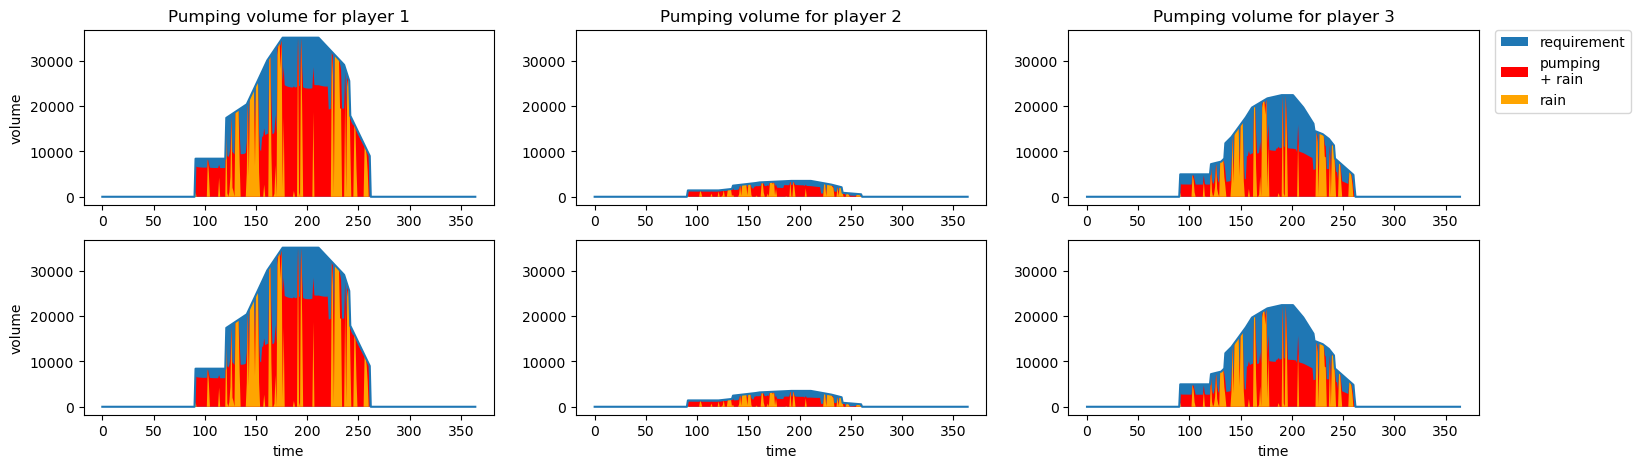

In [ ]:
fig = plt.figure(figsize=(15+3,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(2, 3, ii+1, sharey=ax)
    ttl = f"Pumping volume for player {ii+1}"
    ax.set_title(ttl)
    if ii == 0:
        ax.set_ylabel("volume")
    ax.plot((water_req+rain)[ii, :, :].sum(axis=0))
    ax.fill((water_req+rain)[ii, :, :].sum(axis=0), label='requirement')
    ax.fill(-player_pumping_si[ii, :] + rain[ii,:,:].sum(axis=0), "r-", label='pumping\n+ rain')
    ax.fill(rain[ii,:,:].sum(axis=0), "orange", label='rain')
    if ii == 2:
        ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
    # Welfare
    ax = fig.add_subplot(2, 3, 3+ii+1, sharey=ax)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("volume")
    ax.plot((water_req+rain)[ii, :, :].sum(axis=0))
    ax.fill((water_req+rain)[ii, :, :].sum(axis=0))
    ax.fill(-player_pumping_wf[ii, :] + rain[ii,:,:].sum(axis=0), "r-")
    ax.fill(rain[ii,:,:].sum(axis=0), "orange")

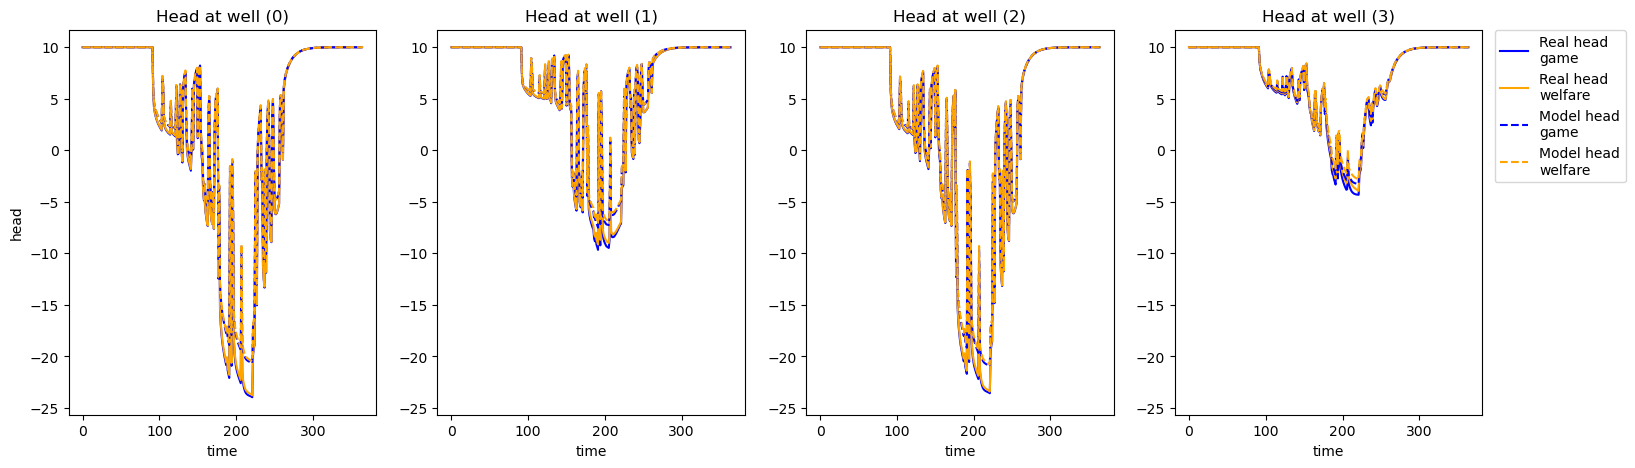

In [970]:
# Display heads evolution
fig_h = plt.figure(figsize=(20+3,5))
ax_h = None
for ii in range(4):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Head at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    ax_h.plot(data_si['h_wells'][ii, :], "b-", label="Real head\ngame")
    ax_h.plot(data_wf['h_wells'][ii, :], color="orange", label="Real head\nwelfare")
    ax_h.plot(data_si['corrected_h_wells'][ii, :], "b--", label="Model head\ngame")
    ax_h.plot(data_wf['corrected_h_wells'][ii, :], color="orange", linestyle="--", label="Model head\nwelfare")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

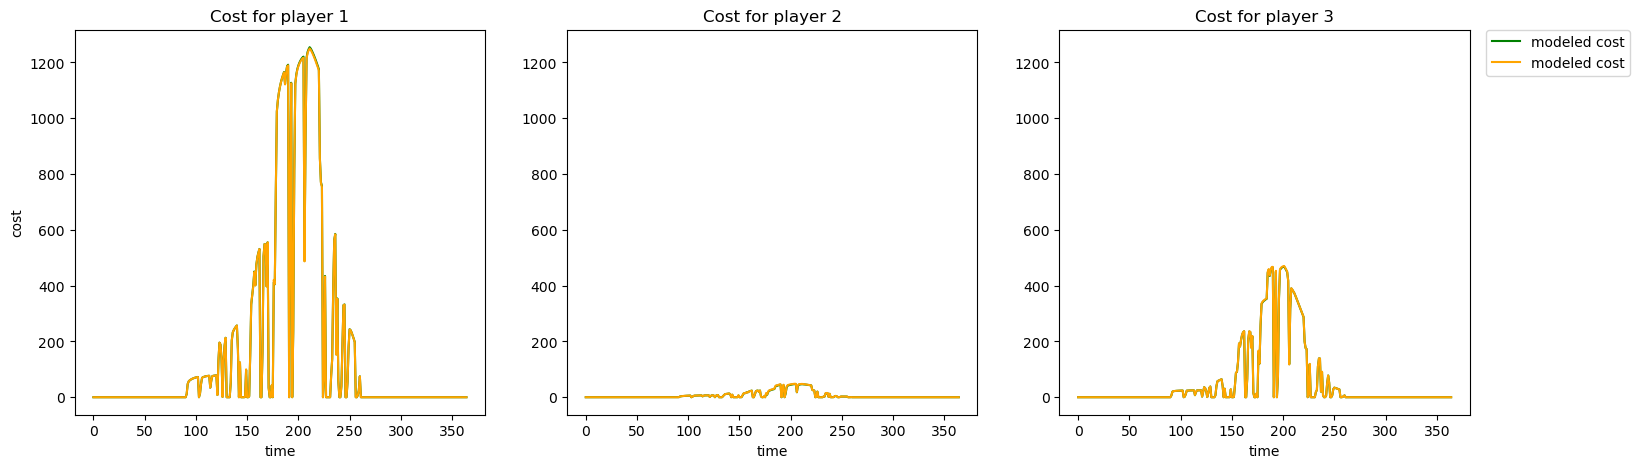

In [971]:
fig = plt.figure(figsize=(15+3,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Cost for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(-data_si['model_profit'][ii, :], 'g', label='modeled cost')
    ax.plot(-data_wf['model_profit'][ii, :], color="orange", label='modeled cost')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

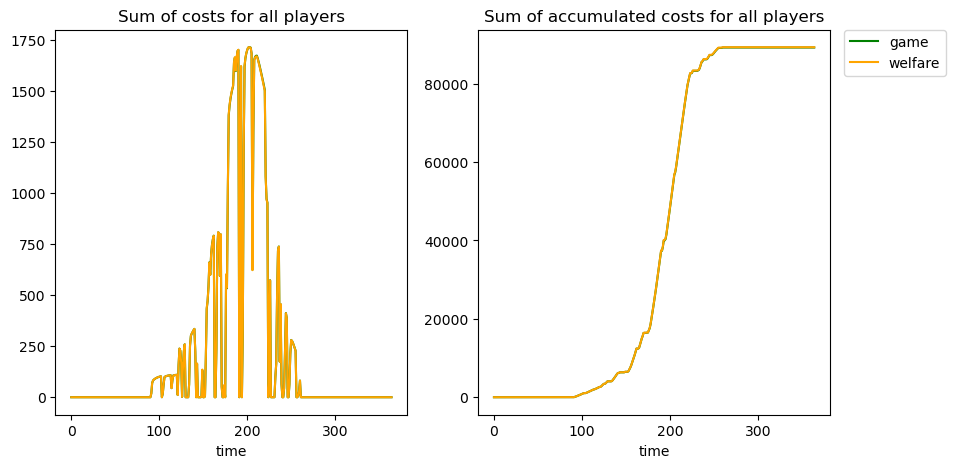

In [972]:
fig = plt.figure(figsize=(10,5))
ax = fig.add_subplot(1, 2, 1)
ttl = f"Sum of costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("cost")
ax.plot(-data_si['model_profit'].sum(axis=0), 'g')
ax.plot(-data_wf['model_profit'].sum(axis=0), color="orange")

ax = fig.add_subplot(1, 2, 2)
ttl = f"Sum of accumulated costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("cost")
ax.plot(-np.cumsum(data_si['model_profit'].sum(axis=0)), 'g', label='game')
ax.plot(-np.cumsum(data_wf['model_profit'].sum(axis=0)), color="orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

In [974]:
u_si = np.array([model_one_well.reorganize_input_per_well(data_si['inputs'][:,[k]]) for k in range(365)]).T
u_si = u_si.reshape((np.hstack(cost_model_one_well.n_well_per_command).sum(dtype=int), cost_model_one_well.n_crops, 365))
u_wf = np.array([model_one_well.reorganize_input_per_well(data_wf['inputs'][:,[k]]) for k in range(365)]).T
u_wf = u_wf.reshape((np.hstack(cost_model_one_well.n_well_per_command).sum(dtype=int), cost_model_one_well.n_crops, 365))

In [975]:
pumping_cost_si = np.zeros((cost_model_one_well.n_agent, 365))
under_irrigation_cost_si = np.zeros((cost_model_one_well.n_agent, 365))
pumping_cost_wf = np.zeros((cost_model_one_well.n_agent, 365))
under_irrigation_cost_wf = np.zeros((cost_model_one_well.n_agent, 365))
for v_1 in range(cost_model_one_well.n_agent):
    input_indices = np.nonzero(cost_model_one_well.well_to_cell[:,cost_model_one_well.well_to_agent==v_1].T)[1]
    well_index = np.arange(np.hstack(model_one_well.n_well_per_command).sum(), dtype=int)[model_one_well.well_to_agent==v_1]
    for t in range(364):
        pumping_cost_si[v_1,t] = (-cost_model_one_well.extraction_cost[v_1] * (cost_model_one_well.top_head[input_indices] -\
            data_si['h_wells'][[well_index], t+1].T) * u_si[cost_model_one_well.well_to_agent==v_1,:,t].sum(axis=1).reshape(-1,1)).sum()
        under_irrigation = water_req[v_1, :, t] + u_si[cost_model_one_well.well_to_agent==v_1,:,t].sum(axis=0)    # TODO: check dimensions
        under_irrigation_cost_si[v_1,t] = \
            under_irrigation.T @ sp.diags(under_irrigation_weight[v_1,:,t].flatten()) @ under_irrigation.T
        # Welfare costs
        pumping_cost_wf[v_1,t] = (-cost_model_one_well.extraction_cost[v_1] * (cost_model_one_well.top_head[input_indices] -\
            data_wf['h_wells'][[well_index], t+1].T) * u_wf[cost_model_one_well.well_to_agent==v_1,:,t].sum(axis=1).reshape(-1,1)).sum()
        under_irrigation = water_req[v_1, :, t] + u_wf[cost_model_one_well.well_to_agent==v_1,:,t].sum(axis=0)    # TODO: check dimensions
        under_irrigation_cost_wf[v_1,t] = \
            under_irrigation.T @ sp.diags(under_irrigation_weight[v_1,:,t].flatten()) @ under_irrigation.T
cost_si = pumping_cost_si + under_irrigation_cost_si
cost_wf = pumping_cost_wf + under_irrigation_cost_wf

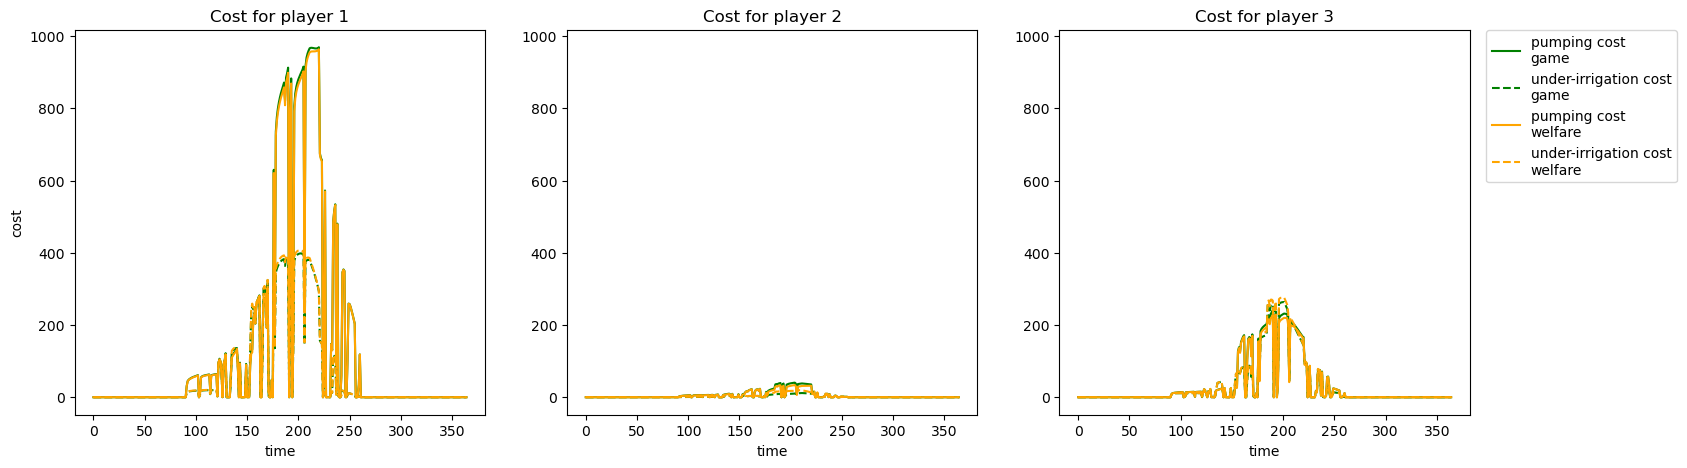

In [976]:
fig = plt.figure(figsize=(15+3,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Cost for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(pumping_cost_si[ii, :], 'g', label='pumping cost\ngame')
    ax.plot(under_irrigation_cost_si[ii, :], 'g--', label='under-irrigation cost\ngame')
    ax.plot(pumping_cost_wf[ii, :], color="orange", label='pumping cost\nwelfare')
    ax.plot(under_irrigation_cost_wf[ii, :], color="orange", linestyle="--", label='under-irrigation cost\nwelfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

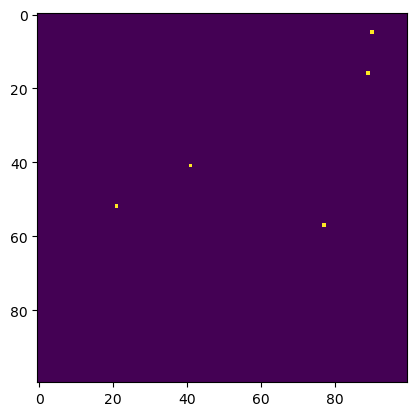

In [965]:
field = np.zeros((100, 100))

n_well_1 = 2
n_well_2 = 2
n_well_3 = 1

x_1 = np.random.randint(0,100,   (n_well_1,1))
y_1 = np.random.randint(0,100/2, (n_well_1,1))
field[x_1, y_1] = 1

x_2 = np.random.randint(0,100/4,   (n_well_2,1))
y_2 = np.random.randint(100/2, 100, (n_well_2,1))
field[x_2, y_2] = 1

x_3 = np.random.randint(100/4, 100,   (n_well_3,1))
y_3 = np.random.randint(100/2, 100, (n_well_3,1))
field[x_3, y_3] = 1

# for n_well_1 in range(1,4):
#     for n_well_2 in range(1,4):
#         for n_well_3 in range(1,4):
plt.imshow(field)

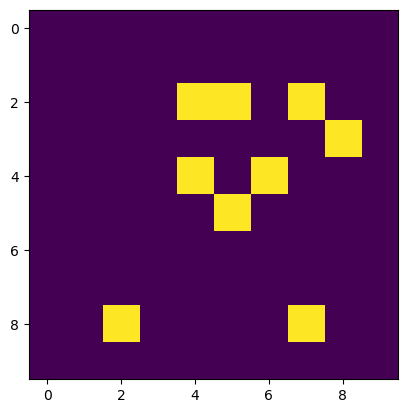

In [14]:
field = np.zeros((10, 10))

field[4,4] = 1
field[2,5] = 1
field[8,2] = 1

field[4,6] = 1
field[2,4] = 1
field[2,7] = 1

field[5,5] = 1
field[8,7] = 1
field[3,8] = 1

plt.imshow(field)

In [43]:
import itertools

wells_position = [[[0, 490, 490], [0, 260, 250], [0, 820, 210]],
                      [[0, 450, 625], [0, 250, 700], [0, 270, 430]],
                      [[0, 800, 700], [0, 550, 580], [0, 380, 810]]]
well_combinations = []
for wells in wells_position:
    well_combinations_v = [wells]
    for i, well in enumerate(wells):
        well_combinations_v.append([well])
        well_combinations_v.append(wells[:i]+wells[i+1:])
    well_combinations.append(well_combinations_v)
print(list(itertools.product(*well_combinations))[-6])
print([el for el_v in list(itertools.product(*well_combinations))[-6] for el in el_v])


([[0, 490, 490], [0, 260, 250]], [[0, 450, 625], [0, 250, 700]], [[0, 800, 700]])
[[0, 490, 490], [0, 260, 250], [0, 450, 625], [0, 250, 700], [0, 800, 700]]


In [82]:
[[i]*len(elt) for i, elt in enumerate(list(itertools.product(*well_combinations))[-6])]

[[0, 0], [1, 1], [2]]

In [ ]:
import json

with open('Components/Setup/model_parameters_combination.json', 'r+') as f:
    data = json.load(f)
    data['wells']['pos'] = [el for el_v in list(itertools.product(*well_combinations))[-6] for el in el_v]
    f.seek(0)        # <--- should reset file position to the beginning.
    json.dump(data, f, indent=4)
    f.truncate()     # remove remaining part

In [61]:
rd = np.random.rand(len(wells)*(4+1)).reshape((4+1), len(wells))
print(rd)
print((rd/rd.sum(axis=0)))
print((rd/rd.sum(axis=0)).round(1)[:-1,:])

[[0.73999214 0.03068744 0.83632518]
 [0.04193162 0.4207154  0.91463823]
 [0.72557304 0.53895892 0.26674825]
 [0.06839381 0.13079173 0.24478095]
 [0.87754225 0.26034443 0.60896669]]
[[0.30161499 0.02221316 0.29125441]
 [0.017091   0.30453567 0.31852732]
 [0.29573788 0.39012648 0.09289641]
 [0.02787678 0.09467385 0.08524619]
 [0.35767934 0.18845083 0.21207568]]
[[0.3 0.  0.3]
 [0.  0.3 0.3]
 [0.3 0.4 0.1]
 [0.  0.1 0.1]]


# Special well configuration

In [20]:
tuple((wells/100).astype(int).T.tolist())

([4, 5, 7, 3, 2, 4, 2, 7, 5], [4, 5, 2, 2, 5, 6, 7, 6, 8])

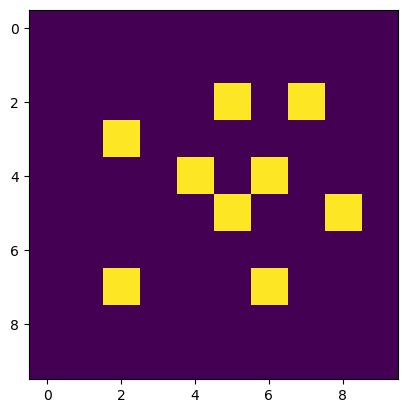

In [21]:
wells = np.array([[490, 490], [550, 580],
                  [720, 210], [370, 230], [260, 550],
                  [450, 625], [250, 700], [700, 600], [580, 810]])

field = np.zeros((10, 10))

field[tuple((wells/100).astype(int).T.tolist())] = 1

plt.imshow(field)

In [26]:
data_si = np.load("run_data/run_20250709-171655/result_data.npz")
data_wf = np.load("run_data/run_20250709-171835/result_data.npz")

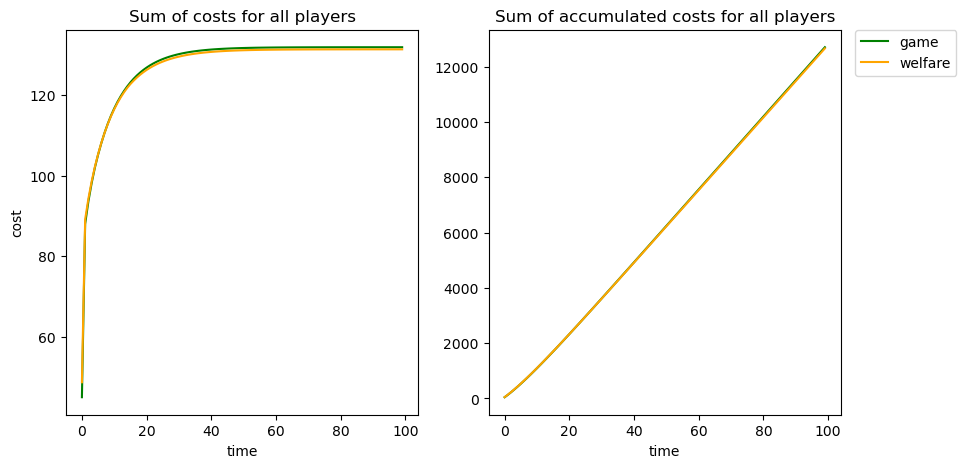

In [27]:
fig = plt.figure(figsize=(10,5))
ax = fig.add_subplot(1, 2, 1)
ttl = f"Sum of costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
ax.set_ylabel("cost")
ax.plot(-data_si['model_profit'].sum(axis=0), 'g')
ax.plot(-data_wf['model_profit'].sum(axis=0), color="orange")

ax = fig.add_subplot(1, 2, 2)
ttl = f"Sum of accumulated costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
ax.plot(-np.cumsum(data_si['model_profit'].sum(axis=0)), 'g', label='game')
ax.plot(-np.cumsum(data_wf['model_profit'].sum(axis=0)), color="orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)